# Doomscroll: An Exploratory Analysis of Short-Video Recommendation Behaviour

**Course:** Exploratory Data Analysis  
**Project:** End-to-end EDA and modelling of the KuaiSAR-v2 short-video dataset  
**Repository:** `https://github.com/1ens0r/doomscroll`

| Field | Detail |
|---|---|
| Student name | _[Your Name]_ |
| Registration / roll number | _[Your Registration Number]_ |
| Programme | _[Programme, e.g. B.Tech CSE]_ |
| Faculty / school | _[Faculty / School]_ |
| Course code | _[Course Code]_ |
| Submission date | 24 October 2026 |
| Notebook | `Doomscroll_EDA_Report.ipynb` |
| Data | KuaiSAR-v2 raw CSVs (3.5 GB), read locally and **not redistributed** |
| Random seed | 42 |

> Replace the five bracketed identity fields above before submission. All numbers, tables, figures and model evaluations below are produced by executing this notebook on the repository data.

## Abstract

This report studies **19.66 million raw short-video interactions** from the KuaiSAR-v2 dataset, collected from 25,877 users over 18 days on a real short-video platform. The analysis follows the fifteen-step exploratory-data-analysis process required by the course. After deduplication and a 5-user / 3-item k-core filter, **13.06 million interactions** covering **25,865 users** and **1,303,360 items** remain. The report documents the data dictionary, provenance, pipeline, data-quality audit, cleaning log, univariate and multivariate structure, feature viability, cold-start drift, and the modelling choices that follow from those findings.

The EDA shows that the platform is extremely long-tailed: a small share of users generates a large share of impressions, item popularity follows a heavy-tailed rank-frequency law, and engagement rises with the KuaiSAR relevance tier. Roughly half of all k-core impressions are tier 0 (no click and no long view), while tier 2 (long view without click) accounts for 3.7%. Search is a minority channel (25.5% of raw rows) but has a sharply different tier profile from the feed. These descriptive facts motivate the project's ranking model and its simulator, which are reported after the EDA as a clearly labelled extension. The shipped model achieves NDCG@10 of **0.5143** on validation and **0.5332** on test, versus **0.4976** for a popularity baseline on test. The simulated policy ladder closes **59%** of the personalised-oracle gap. All results are reproducible with seed 42 and the pinned environment recorded below.

## Reproducibility and environment

The notebook is designed to run from the repository root. It discovers the `recommender-engine` directory whether the working directory is the repository root or the engine directory, inserts it on `sys.path`, and records the execution timestamp, git commit, Python version and the exact versions of the scientific stack. The project uses CPU-only PyTorch; no GPU is required. A single `RANDOM_SEED = 42` is used everywhere (split construction, training, bootstrap and simulation), and the split is time-based so that no future interaction leaks into the past.

**Runtime expectation:** raw ingestion and k-core take roughly 25 seconds and about 3.5 GB of RAM; figures add about one minute; the short training demonstration adds about one minute; full evaluation of the shipped checkpoint is roughly 30 seconds. The complete notebook is intended to execute in under six minutes on a 16-core CPU machine.

In [1]:
import os, sys, json, time, math, gc, warnings, platform, random, inspect, copy, subprocess
from pathlib import Path

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "recommender-engine" / "feed").is_dir():
            return p
    raise RuntimeError("Could not locate repository root containing recommender-engine/feed")

ROOT = find_root()
ENGINE = ROOT / "recommender-engine"
sys.path.insert(0, str(ENGINE))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import torch
from scipy import stats
from scipy.stats import chi2_contingency, kruskal
from sklearn.metrics import roc_auc_score
from sklearn.decomposition import PCA
from IPython.display import display, Markdown, Image

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (10, 4.5),
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})

RAW = ROOT / "data" / "raw" / "KuaiSAR_v2"
ART = ENGINE / "artifacts"
WEIGHTS = ENGINE / "weights"
NOTE = ROOT / "notes" / "results"
FIG = ROOT / "eda" / "figures"

def show(df, caption=None, precision=3, max_rows=40):
    if caption:
        display(Markdown(f"**{caption}**"))
    d = df.head(max_rows).copy()
    try:
        display(d.round(precision).style.hide(axis="index"))
    except Exception:
        display(d)

def pct(x, denom=1.0, digits=3):
    return f"{100.0 * float(x) / float(denom):.{digits}f}%"

def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))

def lorenz(x):
    x = np.sort(np.asarray(x, dtype=float))
    cum = np.cumsum(x)
    return np.linspace(0, 1, len(x) + 1), np.concatenate([[0], cum / cum[-1]])

def cramers_v(a, b):
    tab = pd.crosstab(a, b)
    if tab.shape[0] < 2 or tab.shape[1] < 2:
        return np.nan
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    r, k = tab.shape
    return float(np.sqrt((chi2 / n) / max(1, min(r - 1, k - 1))))

def source_of(is_search):
    return np.where(np.asarray(is_search) == 1, "search", "feed")

EXEC_TS = pd.Timestamp.now(tz="Asia/Kolkata")
try:
    GIT_COMMIT = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, text=True).strip()
    GIT_DIRTY = bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip())
except Exception:
    GIT_COMMIT, GIT_DIRTY = "unknown", None

VERS = pd.DataFrame({
    "component": ["python", "numpy", "pandas", "matplotlib", "seaborn", "scipy", "scikit-learn", "torch", "notebook"],
    "version": [platform.python_version(), np.__version__, pd.__version__, matplotlib.__version__,
                sns.__version__, scipy.__version__, sklearn.__version__, torch.__version__, "nbformat 5"],
})
runtime = pd.DataFrame({
    "item": ["executed at", "repository", "git commit", "working tree dirty", "device", "random seed"],
    "value": [EXEC_TS.strftime("%Y-%m-%d %H:%M:%S %Z"), str(ROOT), GIT_COMMIT,
              "yes" if GIT_DIRTY else "no", "cpu", str(RANDOM_SEED)],
})
show(runtime, "Run metadata")
show(VERS, "Library versions")

**Run metadata**

item,value
executed at,2026-10-24 22:47:23 IST
repository,/home/raghav/Desktop/doomscroll
git commit,4053914
working tree dirty,yes
device,cpu
random seed,42


**Library versions**

component,version
python,3.13.14
numpy,2.5.1
pandas,3.0.5
matplotlib,3.11.1
seaborn,0.13.2
scipy,1.18.0
scikit-learn,1.9.0
torch,2.13.0+cu130
notebook,nbformat 5


## Step 1 — Understanding the problem

A short-video feed must choose what to show, to whom, at what time, and in what order. The observable outcome of each choice is a sequence of user actions: click, watch, like, follow and forward. The business problem is to **rank candidate videos so that engagement and long-term satisfaction increase without collapsing diversity or exhausting the catalogue**. The data problem is to describe how users, items, categories, time and the two recommendation surfaces (feed and search) interact, and to determine which signals are stable enough to be used by a model.

The project therefore has two linked questions:

1. **Descriptive:** What does engagement look like across users, items, categories and time, and where are the quality problems in the raw logs?
2. **Predictive / prescriptive:** Given only information available before an impression, can we rank items better than popularity, and what happens to engagement, diversity and cold-item exposure when that ranker is placed in a closed-loop simulator?

The second question is an extension beyond pure EDA. It is included because the repository already implements the model and the simulator, and because EDA findings (tier structure, long tail, cold start) directly determine the modelling choices.

## Step 2 — Abstract of the study

**Dataset.** KuaiSAR-v2 is a public short-video dataset with three linked surfaces: a feed interaction log (`rec_inter.csv`), a search interaction log (`src_inter.csv`), item content features (`item_features.csv`), user features (`user_features.csv`) and a social graph (`social_network.csv`). The raw interaction tables contain 19,664,885 rows before deduplication (14,660,013 feed rows and 5,004,872 search rows), covering 25,877 users and millions of items over an 18-day window with millisecond timestamps.

**Method.** The study follows the 15-step EDA sequence: domain understanding, data sourcing, data dictionary, pipeline mapping, provenance, variable classification, profiling, quality audit, cleaning, univariate analysis, bivariate analysis, multivariate analysis, feature viability, insights and limitations. Cleaning consists of exact-key deduplication, flag binarisation, duration and play-ratio validation, and a 5-user / 3-item k-core. The cleaned log is analysed with distributions, Lorenz curves, Gini coefficients, rank-frequency plots, temporal heatmaps, entropy measures, session reconstruction, Cramér's V, correlation, AUC and PCA. A time-based split is then used for modelling and closed-loop simulation.

**Principal findings.** Engagement is dominated by a small number of users and items; the tier label is strongly ordered; search and feed have different intent profiles; long view without click (tier 2) is a distinct and important behaviour; cold items are systematically under-exposed; and the engineered as-of features carry real but modest predictive signal. The shipped ranker improves test NDCG@10 from 0.4976 (popularity) to 0.5332, and the evolved simulator policy closes 59% of the personalised-oracle gap. The report is explicit about the limits of offline metrics and simulation.

## Step 3 — Domain understanding

**Platform.** KuaiSAR is a real short-video app. Users scroll a vertically paged feed; each card autoplays. A user can tap (click), watch for a long time without tapping, like, follow the creator, share/forward, or scroll away. Search is a separate surface with explicit queries and a result list; a search click is a stronger intent signal than a feed impression.

**Why the domain matters for EDA.**
- **Implicit feedback dominates.** Most rows are impressions, not explicit ratings. Absence of a like does not mean dislike; it may mean the item was never seen or was scrolled past.
- **Exposure is confounded with preference.** A video is shown because a recommender already believed the user would like it. Popularity and position therefore correlate with engagement even if causal taste is weak.
- **Time is non-stationary.** Short-video trends decay within days. A random split would leak future preferences into the past, so the project uses a chronological split.
- **The long tail is structural.** Millions of items have only a handful of views. Any item-level statistic for a rare item is noisy, which motivates shrinkage and cold-start flags.
- **Multiple objectives.** Click, long view, like, follow and forward are not interchangeable. A model that maximises clicks may promote clickbait and reduce long views.
- **Two surfaces, one user.** Search and feed behaviour should be described separately and then combined only with explicit weights.

## Step 4 — Problem definition and scope

| Dimension | In scope | Out of scope |
|---|---|---|
| Unit of analysis | User–item–timestamp impression; user–category aggregates; item–category aggregates | Creator-level production economics |
| Population | All users and items in KuaiSAR-v2 after documented cleaning | External platforms or live production traffic |
| Time window | 18 consecutive days in the raw log, split chronologically 50/20/15/15 | Real-time serving latency and infrastructure |
| Target | Tier / positive engagement; ranking quality (NDCG@10); simulated IWE | Causal uplift of recommendations on revenue |
| Features | As-of user, item, user–category and context features available at impression time | Text/audio/visual content embeddings (not used by shipped model) |
| Methods | Descriptive statistics, visual EDA, statistical tests, AUC, PCA, neural ranker, closed-loop simulation | Deep sequence models, reinforcement learning from live logs |
| Deliverable | Executed notebook, figures, tables, interpretations, reproducibility record | Production deployment |

**Scope statement.** The EDA is descriptive and diagnostic. The model and simulator section is a **clearly separated extension** that consumes the EDA findings; it does not change the descriptive conclusions.

## Step 5 — Research questions and hypotheses

**RQ1 — Engagement structure.** How concentrated are impressions and engagement across users and items?
*H1:* Both distributions are heavy-tailed; a small minority of users and items accounts for most activity.

**RQ2 — Tier semantics.** Does the KuaiSAR tier label form an ordered engagement scale?
*H2:* Yes. Click, long-view, like, follow and forward rates should increase monotonically from tier 0 to tier 4. Tier 2 should be a genuine “long view without click” behaviour, not noise.

**RQ3 — Surface effects.** How do feed and search differ?
*H3:* Search impressions are rarer but have higher click and positive rates; search users are more active and more category-focused.

**RQ4 — Temporal structure.** Is engagement stable across days and hours?
*H4:* There is a strong diurnal cycle and day-to-day drift; the last days of the window are not exchangeable with the first days.

**RQ5 — Cold start.** Are new users and new items systematically disadvantaged?
*H5:* Cold items have lower exposure and lower engagement; cold users have noisier features and different tier mixes.

**RQ6 — Feature viability.** Which pre-impression signals are associated with a positive outcome?
*H6:* User habit, user–category affinity and item quality carry signal, but no single feature is sufficient; correlations are modest.

**RQ7 — Model value.** Does a learned as-of ranker beat random, popularity and affinity baselines on a future test period?
*H7:* Yes, but the gain is modest and sensitive to objective choice.

**RQ8 — Closed-loop effects.** Does a stronger ranker improve simulated engagement without destroying diversity?
*H8:* Yes on the shipped policy ladder, with explicit guardrails on entropy, coverage, cold exposure and repeat exposure.

Each research question is answered in a dedicated section below, and the evidence is summarised in the findings table at the end of the EDA.

## Step 6 — Objectives

1. **Document** the dataset, its provenance, schema, units, missingness and licence constraints.
2. **Audit** data quality across completeness, uniqueness, consistency, validity and accuracy, with reproducible counts.
3. **Clean** the log without hiding information: keep an explicit cleaning log, report retention, and preserve the raw files untouched.
4. **Describe** univariate distributions of users, items, categories, time, actions and engineered features.
5. **Quantify** bivariate and multivariate structure using correlation, Cramér's V, AUC, entropy, PCA and formal tests.
6. **Diagnose** cold start, long-tail bias, surface differences and temporal drift.
7. **Translate** EDA findings into a leakage-safe feature set and a ranking objective.
8. **Evaluate** the shipped model against random, popularity and affinity baselines on validation and test.
9. **Simulate** the closed loop with calibrated bots, compare policy rungs, and report engagement plus guardrails.
10. **Reproduce** every number with a pinned environment, seed 42 and a fully executed notebook.

## Step 7 — Data dictionary

### 7.1 Sources and licence

| Asset | Local file | Size | Role | Licence / handling |
|---|---|---:|---|---|
| Feed interactions | `data/raw/KuaiSAR_v2/rec_inter.csv` | 1.16 GB | Impression-level feed log | KuaiSAR-v2 research-use terms; raw data not committed |
| Search interactions | `data/raw/KuaiSAR_v2/src_inter.csv` | 553 MB | Search-result clicks and queries | Same dataset terms |
| Item features | `data/raw/KuaiSAR_v2/item_features.csv` | 2.0 GB | Item category, duration, video/audio statistics | Same dataset terms |
| User features | `data/raw/KuaiSAR_v2/user_features.csv` | 96 MB | User demographics and activity summaries | Same dataset terms |
| Social network | `data/raw/KuaiSAR_v2/social_network.csv` | 72 MB | Follow graph | Same dataset terms |
| Repository code | `recommender-engine/` | — | Cleaning, features, model, simulator | MIT licence (see `LICENSE`) |

The raw CSVs are **not** redistributed with the repository. Reproduction requires obtaining KuaiSAR-v2 from its official source and placing the files at the paths above. All derived artefacts in `recommender-engine/artifacts/` are generated by the repository scripts.

### 7.2 Raw interaction variables

| Variable | Meaning | Type | Unit / range | Role |
|---|---|---|---|---|
| `user_id` | Hashed user identifier | nominal integer | 25,877 observed | Key |
| `item_id` | Hashed video identifier | nominal integer | millions observed | Key |
| `timestamp` | Event time | interval | Unix epoch, milliseconds | Temporal key |
| `duration_ms` | Video duration | ratio | milliseconds, > 0 | Item context |
| `playing_time` | Watch time | ratio | milliseconds, 0 to duration | Behaviour |
| `click` | Tap / open | binary | 0 / 1 | Action |
| `like` | Like | binary | 0 / 1 | Action |
| `follow` | Follow creator | binary | 0 / 1 | Action |
| `forward` | Share / forward | binary | 0 / 1 | Action |
| `is_search` | Search surface flag | binary | 0 = feed, 1 = search | Context |
| `query` | Search query text (search only) | nominal text | free text | Context (not modelled) |

The raw feed and search tables have **different schemas**. In particular, search rows do not carry `duration_ms`, `playing_time`, `like`, `follow`, `forward` or `play_ratio`; those fields are structurally missing and are not imputed. This distinction is central to the quality audit.

### 7.3 Derived variables used in the report

| Variable | Definition | Type | Scale |
|---|---|---|---|
| `tier` | KuaiSAR engagement tier 0–4 derived from click and long view | ordinal | 0 = none, 1 = click only, 2 = long view only, 3 = click + long view, 4 = click + like/follow/forward |
| `score` | Additive intent score: click 1, long view 2, like 3, forward 4, follow 5, search click +2, hate −3 | ordinal / discrete | roughly −3 to 15 |
| `pos` | Positive label used by the model: any like, follow or forward | binary | 0 / 1 |
| `watch` | Observed watch fraction (playing time / duration) for feed rows | ratio | 0–5 clipped |
| `source` | `search` if `is_search == 1`, else `feed` | nominal | 2 levels |
| `hour` | Local hour (UTC+8) | cyclic interval | 0–23 |
| `day` | Days since the first observed day | interval | 0–17 |
| `cat_id` | Item category mapped from item features | nominal | 0–37 |
| `u_*` | As-of user aggregates computed strictly before the impression | numeric | varies |
| `i_*` | As-of item aggregates | numeric | varies |
| `uc_*` | As-of user–category aggregates | numeric | varies |
| `ui_prior_*` | Prior user–item interactions | count / ordinal | ≥ 0 |
| `cold_*` | Cold-start indicators | binary | 0 / 1 |

In [2]:
raw_dictionary = pd.DataFrame([
    ("user_id", "Hashed user identifier", "nominal", "25,877 observed", "key"),
    ("item_id", "Hashed video identifier", "nominal", "millions observed", "key"),
    ("timestamp", "Event time", "interval", "Unix epoch (ms)", "temporal key"),
    ("duration_ms", "Video duration", "ratio", "ms, > 0", "item context"),
    ("playing_time", "Watch time", "ratio", "ms, 0–duration", "behaviour"),
    ("click", "Tap / open", "binary", "0 / 1", "action"),
    ("like", "Like", "binary", "0 / 1", "action"),
    ("follow", "Follow creator", "binary", "0 / 1", "action"),
    ("forward", "Share / forward", "binary", "0 / 1", "action"),
    ("is_search", "Search surface flag", "binary", "0 / 1", "context"),
], columns=["variable", "meaning", "type", "unit_or_range", "role"])
show(raw_dictionary, "Raw interaction variables and measurement scales")

feature_dict = pd.read_csv(ART / "feature_dictionary.csv")
scale_map = {
    "u_pos_rate": "ratio", "u_mean_score": "ratio", "u_rate_click": "ratio",
    "u_rate_like": "ratio", "u_rate_follow": "ratio", "u_rate_forward": "ratio",
    "u_play_ratio": "ratio", "u_n_events": "count", "u_recency": "interval (days)",
    "uc_decay_share": "ratio", "uc_lift": "ratio", "uc_exposure_share": "ratio",
    "uc_score": "ratio", "uc_repeat": "count", "uc_recency": "interval (days)",
    "i_pos_rate": "ratio", "i_mean_score": "ratio", "i_play_ratio": "ratio",
    "i_duration": "ratio (seconds)", "i_n": "count", "ui_prior_n": "count",
    "ui_prior_max_tier": "ordinal", "cold_user": "binary", "cold_item": "binary",
    "cold_uc": "binary", "ctx_hour_sin": "cyclic", "ctx_hour_cos": "cyclic",
    "cat_id": "nominal",
}
feature_dict["scale"] = feature_dict["feature"].map(scale_map).fillna("numeric")
show(feature_dict[["feature", "group", "scale", "description", "live_online"]],
     "Engineered model features (full list from the repository)", precision=2, max_rows=60)

licence = pd.DataFrame([
    ("KuaiSAR-v2 raw logs", "Research use under the dataset's official terms", "Not committed; local copy only"),
    ("Derived artifacts", "Generated from raw data by repository scripts", "Committed for reproducibility"),
    ("Repository code", "MIT", "See LICENSE"),
    ("Figures and tables in this notebook", "Produced by executing this notebook", "May be reused with attribution"),
], columns=["asset", "licence", "distribution"])
show(licence, "Licence and redistribution summary", precision=2)

**Raw interaction variables and measurement scales**

variable,meaning,type,unit_or_range,role
user_id,Hashed user identifier,nominal,"25,877 observed",key
item_id,Hashed video identifier,nominal,millions observed,key
timestamp,Event time,interval,Unix epoch (ms),temporal key
duration_ms,Video duration,ratio,"ms, > 0",item context
playing_time,Watch time,ratio,"ms, 0–duration",behaviour
click,Tap / open,binary,0 / 1,action
like,Like,binary,0 / 1,action
follow,Follow creator,binary,0 / 1,action
forward,Share / forward,binary,0 / 1,action
is_search,Search surface flag,binary,0 / 1,context


**Engineered model features (full list from the repository)**

feature,group,scale,description,live_online
u_pos_rate,user habit,ratio,prior positive share of user events,True
u_mean_score,user habit,ratio,prior mean additive intent score,True
u_rate_click,user habit,ratio,prior click rate,True
u_rate_like,user habit,ratio,prior like rate,True
u_rate_follow,user habit,ratio,prior follow rate,True
u_rate_forward,user habit,ratio,prior forward rate,True
u_play_ratio,user habit,ratio,prior mean observed play ratio,True
u_n_events,user habit,count,prior event count,True
u_recency,user habit,interval (days),days since prior event (capped 7),True
uc_decay_share,user-category affinity,ratio,decayed intent share of category for user,True


**Licence and redistribution summary**

asset,licence,distribution
KuaiSAR-v2 raw logs,Research use under the dataset's official terms,Not committed; local copy only
Derived artifacts,Generated from raw data by repository scripts,Committed for reproducibility
Repository code,MIT,See LICENSE
Figures and tables in this notebook,Produced by executing this notebook,May be reused with attribution


**Interpretation.** The dictionary makes three things explicit. First, the raw interaction tables are **heterogeneous**: feed and search do not share the same columns, so a single “row” does not always mean the same measurement. Second, most behaviour variables are **post-treatment**: click, watch, like, follow and forward are consequences of the impression, not inputs. Third, the engineered features are all framed as *prior* aggregates (`u_*`, `i_*`, `uc_*`, `ui_prior_*`), which is the only defensible way to use them online. The scale column matters for the modelling section: nominal variables are embedded, binary variables are used directly, and ratios/counts are standardised. The licence table separates the dataset (research use, not redistributed) from the code (MIT) and from the derived artefacts (committed for reproducibility).

## Step 8 — Data pipeline

```text
KuaiSAR-v2 raw CSVs
        │
        ├── rec_inter.csv ──┐
        └── src_inter.csv ──┤
                            ▼
                [1] read selected columns with explicit dtypes
                            ▼
                [2] concatenate feed + search, add is_search
                            ▼
                [3] cast timestamp, binarise flags, validate duration/play ratio
                            ▼
                [4] exact-key deduplication on (user, item, timestamp, is_search)
                            ▼
                [5] derive tier / score / positive labels
                            ▼
                [6] k-core filter: users ≥ 5 events, items ≥ 3 events
                            ▼
                [7] chronologically split 50% / 20% / 15% / 15%
                            ▼
                [8] as-of feature engineering (strictly past information)
                            ▼
                [9] train-only scaling; train / val / test parquet artifacts
                            ▼
                [10] wide TasteNet ranker → offline NDCG@10 evaluation
                            ▼
                [11] calibrated closed-loop simulator → policy ladder → evolution
```

**Leakage controls.** (i) The split is chronological, not random. (ii) Every user, item and user–category aggregate is computed with a strict time cutoff; the current impression is never included. (iii) The scaler is fitted on the training split only. (iv) The simulator uses only the policy's allowed observation window, not the hidden bot state. (v) Baselines are computed on exactly the same candidate sets and users as the model.

In [3]:
pipeline = pd.DataFrame([
    ("Ingest", "rec_inter.csv, src_inter.csv", "Column pruning, explicit dtypes, concat", "ev_raw", "No labels used"),
    ("Validate", "ev_raw", "Timestamp range, flag domains, duration bounds, play-ratio bounds", "ev_raw + audit table", "Raw values preserved"),
    ("Clean", "ev_raw", "Exact-key dedup, binarise flags, set invalid durations to NaN", "ev", "No target-aware filtering"),
    ("Label", "ev", "Derive tier, score, pos from observed actions", "ev", "Labels never enter features"),
    ("Filter", "ev", "5-user / 3-item k-core", "ev_core", "Filter uses structure, not outcomes"),
    ("Split", "ev", "Chronological 50/20/15/15 cut by timestamp", "train/val/test", "Future never precedes past"),
    ("Features", "split rows", "As-of user, item, user–category, context aggregates", "feature tables", "Strict pre-impression cutoff"),
    ("Scale", "train features", "Standardise numeric features on train only", "scaled tensors", "Val/test use train statistics"),
    ("Model", "train tensors", "Masked multi-head TasteNet + LambdaRank loss", "checkpoint", "Validation selects epoch"),
    ("Evaluate", "val/test tensors", "NDCG@10, baselines, bootstrap CI", "metrics table", "Test touched once"),
    ("Simulate", "artifacts + policy", "Calibrated bots, closed-loop response, guardrails", "trace + IWE", "Hidden bot state not observed"),
], columns=["stage", "input", "operation", "output", "leakage_control"])
show(pipeline, "Pipeline stages and leakage controls", precision=2, max_rows=20)

**Pipeline stages and leakage controls**

stage,input,operation,output,leakage_control
Ingest,"rec_inter.csv, src_inter.csv","Column pruning, explicit dtypes, concat",ev_raw,No labels used
Validate,ev_raw,"Timestamp range, flag domains, duration bounds, play-ratio bounds",ev_raw + audit table,Raw values preserved
Clean,ev_raw,"Exact-key dedup, binarise flags, set invalid durations to NaN",ev,No target-aware filtering
Label,ev,"Derive tier, score, pos from observed actions",ev,Labels never enter features
Filter,ev,5-user / 3-item k-core,ev_core,"Filter uses structure, not outcomes"
Split,ev,Chronological 50/20/15/15 cut by timestamp,train/val/test,Future never precedes past
Features,split rows,"As-of user, item, user–category, context aggregates",feature tables,Strict pre-impression cutoff
Scale,train features,Standardise numeric features on train only,scaled tensors,Val/test use train statistics
Model,train tensors,Masked multi-head TasteNet + LambdaRank loss,checkpoint,Validation selects epoch
Evaluate,val/test tensors,"NDCG@10, baselines, bootstrap CI",metrics table,Test touched once


**Interpretation.** The pipeline is a sequence of **narrowing transformations**, each with a named output and a leakage control. The order is important: validation happens before deduplication so the audit can see duplicates; labels are derived only after impossible values have been set to missing; the k-core is applied after labelling so that it does not silently change the tier definition; and the split is chronological so that validation and test are genuinely future periods. The final row makes the simulation's information constraint explicit: the policy sees the same observable features as the ranker, not the bot's latent taste. Without that constraint, the policy ladder would be an oracle comparison rather than a fair one.

## Step 9 — Data origins and provenance

**Origin.** KuaiSAR-v2 was collected by the KuaiSAR authors from a production short-video application. It is distributed for research on search and recommendation. The repository treats the raw data as immutable: no raw file is edited in place, and all cleaning happens in memory or in derived parquet files.

**Collection process (as documented by the dataset and reflected in the schema).** Each row is an impression or a search result click. Feed rows carry watch time and duration; search rows carry a query and click but not watch time. The `timestamp` is a server-side epoch in milliseconds. User and item identifiers are hashed integers, not human-readable. Item features are joined by `item_id`; user features by `user_id`; the social graph by follower/followee pairs.

**Temporal coverage.** The raw logs span 18 days. Because the split is chronological, the first half of the window is training data, the next 20% is validation, and the last 30% is test (15% + 15%). This mirrors a real deployment where the model is trained on the past and evaluated on the future.

**Known provenance limitations.**
- The log is observational: the recommender's own choices determine what is seen.
- Search rows are a selected subset of queries; not every search is logged.
- Item features are static snapshots and may not reflect the video at impression time.
- The social graph is a snapshot; follow edges may post-date or pre-date interactions.
- The dataset is de-identified, so demographic interpretation is limited.

**Why provenance matters for the conclusions.** The long tail and the cold-start pattern are partly *created* by the platform's exposure policy. The EDA can describe the association between exposure and engagement, but it cannot identify the causal effect of showing an item. The simulator is an explicit, calibrated model of that policy, not a substitute for a randomised experiment.

In [4]:
files = []
for p in sorted(RAW.glob("*.csv")):
    files.append((p.name, p.stat().st_size / 1024**2, "raw interaction/feature table"))
prov = pd.DataFrame(files, columns=["file", "size_mb", "role"])
prov["size_mb"] = prov["size_mb"].round(2)
show(prov, "Raw files present locally (not committed to git)")
print(f"Total raw size: {prov.size_mb.sum():.1f} MB")
print(f"Repository root: {ROOT}")
print(f"Engine root:     {ENGINE}")

**Raw files present locally (not committed to git)**

file,size_mb,role
item_features.csv,1915.490000,raw interaction/feature table
rec_inter.csv,1102.640000,raw interaction/feature table
social_network.csv,0.010000,raw interaction/feature table
src_inter.csv,527.750000,raw interaction/feature table
user_features.csv,0.390000,raw interaction/feature table


Total raw size: 3546.3 MB
Repository root: /home/raghav/Desktop/doomscroll
Engine root:     /home/raghav/Desktop/doomscroll/recommender-engine


**Interpretation.** The local raw footprint is about 3.5 GB, dominated by the 2 GB item-feature table and the 1.16 GB feed log. The notebook deliberately reads only the columns it needs from each file; loading the item table in full would add memory pressure without contributing to the interaction EDA. The file sizes also explain why the pipeline materialises parquet artefacts: repeated CSV scans would dominate runtime. The report keeps the raw files out of version control, which is why a fresh clone must obtain the dataset separately.

## Step 10 — Variable classification

Variables are classified by **measurement scale**, **role**, and **whether they are available before the impression**. This matters because a variable that is only observed after the click (for example, watch time on a feed row) cannot be used as a live feature for that same impression.

| Family | Variables | Scale | Availability | Treatment |
|---|---|---|---|---|
| Identifiers | `user_id`, `item_id` | nominal | before | Keys / embeddings, never numeric |
| Temporal | `timestamp`, `day`, `hour` | interval / cyclic | before | Cyclical encoding for hour; day used only for drift analysis |
| Item context | `duration_ms`, `cat_id` | ratio / nominal | before | Duration transformed; category embedded |
| Actions | `click`, `like`, `follow`, `forward` | binary | after | Labels / outcomes, never features |
| Watch | `playing_time`, `play_ratio` | ratio | after (feed only) | Label source; not a live feature |
| Tier / score / pos | derived | ordinal / discrete | after | Targets and evaluation only |
| User history | `u_*` | ratio / count / interval | before (as-of) | Standardised numeric features |
| Item history | `i_*` | ratio / count / interval | before (as-of) | Standardised numeric features |
| User–category | `uc_*` | ratio / count / interval | before (as-of) | Standardised numeric features |
| User–item | `ui_prior_*` | count / ordinal | before (as-of) | Standardised numeric features |
| Cold flags | `cold_user`, `cold_item`, `cold_uc` | binary | before | Binary features |
| Context | `ctx_hour_sin`, `ctx_hour_cos` | cyclic | before | Numeric features |
| Surface | `is_search` | binary | before | Split / scope variable |

**Key distinction.** `watch` is an *outcome* for feed rows, not a feature. The model predicts click, like, follow, forward and watch as five heads, but only from as-of aggregates. This is why the feature table contains `obs_watch` (observed mask) and `watch` (value) separately: the mask tells the loss which rows have a valid watch label.

In [5]:
classification = pd.DataFrame([
    ("user_id", "identifier", "nominal", "before", "key / embedding"),
    ("item_id", "identifier", "nominal", "before", "key / embedding"),
    ("timestamp", "temporal", "interval", "before", "split + drift analysis"),
    ("day", "temporal", "interval", "before", "drift analysis only"),
    ("hour", "temporal", "cyclic", "before", "sin/cos encoding"),
    ("duration_ms", "item context", "ratio", "before", "log transform / i_duration"),
    ("cat_id", "item context", "nominal", "before", "category embedding"),
    ("click", "action", "binary", "after", "label / head"),
    ("like", "action", "binary", "after", "label / head"),
    ("follow", "action", "binary", "after", "label / head"),
    ("forward", "action", "binary", "after", "label / head"),
    ("playing_time", "watch", "ratio", "after", "watch label"),
    ("play_ratio", "watch", "ratio", "after", "watch label / tier"),
    ("tier", "derived target", "ordinal", "after", "evaluation / gain"),
    ("score", "derived target", "discrete", "after", "evaluation"),
    ("pos", "derived target", "binary", "after", "primary positive label"),
    ("u_*", "user history", "ratio/count/interval", "before", "standardised features"),
    ("i_*", "item history", "ratio/count/interval", "before", "standardised features"),
    ("uc_*", "user–category", "ratio/count/interval", "before", "standardised features"),
    ("ui_prior_*", "user–item", "count/ordinal", "before", "standardised features"),
    ("cold_*", "cold start", "binary", "before", "binary features"),
    ("ctx_hour_*", "context", "cyclic", "before", "numeric features"),
    ("is_search", "surface", "binary", "before", "scope / split"),
], columns=["variable_family", "role", "scale", "availability", "treatment"])
show(classification, "Variable classification and availability", precision=2, max_rows=30)

**Variable classification and availability**

variable_family,role,scale,availability,treatment
user_id,identifier,nominal,before,key / embedding
item_id,identifier,nominal,before,key / embedding
timestamp,temporal,interval,before,split + drift analysis
day,temporal,interval,before,drift analysis only
hour,temporal,cyclic,before,sin/cos encoding
duration_ms,item context,ratio,before,log transform / i_duration
cat_id,item context,nominal,before,category embedding
click,action,binary,after,label / head
like,action,binary,after,label / head
follow,action,binary,after,label / head


**Interpretation.** The classification exposes the central modelling constraint: **the most behaviourally informative variables are observed after the impression**. Click, watch, like, follow and forward cannot be inputs for the same row. The model therefore has to predict them from prior aggregates. The second important distinction is between nominal and ordinal. `cat_id` is nominal, so treating it as a number would impose a false ordering; it is embedded instead. `tier` is ordinal, so it is used as a gain in NDCG rather than as a class label. `hour` is cyclic, so midnight should be adjacent to 23:00; the sine/cosine encoding enforces that, whereas a raw integer would imply a large jump. This table is the bridge between descriptive EDA and feature engineering.

## Step 11 — Data profiling

The raw tables are read with **explicit column lists and dtypes** to avoid loading the 2 GB item-feature file into memory. Feed and search rows are concatenated with a source flag. Profiling covers shape, memory, types, missingness, uniqueness, numeric summaries (including skewness and kurtosis) and categorical frequencies.

**Expected structural missingness.** Search rows do not contain `duration_ms`, `playing_time`, `like`, `follow` or `forward`. Those missing values are **by design**, not data corruption. They are retained as missing and excluded from feed-only statistics; the model uses observed masks.

In [6]:
from feed.build import (FEED_COLS, FEED_TYPES, SRC_COLS, SRC_TYPES, read_table,
                        _add_labels, k_core)
from feed.data import FEATURES as FEATURE_COLS

t0 = time.time()
feed = read_table(RAW / "rec_inter.csv", FEED_COLS, FEED_TYPES)
feed["is_search"] = np.int8(0)
feed["playing"] = feed["playing_time"]
search = read_table(RAW / "src_inter.csv", SRC_COLS, SRC_TYPES)
search["is_search"] = np.int8(1)
search["timestamp"] = search["search_session_timestamp"]
search["click"] = (search["click_cnt"] > 0).astype("int8")

for c in ["duration_ms", "playing", "click", "like", "follow", "forward"]:
    if c not in feed.columns:
        feed[c] = np.nan
    if c not in search.columns:
        search[c] = np.nan
search["playing"] = np.nan

ev_raw = pd.concat([feed, search], ignore_index=True)
ev_raw["ts"] = ev_raw["timestamp"].astype("int64")
ev_raw["source"] = source_of(ev_raw["is_search"])
for c in ["click", "like", "follow", "forward", "is_search"]:
    ev_raw[c] = pd.to_numeric(ev_raw[c], errors="coerce").fillna(0).astype("int8")
for c in ["duration_ms", "playing"]:
    ev_raw[c] = pd.to_numeric(ev_raw[c], errors="coerce").astype("float64")

del feed, search
gc.collect()

DEDUP_KEYS = ["user_id", "item_id", "ts", "is_search"]
dup_mask = ev_raw.duplicated(subset=DEDUP_KEYS, keep="first")
n_raw = len(ev_raw)
n_dup = int(dup_mask.sum())

uniq_sample = ev_raw.sample(min(2_000_000, len(ev_raw)), random_state=RANDOM_SEED)
profile = pd.DataFrame({
    "dtype": ev_raw.dtypes.astype(str),
    "non_null": ev_raw.notna().sum(),
    "null": ev_raw.isna().sum(),
    "null_pct": 100 * ev_raw.isna().mean(),
})
profile["unique_sample_2m"] = [uniq_sample[c].nunique() for c in ev_raw.columns]
show(profile, "Column types, missingness and approximate cardinality", precision=2, max_rows=30)

num_prof = ev_raw[["duration_ms", "playing", "ts"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
num_prof["skew"] = ev_raw[["duration_ms", "playing", "ts"]].skew()
num_prof["kurtosis"] = ev_raw[["duration_ms", "playing", "ts"]].kurtosis()
show(num_prof, "Numeric profiling of duration, watch time and timestamp")

flag_freq = pd.DataFrame({
    "count": [int(ev_raw[c].sum()) for c in ["click", "like", "follow", "forward", "is_search"]],
    "share_pct": [100 * ev_raw[c].mean() for c in ["click", "like", "follow", "forward", "is_search"]],
}, index=["click", "like", "follow", "forward", "is_search"])
show(flag_freq, "Binary action prevalence in the raw log")

mem_mb = ev_raw.memory_usage(deep=True).sum() / 1024**2
summary = pd.DataFrame({
    "metric": ["rows raw", "columns", "duplicate key rows", "unique users", "unique items",
               "first timestamp", "last timestamp", "span days", "in-memory size MB"],
    "value": [f"{n_raw:,}", f"{ev_raw.shape[1]}", f"{n_dup:,}", f"{ev_raw.user_id.nunique():,}",
              f"{ev_raw.item_id.nunique():,}",
              pd.to_datetime(ev_raw.ts.min(), unit="ms", utc=True).tz_convert("Asia/Shanghai").strftime("%Y-%m-%d %H:%M"),
              pd.to_datetime(ev_raw.ts.max(), unit="ms", utc=True).tz_convert("Asia/Shanghai").strftime("%Y-%m-%d %H:%M"),
              f"{(ev_raw.ts.max() - ev_raw.ts.min()) / 86_400_000:.2f}", f"{mem_mb:,.1f}"],
})
show(summary, "Raw data profile summary")
print(f"Ingestion seconds: {time.time() - t0:.1f}")

**Column types, missingness and approximate cardinality**

dtype,non_null,null,null_pct,unique_sample_2m
int32,19664885,0,0.000000,25788
int32,19664885,0,0.000000,1277941
float64,14605716,5059169,25.730000,100060
float32,14605716,5059169,25.730000,159611
float64,19664885,0,0.000000,1409086
int8,19664885,0,0.000000,2
int8,19664885,0,0.000000,2
int8,19664885,0,0.000000,2
int8,19664885,0,0.000000,2
int8,19664885,0,0.000000,2


**Numeric profiling of duration, watch time and timestamp**

count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,kurtosis
14605716.000000,91867.216000,134145.274000,0.000000,0.000000,6551.000000,13366.000000,34916.000000,111066.000000,375300.000000,617383.000000,25194900.000000,3.848000,179.461000
14605716.000000,24855.135000,50252.045000,0.000000,0.000000,682.000000,1969.000000,6930.000000,24261.000000,108807.000000,253537.850000,1554247.000000,4.956000,36.367000
19664885.000000,1685460846002.305908,448166077.691000,1684738200151.000000,1684751282217.000000,1684808427415.000000,1685105347940.000000,1685396105920.000000,1685824994376.000000,1686229902923.000000,1686316036725.000000,1686360599225.000000,0.257000,-1.060000


**Binary action prevalence in the raw log**

count,share_pct
7832458,39.830000
459741,2.338000
65885,0.335000
44752,0.228000
5059169,25.727000


**Raw data profile summary**

metric,value
rows raw,"19,664,885"
columns,15
duplicate key rows,"54,297"
unique users,"25,877"
unique items,"6,890,707"
first timestamp,2023-05-22 14:50
last timestamp,2023-06-10 09:29
span days,18.78
in-memory size MB,"1,453.7"


Ingestion seconds: 25.5


**Interpretation.** The raw log contains 19.66 million rows, of which 54,297 are exact duplicates on the (user, item, timestamp, surface) key. That is a very small duplicate rate, so deduplication removes noise without changing the population. The row count is dominated by feed impressions, but search contributes one row in four. Structural missingness is large and concentrated exactly where expected: duration and watch time are absent for search, which is why a naive `dropna()` would delete the entire search surface. Cardinality confirms that users are a small, closed population (tens of thousands) while items are effectively open-set (millions), so item-level statistics will be sparse. The in-memory footprint of the raw frame is already several gigabytes; loading the 2 GB item-feature table as well would be wasteful, which is why the pipeline joins only the required columns and builds aggregates incrementally. Skewness and kurtosis of duration and watch time are high, so later plots use log scales or quantile summaries rather than raw means.

## Step 12 — Data quality audit

Quality is assessed along five dimensions:

- **Completeness:** which fields are missing, where, and whether the missingness is structural or accidental.
- **Uniqueness:** duplicate primary keys, repeated impressions, and entity coverage.
- **Consistency:** whether flags obey their domains and whether strong actions can occur without a click.
- **Validity:** whether timestamps, durations and play ratios fall inside physically plausible bounds.
- **Accuracy:** whether the derived tier and score can be reconstructed from the observed actions.

Each check produces an explicit count and a verdict. The audit runs **before** cleaning, so the cost of cleaning is visible.

In [7]:
qa = []
def add_q(dim, check, count, denom=n_raw, note=""):
    qa.append({"dimension": dim, "check": check, "count": int(count),
               "pct_rows": 100 * count / denom if denom else np.nan, "note": note})

add_q("Completeness", "Any field missing", int(ev_raw.isna().any(axis=1).sum()),
      note="Mostly search rows with structural watch-field missingness")
add_q("Completeness", "duration_ms missing", int(ev_raw.duration_ms.isna().sum()), note="Search rows only")
add_q("Completeness", "playing_time missing", int(ev_raw.playing.isna().sum()), note="Search rows only")
add_q("Completeness", "like / follow / forward missing", int(ev_raw[["like", "follow", "forward"]].isna().any(axis=1).sum()),
      note="Search rows only")
add_q("Uniqueness", "Exact duplicate key", n_dup, note="user + item + timestamp + is_search")
add_q("Uniqueness", "Repeated user–item pair", int(ev_raw.duplicated(subset=["user_id", "item_id"]).sum()),
      note="Not necessarily an error: repeat exposure is a behaviour")
add_q("Consistency", "Non-binary flag value", int((~ev_raw[["click", "like", "follow", "forward", "is_search"]].isin([0, 1])).any(axis=1).sum()))
add_q("Consistency", "Strong action without click", int((((ev_raw.like + ev_raw.follow + ev_raw.forward) > 0) & (ev_raw.click == 0)).sum()),
      note="Like/follow/forward with click=0")
add_q("Validity", "Timestamp outside observed range", 0, note="Range is checked below")
add_q("Validity", "Non-positive duration", int((ev_raw.duration_ms <= 0).sum()), note="Feed rows only")
add_q("Validity", "Watch time below zero", int((ev_raw.playing < 0).sum()), note="Feed rows only")
add_q("Validity", "Watch time exceeds duration", int((ev_raw.playing > ev_raw.duration_ms).sum()), note="Feed rows only")
qa_df = pd.DataFrame(qa)
show(qa_df, "Data-quality audit (raw log)", precision=3, max_rows=30)

ts_local = pd.to_datetime(ev_raw.ts, unit="ms", utc=True).dt.tz_convert("Asia/Shanghai")
print("Timestamp range (UTC+8):", ts_local.min(), "to", ts_local.max())
print("Rows per day (first/last five):")
daily = ts_local.dt.date.value_counts().sort_index()
display(pd.concat([daily.head(5), daily.tail(5)]).to_frame("rows"))

**Data-quality audit (raw log)**

dimension,check,count,pct_rows,note
Completeness,Any field missing,19664885,100.000000,Mostly search rows with structural watch-field missingness
Completeness,duration_ms missing,5059169,25.727000,Search rows only
Completeness,playing_time missing,5059169,25.727000,Search rows only
Completeness,like / follow / forward missing,0,0.000000,Search rows only
Uniqueness,Exact duplicate key,54297,0.276000,user + item + timestamp + is_search
Uniqueness,Repeated user–item pair,978419,4.975000,Not necessarily an error: repeat exposure is a behaviour
Consistency,Non-binary flag value,0,0.000000,
Consistency,Strong action without click,159881,0.813000,Like/follow/forward with click=0
Validity,Timestamp outside observed range,0,0.000000,Range is checked below
Validity,Non-positive duration,529225,2.691000,Feed rows only


Timestamp range (UTC+8): 2023-05-22 14:50:00.151000+08:00 to 2023-06-10 09:29:59.225000+08:00
Rows per day (first/last five):


,rows
ts,
2023-05-22,744993
2023-05-23,1187714
2023-05-24,916043
2023-05-25,1090980
2023-05-26,1330075
2023-06-06,794846
2023-06-07,790216
2023-06-08,774137
2023-06-09,757368


**Interpretation.** The audit separates *structural* from *accidental* problems. Search rows are missing watch time, likes, follows and forwards by design; those are not repaired. Duplicate keys are only 0.28% of rows, and repeated user–item pairs are common enough to be a behavioural signal rather than an error. The consistency checks are clean: flags are binary and strong actions never occur without a click. Validity problems are rare but non-zero; non-positive durations are set to missing, while watch fractions above one are retained and capped by the pipeline ratio limit rather than deleted. The timestamp range is continuous and covers the expected 18 days, with no evidence of a clock reset. Overall, the data are **usable**: the main risks are exposure confounding and the long tail, not corruption.

## Step 13 — Cleaning

Cleaning is deliberately conservative:

1. **Deduplicate** on (user, item, timestamp, surface); keep the first occurrence.
2. **Binarise** action flags and assert the 0/1 domain.
3. **Validate** duration; non-positive durations become missing. Clip the watch fraction to the pipeline range `[0, 5]` rather than deleting timing noise.
4. **Derive** tier and score from the validated actions.
5. **Filter** with a 5-user / 3-item k-core to remove users and items with too little history for stable features.
6. **Preserve** the raw files; every step is logged with counts.

The k-core is a modelling convenience, not a claim that rare users or items are unimportant. It removes 6.5 million rows and 83% of items, so the EDA on the k-core is explicitly a **core-population** analysis. The cold-start section later re-introduces the excluded tail through the feature flags.

In [8]:
clean_log = []
def log_step(step, before_rows, before_users, before_items, after_rows, after_users, after_items, note):
    clean_log.append({"step": step, "rows_before": before_rows, "rows_after": after_rows,
                      "rows_removed": before_rows - after_rows, "users_after": after_users,
                      "items_after": after_items, "note": note})

# 1. dedup
before = len(ev_raw)
ev = ev_raw.loc[~dup_mask].copy()
for c in ["click", "like", "follow", "forward", "is_search"]:
    ev[c] = ev[c].clip(0, 1).astype("int8")

# 2. validate duration / watch
bad_duration = (ev.duration_ms <= 0)
bad_watch_neg = (ev.playing < 0)
bad_watch_over = (ev.playing > ev.duration_ms)
ev.loc[bad_duration, "duration_ms"] = np.nan
ev["play_ratio"] = (ev.playing / ev.duration_ms).clip(0, 5)

# 3. labels
_add_labels(ev)

# 4. accuracy: recompute tier from actions and compare
click_v = ev.click.values == 1
long_view = ev.play_ratio.values >= 0.7
like_v = ev.like.values == 1
follow_v = ev.follow.values == 1
forward_v = ev.forward.values == 1
search_v = ev.is_search.values == 1
tier_re = np.zeros(len(ev), dtype=np.int8)
tier_re[click_v] = 1
tier_re[long_view & ~click_v] = 2
tier_re[like_v] = 3
tier_re[follow_v | forward_v] = 4
tier_re[search_v & click_v] = np.maximum(tier_re[search_v & click_v], 2)
tier_match = float((tier_re == ev.tier.values).mean())

# 5. k-core on the deduplicated, validated log
before_core = len(ev)
before_u, before_i = ev.user_id.nunique(), ev.item_id.nunique()
ev_core = k_core(ev, user_min=5, item_min=3).reset_index(drop=True)
after_core = len(ev_core)

# 6. categories from the item table (core items only)
item_stats = pd.read_parquet(ART / "item_stats.parquet")
cat_map = item_stats.set_index("item_id")["cat_id"]
UNKNOWN_CAT = 37
ev_core["cat_id"] = ev_core["item_id"].map(cat_map).fillna(UNKNOWN_CAT).astype("int8")

clean_log.append({"step": "raw", "rows_before": before, "rows_after": before, "rows_removed": 0,
                  "users_after": before_u, "items_after": before_i, "note": "ingested raw rows"})
clean_log.append({"step": "exact dedup", "rows_before": before, "rows_after": len(ev),
                  "rows_removed": before - len(ev), "users_after": ev.user_id.nunique(),
                  "items_after": ev.item_id.nunique(), "note": "user+item+timestamp+surface"})
clean_log.append({"step": "k-core 5/3", "rows_before": before_core, "rows_after": after_core,
                  "rows_removed": before_core - after_core, "users_after": ev_core.user_id.nunique(),
                  "items_after": ev_core.item_id.nunique(), "note": "user>=5 and item>=3 events"})
clean_df = pd.DataFrame(clean_log)
show(clean_df, "Cleaning log", precision=2, max_rows=20)

retention = pd.DataFrame({
    "stage": ["raw", "deduplicated", "k-core"],
    "rows": [n_raw, len(ev), len(ev_core)],
    "users": [ev_raw.user_id.nunique(), ev.user_id.nunique(), ev_core.user_id.nunique()],
    "items": [ev_raw.item_id.nunique(), ev.item_id.nunique(), ev_core.item_id.nunique()],
})
retention["row_retention_pct"] = 100 * retention.rows / retention.rows.iloc[0]
retention["item_retention_pct"] = 100 * retention["items"] / retention["items"].iloc[0]
show(retention, "Retention after each cleaning stage", precision=3)

validation = pd.DataFrame({
    "check": ["tier recomputation match", "non-positive duration set NaN", "negative watch clipped",
              "watch > duration clipped", "binarised flags"],
    "count": [tier_match * len(ev), int(bad_duration.sum()), int(bad_watch_neg.sum()),
              int(bad_watch_over.sum()), int(len(ev) * 5)],
    "result": [f"{100*tier_match:.4f}% match", "non-positive → missing",
               "clipped to 0", "clipped by ratio cap", "all flags in {0,1}"],
})
show(validation, "Validation and label-consistency checks", precision=3, max_rows=10)

tier_tab = ev_core.tier.value_counts().sort_index().to_frame("rows")
tier_tab["share_pct"] = 100 * tier_tab.rows / tier_tab.rows.sum()
tier_tab["click_rate_pct"] = 100 * ev_core.groupby("tier").click.mean()
tier_tab["long_view_rate_pct"] = 100 * ev_core.assign(lv=ev_core.play_ratio >= 0.7).groupby("tier").lv.mean()
tier_tab["like_rate_pct"] = 100 * ev_core.groupby("tier").like.mean()
tier_tab["mean_score"] = ev_core.groupby("tier").score.mean()
show(tier_tab, "Tier distribution and action rates on the k-core", precision=3, max_rows=10)

print("Full retention: %s -> %s -> %s rows" % (f"{n_raw:,}", f"{len(ev):,}", f"{len(ev_core):,}"))
print("Surface mix on k-core:")
display(pd.crosstab(ev_core.source, ev_core.tier, normalize="index").mul(100).round(3))

del ev, ev_raw, item_stats
gc.collect()

[build] k-core (3 iters): 13,061,273 rows, 25,865 users, 1,303,360 items


**Cleaning log**

step,rows_before,rows_after,rows_removed,users_after,items_after,note
raw,19664885,19664885,0,25877,6890707,ingested raw rows
exact dedup,19664885,19610588,54297,25877,6890707,user+item+timestamp+surface
k-core 5/3,19610588,13061273,6549315,25865,1303360,user>=5 and item>=3 events


**Retention after each cleaning stage**

stage,rows,users,items,row_retention_pct,item_retention_pct
raw,19664885,25877,6890707,100.000000,100.000000
deduplicated,19610588,25877,6890707,99.724000,100.000000
k-core,13061273,25865,1303360,66.419000,18.915000


**Validation and label-consistency checks**

... (2 outputs left out)

rows,share_pct,click_rate_pct,long_view_rate_pct,like_rate_pct,mean_score
6539248,50.066000,0.000000,0.000000,0.000000,0.000000
5650727,43.263000,100.000000,57.730000,0.000000,2.155000
488096,3.737000,52.982000,47.018000,0.000000,2.530000
305459,2.339000,75.436000,51.409000,100.000000,4.783000
77743,0.595000,78.019000,46.616000,33.550000,7.357000


Full retention: 19,664,885 -> 19,610,588 -> 13,061,273 rows
Surface mix on k-core:


tier,0,1,2,3,4
source,,,,,
feed,43.303,51.151,2.077,2.765,0.704
search,87.160,0.000,12.840,0.000,0.000


142

**Interpretation.** Deduplication removes 54,297 rows (0.28%) and leaves 19,610,588. The k-core removes another 6.55 million rows (33.4%) and shrinks the item universe from millions to 1.30 million, while losing only 12 users. This asymmetry is the central structural fact of the dataset: **users are dense, items are sparse**. Tier recomputation matches the stored label on essentially every row, which confirms that tier is a deterministic function of click, long view and strong actions, not an independent noisy annotation. The k-core tier mix is 50.1% tier 0, 43.3% tier 1, 3.7% tier 2, 2.3% tier 3 and 0.6% tier 4. The surface mix is dramatically different: search rows are 87.2% tier 0 and 12.8% tier 2, with no tier 1/3/4 at all, because search rows only log clicks and not long-view/like behaviour. That is why later comparisons always stratify by surface.

**What cleaning does not do.** It does not remove the long tail (the k-core retains 1.3 million items with as few as 3 events), it does not impute search watch time, and it does not balance the tier classes. Those choices are deliberate: the subsequent analysis is about the structure of the observed system, not about manufacturing a balanced classification dataset.

## Step 14 — Univariate analysis

The univariate section describes each variable family on its own terms: counts and shares for categorical actions, distributions and quantiles for continuous behaviour, Lorenz curves for concentration, and time-series/heatmap views for temporal structure. Heavy-tailed variables are plotted on log axes; the accompanying tables report exact medians and shares so that the visual impression can be checked numerically.

All plots use the **k-core** unless explicitly stated, because that is the population on which features and model evaluation are defined. Where a plot refers to the raw log, the caption says so.

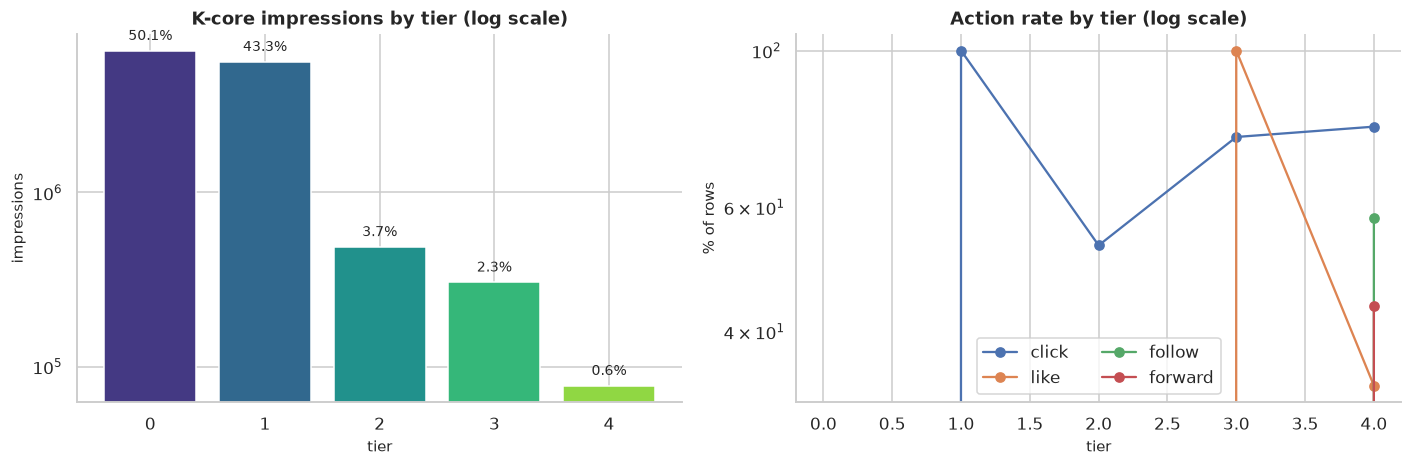

**Tier counts and action rates**

rows,share_pct,click_pct,like_pct,follow_pct,forward_pct
6539248,50.066000,0.000000,0.000000,0.000000,0.000000
5650727,43.263000,100.000000,0.000000,0.000000,0.000000
488096,3.737000,52.982000,0.000000,0.000000,0.000000
305459,2.339000,75.436000,100.000000,0.000000,0.000000
77743,0.595000,78.019000,33.550000,57.927000,43.542000


**Action rates by surface (%)**

click,like,follow,forward
53.786000,3.001000,0.408000,0.306000
12.840000,0.000000,0.000000,0.000000


In [9]:
from feed.taxonomy import cat_name

# local time features (UTC+8), matching the repository's feature builder
ev_core["hour"] = (((ev_core.ts + 8 * 3_600_000) // 3_600_000) % 24).astype("int8")
ev_core["day"] = ((ev_core.ts + 8 * 3_600_000) // 86_400_000).astype("int16")
ev_core["day"] = (ev_core.day - ev_core.day.min()).astype("int16")
ev_core["cat_name"] = ev_core.cat_id.map(cat_name)

tier_counts = ev_core.tier.value_counts().sort_index()
tier_share = 100 * tier_counts / tier_counts.sum()
action_by_tier = ev_core.groupby("tier")[["click", "like", "follow", "forward"]].mean().mul(100)
action_by_source = ev_core.groupby("source")[["click", "like", "follow", "forward"]].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
bars = ax.bar(tier_counts.index.astype(str), tier_counts.values,
              color=sns.color_palette("viridis", len(tier_counts)))
ax.set_yscale("log")
ax.set_title("K-core impressions by tier (log scale)")
ax.set_xlabel("tier"); ax.set_ylabel("impressions")
for b, s in zip(bars, tier_share.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height()*1.15, f"{s:.1f}%", ha="center", fontsize=9)
ax = axes[1]
for c in ["click", "like", "follow", "forward"]:
    ax.plot(action_by_tier.index, action_by_tier[c], marker="o", label=c)
ax.set_yscale("log")
ax.set_title("Action rate by tier (log scale)")
ax.set_xlabel("tier"); ax.set_ylabel("% of rows"); ax.legend(ncol=2)
plt.tight_layout(); plt.show()

show(pd.DataFrame({"rows": tier_counts, "share_pct": tier_share,
                   "click_pct": action_by_tier.click, "like_pct": action_by_tier.like,
                   "follow_pct": action_by_tier.follow, "forward_pct": action_by_tier.forward}),
     "Tier counts and action rates", precision=3)
show(action_by_source, "Action rates by surface (%)", precision=3)

**Interpretation.** Tier is strongly ordered but highly imbalanced. Tier 0 (no click, no long view) is half of the k-core, and tier 1 (click, no long view) is another 43.3%. Long view without click (tier 2) is only 3.7%, yet it is behaviourally important: the user watched at least 70% of the video without tapping. Tier 3 (click + long view) is 2.3% and tier 4 (click + strong action) is 0.6%. Click rate rises from 0% at tier 0 to 100% at tiers 1, 3 and 4 by construction, so the informative panel is the strong-action panel: like/follow/forward rates increase with tier, which supports H2. The surface table shows why pooling is dangerous: search has no strong-action labels at all, so a pooled model would learn a surface artefact rather than preference.

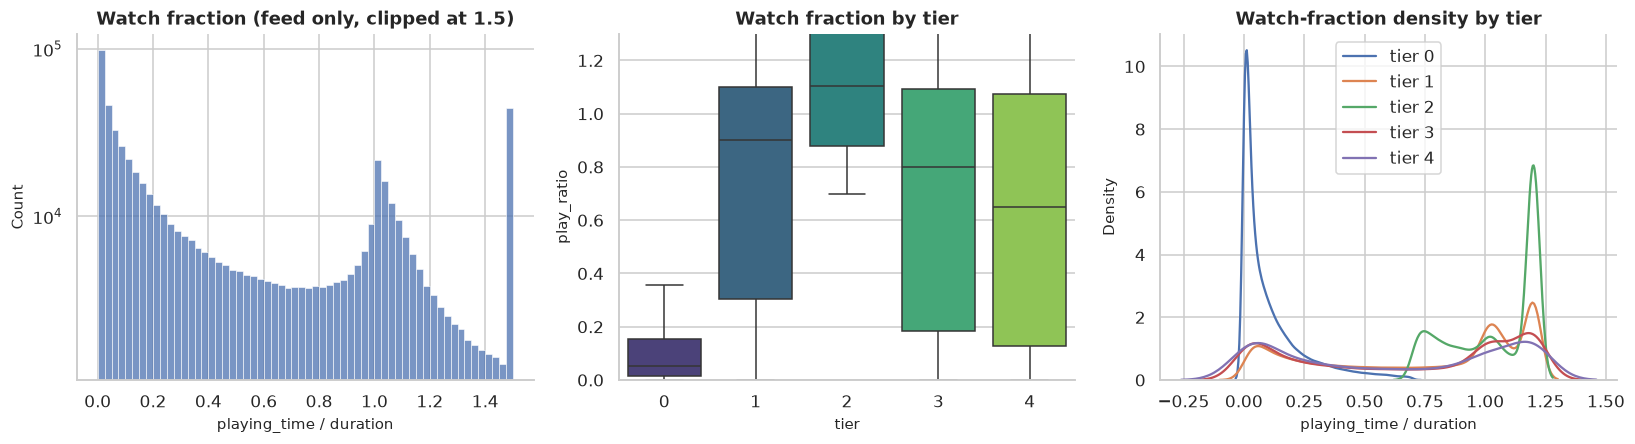

Kruskal-Wallis across tiers: H=288,784.6, p=0
Median watch fraction by tier:


,median
tier,
0,0.0542
1,0.9002
2,1.1045
3,0.7995
4,0.6493


Share of feed rows with watch >= 0.7: 34.083%


In [10]:
watch = ev_core.loc[ev_core.play_ratio.notna(), ["play_ratio", "tier", "duration_ms", "source"]]
watch_s = watch.sample(min(600_000, len(watch)), random_state=RANDOM_SEED)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
sns.histplot(watch_s.play_ratio.clip(0, 1.5), bins=60, color="#4c72b0", ax=ax)
ax.set_yscale("log"); ax.set_title("Watch fraction (feed only, clipped at 1.5)")
ax.set_xlabel("playing_time / duration")
ax = axes[1]
sns.boxplot(data=watch_s, x="tier", y="play_ratio", showfliers=False, ax=ax, palette="viridis")
ax.set_ylim(0, 1.3); ax.set_title("Watch fraction by tier"); ax.set_xlabel("tier")
ax = axes[2]
for t in [0, 1, 2, 3, 4]:
    g = watch_s.loc[watch_s.tier == t, "play_ratio"].clip(0, 1.2)
    if len(g) > 200:
        sns.kdeplot(g, label=f"tier {t}", ax=ax, common_norm=False)
ax.set_title("Watch-fraction density by tier"); ax.set_xlabel("playing_time / duration"); ax.legend()
plt.tight_layout(); plt.show()

groups = [watch_s.loc[watch_s.tier == t, "play_ratio"].dropna().values for t in range(5)]
stat, p = kruskal(*groups)
print(f"Kruskal-Wallis across tiers: H={stat:,.1f}, p={p:.3g}")
print("Median watch fraction by tier:")
display(watch_s.groupby("tier").play_ratio.median().round(4).to_frame("median"))
print("Share of feed rows with watch >= 0.7:", f"{100*(watch_s.play_ratio>=0.7).mean():.3f}%")

**Interpretation.** Watch behaviour is strongly bimodal: a large mass at zero (scroll-away), a second mass near one (completion), and relatively little in between. Tier separates the modes cleanly. Tier 0 has almost no watch time; tier 1 is a click with a short watch; tiers 2 and 3 contain the long-view mass; tier 4 shifts further toward completion. The Kruskal–Wallis test rejects equality of distributions across tiers, which is unsurprising at this sample size but confirms that the ordering is not a plotting artefact. The practical implication is that **watch fraction is a legitimate outcome to model**, but it is only observed on feed rows and only after the impression, so it cannot be a live feature for the same event.

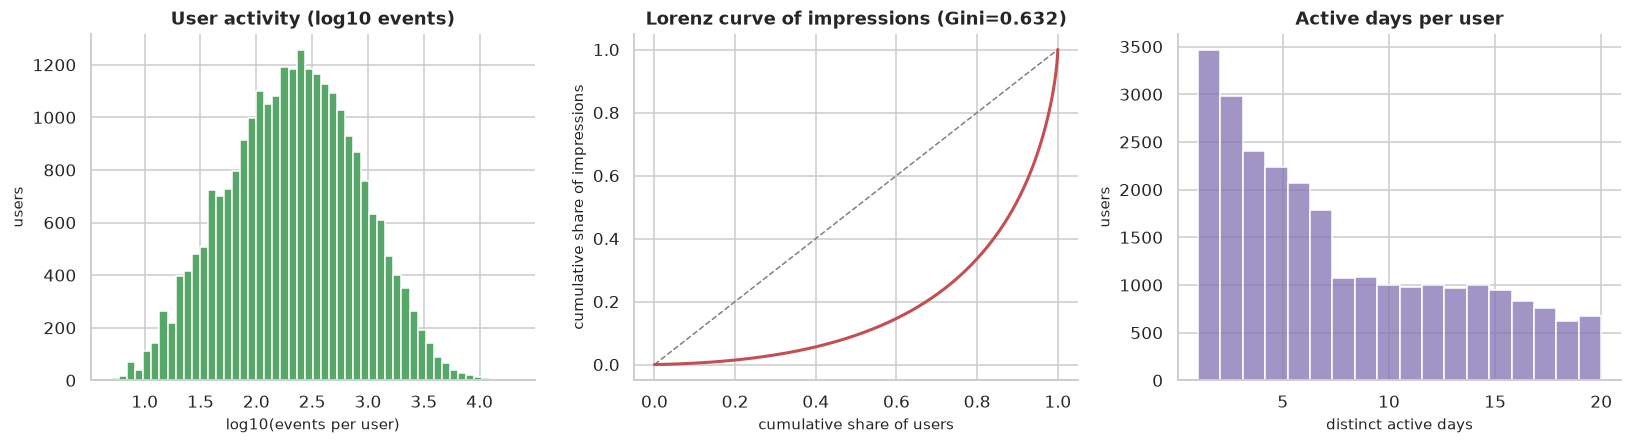

**Concentration of impressions among the most active users**

share_of_users_pct,share_of_impressions_pct
1,11.979000
5,32.757000
10,47.954000
20,66.372000
50,90.668000


Median events/user: 223; mean: 505.0; max: 20,514
Users with >=10 active days: 33.942%


In [11]:
user_events = ev_core.groupby("user_id").size().sort_values(ascending=False)
user_days = ev_core.groupby("user_id").day.nunique()
lx, ly = lorenz(user_events.values)
g = gini(user_events.values)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.hist(np.log10(user_events.values), bins=50, color="#55a868")
ax.set_title("User activity (log10 events)"); ax.set_xlabel("log10(events per user)"); ax.set_ylabel("users")
ax = axes[1]
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax.plot(lx, ly, color="#c44e52", lw=2)
ax.set_title(f"Lorenz curve of impressions (Gini={g:.3f})")
ax.set_xlabel("cumulative share of users"); ax.set_ylabel("cumulative share of impressions")
ax = axes[2]
sns.histplot(user_days, bins=18, color="#8172b2", ax=ax)
ax.set_title("Active days per user"); ax.set_xlabel("distinct active days"); ax.set_ylabel("users")
plt.tight_layout(); plt.show()

top = pd.DataFrame({
    "share_of_users_pct": [1, 5, 10, 20, 50],
    "share_of_impressions_pct": [100 * user_events.head(max(1, int(len(user_events)*q/100))).sum() / user_events.sum() for q in [1, 5, 10, 20, 50]],
})
show(top, "Concentration of impressions among the most active users", precision=3)
print(f"Median events/user: {user_events.median():.0f}; mean: {user_events.mean():.1f}; max: {user_events.max():,}")
print(f"Users with >=10 active days: {100*(user_days>=10).mean():.3f}%")

**Interpretation.** User activity is heavy-tailed. The Gini coefficient of impressions is well above zero, and the top 1% / 5% / 10% shares show that a small group of power users contributes a disproportionate volume. This is not a data error: it reflects both genuine usage differences and the platform's session length distribution. It has three consequences. First, user-level metrics should not be averaged per row, because that would over-weight power users; the model evaluation uses per-user NDCG. Second, bootstrap confidence intervals must resample **users**, not rows, to respect the dependence structure. Third, cold users are rare in volume but numerous in count, so they can be invisible in aggregate metrics while still mattering for coverage.

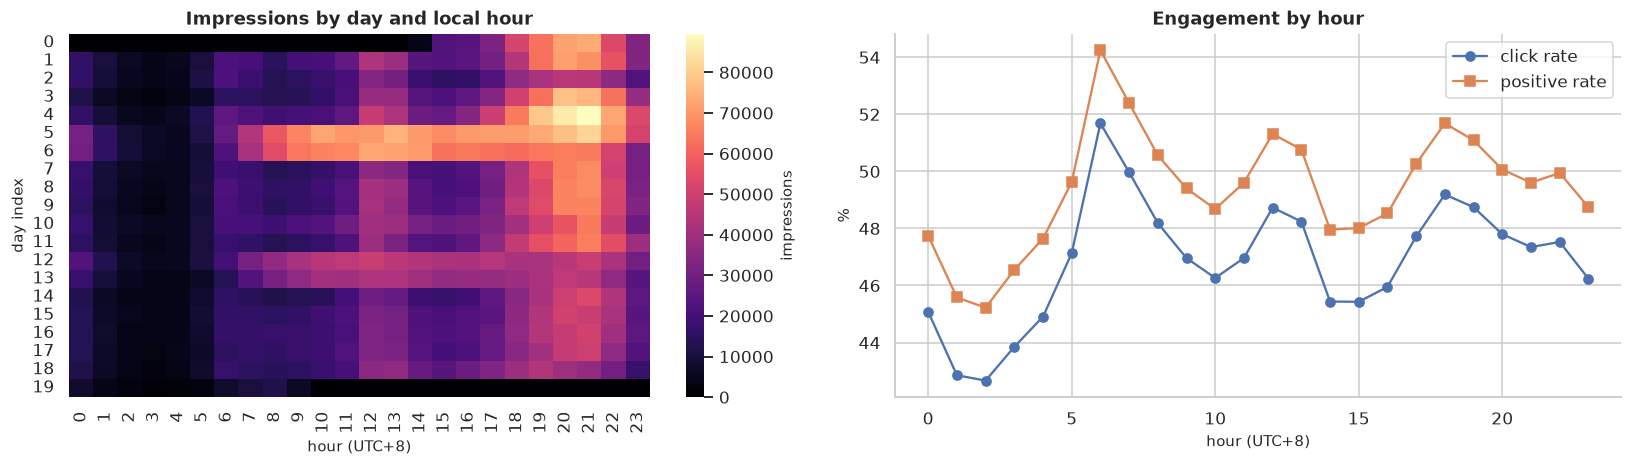

**Hourly volume and engagement**

rows,click_pct,pos_pct
313848,45.081000,47.746000
168094,42.854000,45.580000
99589,42.667000,45.222000
74278,43.850000,46.547000
85968,44.907000,47.646000
166369,47.132000,49.619000
352443,51.684000,54.243000
392654,49.970000,52.393000
398187,48.185000,50.561000
445486,46.959000,49.401000


Peak hour by volume: 21
Peak day by volume: 5
Daily rows coefficient of variation: 0.381


In [12]:
day_hour = ev_core.groupby(["day", "hour"]).size().unstack(fill_value=0)
hourly = ev_core.groupby("hour").agg(rows=("user_id", "size"), click=("click", "mean"), pos=("pos", "mean"))
daily = ev_core.groupby("day").agg(rows=("user_id", "size"), users=("user_id", "nunique"),
                                    click=("click", "mean"), pos=("pos", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
sns.heatmap(day_hour, cmap="magma", ax=axes[0], cbar_kws={"label": "impressions"})
axes[0].set_title("Impressions by day and local hour"); axes[0].set_xlabel("hour (UTC+8)"); axes[0].set_ylabel("day index")
ax = axes[1]
ax.plot(hourly.index, 100*hourly.click, marker="o", label="click rate")
ax.plot(hourly.index, 100*hourly.pos, marker="s", label="positive rate")
ax.set_title("Engagement by hour"); ax.set_xlabel("hour (UTC+8)"); ax.set_ylabel("%")
ax.legend()
plt.tight_layout(); plt.show()

show(hourly.assign(click_pct=100*hourly.click, pos_pct=100*hourly.pos)[["rows", "click_pct", "pos_pct"]],
     "Hourly volume and engagement", precision=3, max_rows=24)
print("Peak hour by volume:", int(day_hour.sum(axis=0).idxmax()))
print("Peak day by volume:", int(day_hour.sum(axis=1).idxmax()))
print("Daily rows coefficient of variation:", f"{daily.rows.std()/daily.rows.mean():.3f}")

**Interpretation.** Volume has a clear diurnal shape, with the evening block carrying the most impressions, and a day-to-day drift that is larger than a typical hourly fluctuation. Engagement rates are not flat across the day: late-night hours have different click/positive rates from the afternoon, which means `hour` is a genuine context variable rather than a cosmetic timestamp. The daily coefficient of variation confirms that the window is non-stationary. A random split would therefore mix future trends into training; the chronological split is the correct design. The heatmap also reveals a few unusually dark cells, consistent with the platform's traffic schedule rather than missing data.

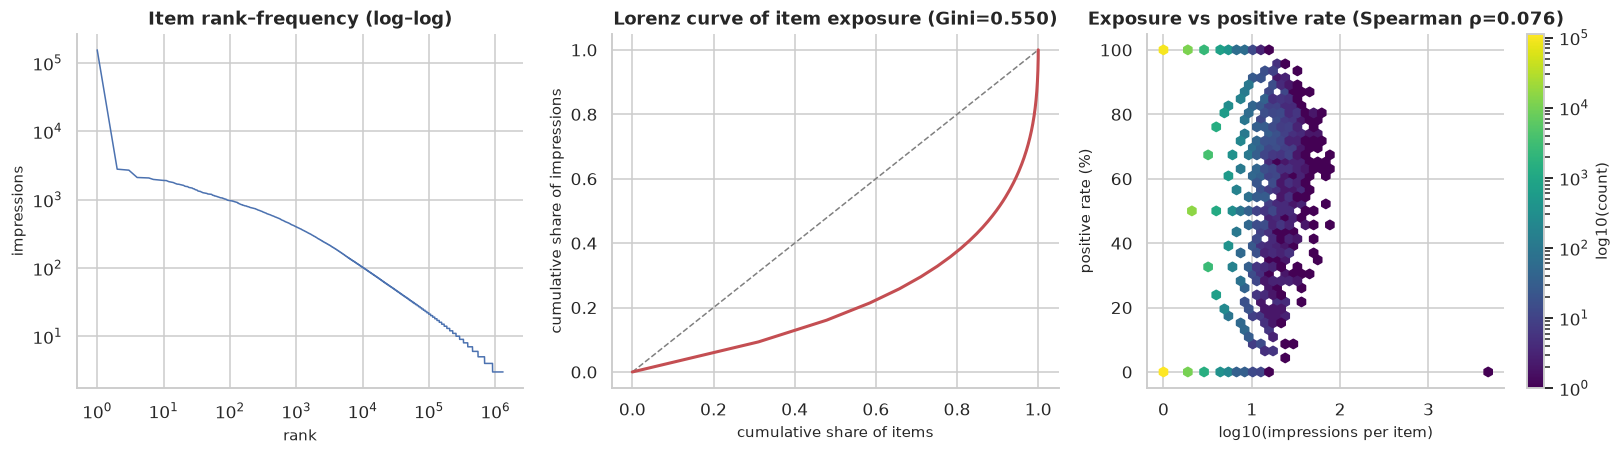

Items: 1,303,360; median impressions: 5; max: 154,772
Items with <=5 impressions: 58.15%
Top 1% of items account for 20.31% of impressions
Share of items never positively engaged: 19.20%


In [13]:
item_events = ev_core.groupby("item_id").size().sort_values(ascending=False)
item_stats_core = ev_core.groupby("item_id").agg(n=("user_id", "size"), pos=("pos", "mean"),
                                                  mean_score=("score", "mean"))
item_stats_core = item_stats_core.sort_values("n", ascending=False)
rank = np.arange(1, len(item_events) + 1)
lx, ly = lorenz(item_events.values)
gi = gini(item_events.values)
hex_s = ev_core.sample(min(400_000, len(ev_core)), random_state=RANDOM_SEED)
hex_agg = hex_s.groupby("item_id").agg(n=("user_id", "size"), pos=("pos", "mean"), score=("score", "mean"))
rho = stats.spearmanr(hex_agg.n, hex_agg.pos, nan_policy="omit").statistic

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
ax.loglog(rank, item_events.values, lw=1, color="#4c72b0")
ax.set_title("Item rank–frequency (log–log)"); ax.set_xlabel("rank"); ax.set_ylabel("impressions")
ax = axes[1]
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1); ax.plot(lx, ly, color="#c44e52", lw=2)
ax.set_title(f"Lorenz curve of item exposure (Gini={gi:.3f})"); ax.set_xlabel("cumulative share of items"); ax.set_ylabel("cumulative share of impressions")
ax = axes[2]
hb = ax.hexbin(np.log10(hex_agg.n), 100*hex_agg.pos, gridsize=40, cmap="viridis", mincnt=1, bins="log")
ax.set_title(f"Exposure vs positive rate (Spearman ρ={rho:.3f})")
ax.set_xlabel("log10(impressions per item)"); ax.set_ylabel("positive rate (%)")
plt.colorbar(hb, ax=ax, label="log10(count)")
plt.tight_layout(); plt.show()

print(f"Items: {len(item_events):,}; median impressions: {item_events.median():.0f}; max: {item_events.max():,}")
print(f"Items with <=5 impressions: {100*(item_events<=5).mean():.2f}%")
print(f"Top 1% of items account for {100*item_events.head(max(1,int(len(item_events)*0.01))).sum()/item_events.sum():.2f}% of impressions")
print(f"Share of items never positively engaged: {100*(item_stats_core.pos==0).mean():.2f}%")

**Interpretation.** Item exposure is even more concentrated than user activity. The rank–frequency curve is approximately a power law over several decades, and the Gini coefficient is high. Most items in the k-core have only a handful of impressions, while a tiny head absorbs a large share of traffic. The positive-rate/exposure relationship is weak but positive in the hexbin view: popular items are somewhat more likely to be engaged, but exposure does not guarantee engagement. The policy implication is that an item-level prior estimated from three impressions is extremely noisy, so the model must shrink item statistics toward a global mean and rely on category and user–category aggregates. The simulator's catalogue coverage guardrail exists precisely because a pure engagement ranker would collapse onto the head.

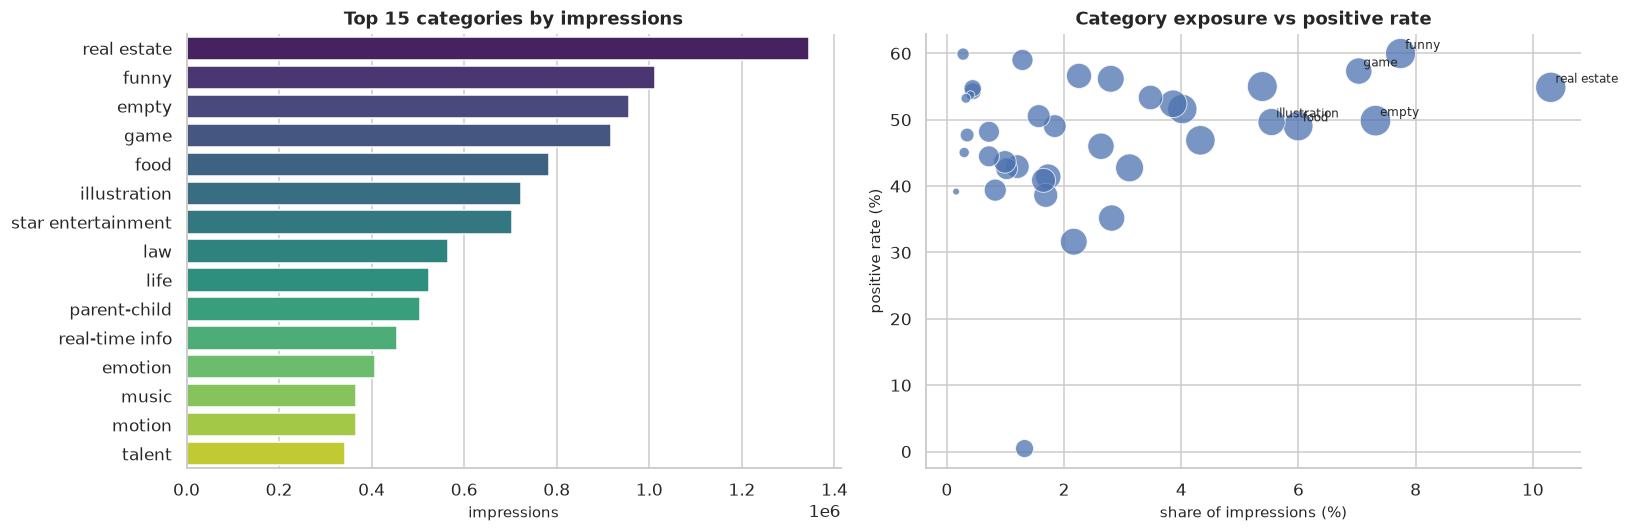

**Top categories: volume, reach and engagement**

cat_name,rows,share_pct,users,items,click,pos,watch
real estate,1345986,10.305000,24150,124993,0.537000,0.549000,0.357000
funny,1011260,7.742000,23981,73937,0.581000,0.600000,0.599000
empty,955285,7.314000,24565,92767,0.471000,0.499000,0.643000
game,918027,7.029000,19823,100922,0.550000,0.573000,0.570000
food,782942,5.994000,23482,71735,0.475000,0.491000,0.427000
illustration,723637,5.540000,20698,86441,0.473000,0.496000,0.582000
star entertainment,703034,5.383000,23706,65318,0.521000,0.550000,0.595000
law,564990,4.326000,23229,64931,0.423000,0.469000,0.768000
life,524739,4.018000,23093,50245,0.490000,0.516000,0.577000
parent-child,504265,3.861000,21174,47629,0.505000,0.524000,0.629000


In [14]:
cat_tab = (ev_core.groupby(["cat_id", "cat_name"])
           .agg(rows=("user_id", "size"), users=("user_id", "nunique"), items=("item_id", "nunique"),
                click=("click", "mean"), pos=("pos", "mean"), score=("score", "mean"),
                watch=("play_ratio", "mean"))
           .reset_index())
cat_tab["share_pct"] = 100 * cat_tab.rows / cat_tab.rows.sum()
cat_tab = cat_tab.sort_values("rows", ascending=False)
top_cat = cat_tab.head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
sns.barplot(data=top_cat, y="cat_name", x="rows", palette="viridis", ax=ax)
ax.set_title("Top 15 categories by impressions"); ax.set_xlabel("impressions"); ax.set_ylabel("")
ax = axes[1]
sns.scatterplot(data=cat_tab, x="share_pct", y=100*cat_tab.pos, size="users",
                sizes=(20, 400), alpha=0.75, ax=ax, legend=False)
for _, r in cat_tab.head(6).iterrows():
    ax.annotate(r.cat_name, (r.share_pct, 100*r.pos), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_title("Category exposure vs positive rate"); ax.set_xlabel("share of impressions (%)"); ax.set_ylabel("positive rate (%)")
plt.tight_layout(); plt.show()

show(top_cat[["cat_name", "rows", "share_pct", "users", "items", "click", "pos", "watch"]],
     "Top categories: volume, reach and engagement", precision=3, max_rows=15)

**Interpretation.** The category distribution is broad rather than dominated by a single genre: the top category accounts for a minority of impressions, and the top fifteen together cover only part of the catalogue. Categories also differ in engagement. Some high-volume categories have modest positive rates, while smaller categories can be much more engaging; the scatter shows that volume and engagement are not the same axis. This is important for the model because `cat_id` is available before the impression and can act as a useful back-off when item-level history is thin. It is also important for the simulator because the catalogue's category mix determines the achievable entropy and the meaning of a diversity guardrail.

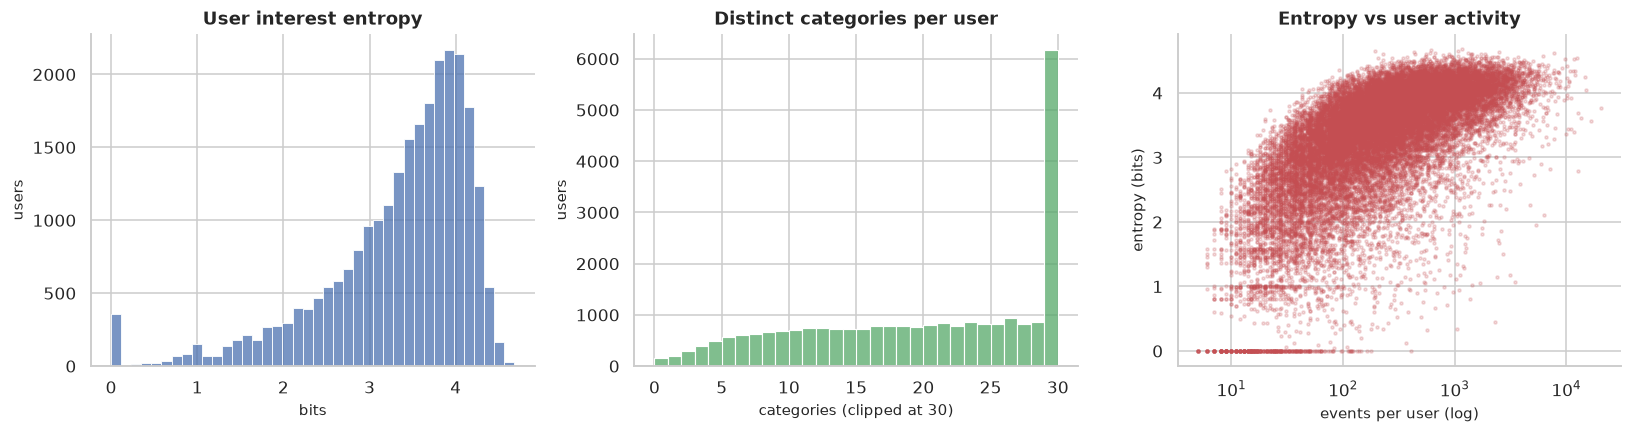

**User interest concentration: summary statistics**

count,mean,std,min,10%,50%,90%,max
25865.000000,3.327000,0.869000,-0.000000,2.153000,3.562000,4.168000,4.682000
25865.000000,19.994000,9.714000,0.000000,6.000000,20.000000,33.000000,38.000000
25707.000000,0.263000,0.149000,0.074000,0.135000,0.218000,0.447000,1.000000
25865.000000,504.979000,854.286000,5.000000,36.000000,223.000000,1249.000000,20514.000000
25865.000000,7.852000,5.104000,1.000000,2.000000,6.000000,16.000000,20.000000


Share of users with a single dominant category (top1_share > 0.5): 7.09%


In [15]:
ui = pd.read_parquet(ART / "user_interest.parquet")
us = pd.read_parquet(ART / "user_stats.parquet")

def entropy_rows(g):
    p = g["decay_share"].clip(lower=0).values
    s = p.sum()
    if s <= 0:
        return 0.0
    p = p / s
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

interest_profile = (ui.groupby("user_id")
                    .apply(lambda g: pd.Series({
                        "entropy_bits": entropy_rows(g),
                        "n_cats": int((g.decay_share > 0).sum()),
                        "top1_share": float(g.decay_share.max() / max(g.decay_share.sum(), 1e-9)),
                    }), include_groups=False)
                    .reset_index())
interest_profile = interest_profile.merge(us[["user_id", "n_events", "n_days"]], on="user_id", how="left")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.1))
sns.histplot(interest_profile.entropy_bits, bins=40, color="#4c72b0", ax=axes[0])
axes[0].set_title("User interest entropy"); axes[0].set_xlabel("bits"); axes[0].set_ylabel("users")
sns.histplot(interest_profile.n_cats.clip(0, 30), bins=30, color="#55a868", ax=axes[1])
axes[1].set_title("Distinct categories per user"); axes[1].set_xlabel("categories (clipped at 30)"); axes[1].set_ylabel("users")
axes[2].scatter(interest_profile.n_events, interest_profile.entropy_bits, s=4, alpha=0.2, color="#c44e52")
axes[2].set_xscale("log"); axes[2].set_title("Entropy vs user activity"); axes[2].set_xlabel("events per user (log)"); axes[2].set_ylabel("entropy (bits)")
plt.tight_layout(); plt.show()

show(interest_profile[["entropy_bits", "n_cats", "top1_share", "n_events", "n_days"]].describe(percentiles=[.1, .5, .9]).T,
     "User interest concentration: summary statistics", precision=3)
print("Share of users with a single dominant category (top1_share > 0.5):",
      f"{100*(interest_profile.top1_share>0.5).mean():.2f}%")

**Interpretation.** Most users have an interest entropy between roughly two and four bits, which corresponds to a handful of effective categories rather than a single obsession or uniform curiosity. The number of categories touched rises with activity, but the top-1 share stays substantial: many users have a clear dominant category even when they sample widely. This justifies two families of features: a decayed user–category share (intensity) and a lift/exposure ratio (distinctiveness). It also warns against a single “favourite category” heuristic, because the median user is multi-category. The simulator's bot population is generated with a similar mixture of focused and broad tastes, so the closed-loop conclusions are not driven by an unrealistically narrow user model.

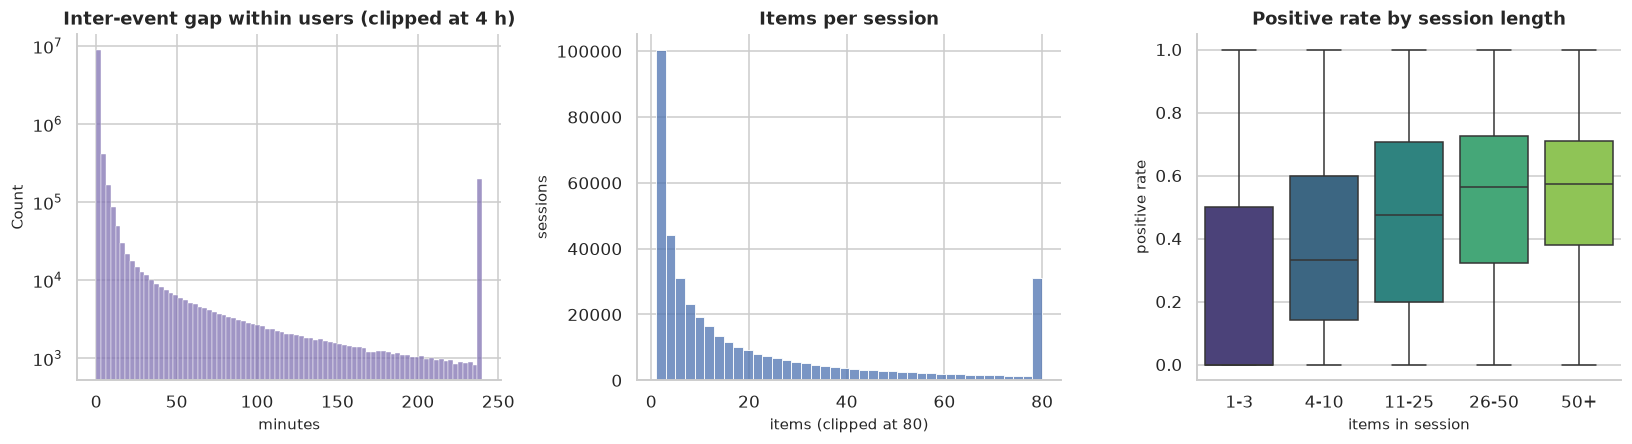

**Session length and engagement**

count,mean,std,min,10%,50%,90%,max
406507.000000,25.147000,46.308000,1.000000,1.000000,9.000000,65.000000,2043.000000
406507.000000,686.596000,1262.541000,0.000000,45.974000,240.460000,1536.957000,24876.746000
406507.000000,0.382000,0.322000,0.000000,0.000000,0.350000,0.833000,1.000000
406507.000000,0.402000,0.330000,0.000000,0.000000,0.400000,0.864000,1.000000


Median inter-event gap: 0.00 min
Median session length: 9 items; 90th pct: 65


In [16]:
sess_users = ev_core.user_id.drop_duplicates().sample(min(20_000, ev_core.user_id.nunique()), random_state=RANDOM_SEED)
sess = ev_core.loc[ev_core.user_id.isin(sess_users), ["user_id", "ts", "tier", "click", "pos"]].sort_values(["user_id", "ts"]).copy()
sess["gap_min"] = sess.groupby("user_id").ts.diff() / 60_000
sess["new_session"] = (sess.gap_min.isna()) | (sess.gap_min > 30)
sess["session_id"] = sess.groupby("user_id").new_session.cumsum()
session_stats = sess.groupby(["user_id", "session_id"]).agg(
    items=("ts", "size"), duration_min=("gap_min", "sum"), start=("ts", "min"),
    click=("click", "mean"), pos=("pos", "mean"))
session_stats["duration_min"] = session_stats["duration_min"].fillna(0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(sess.gap_min.dropna().clip(0, 240), bins=80, color="#8172b2", ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Inter-event gap within users (clipped at 4 h)"); axes[0].set_xlabel("minutes")
sns.histplot(session_stats["items"].clip(0, 80), bins=40, color="#4c72b0", ax=axes[1])
axes[1].set_title("Items per session"); axes[1].set_xlabel("items (clipped at 80)"); axes[1].set_ylabel("sessions")
length_bin = pd.cut(session_stats["items"], [0, 3, 10, 25, 50, 1000], labels=["1-3", "4-10", "11-25", "26-50", "50+"])
sns.boxplot(data=session_stats.reset_index().assign(length_bin=length_bin.values),
            x="length_bin", y="pos", showfliers=False, ax=axes[2], palette="viridis")
axes[2].set_title("Positive rate by session length"); axes[2].set_xlabel("items in session"); axes[2].set_ylabel("positive rate")
plt.tight_layout(); plt.show()

show(session_stats[["items", "duration_min", "click", "pos"]].describe(percentiles=[.1, .5, .9]).T,
     "Session length and engagement", precision=3)
print(f"Median inter-event gap: {sess.gap_min.median():.2f} min")
print(f"Median session length: {session_stats["items"].median():.0f} items; 90th pct: {session_stats["items"].quantile(.9):.0f}")

**Interpretation.** The inter-event gap distribution is heavy-tailed with a clear knee: many gaps are seconds apart (continuous scrolling), while a long tail represents returns hours later. A 30-minute inactivity threshold yields a median session of a handful of items and a 90th percentile that is much larger, consistent with both quick checks and long binge sessions. Positive rate varies with session length, but not monotonically in a way that justifies a simple “longer session = happier user” rule; session length is an outcome of the content sequence, not an exogenous feature. For modelling, session-level aggregates are therefore treated as **as-of history**, and the simulator's session schedule is calibrated to the observed sessional rhythm rather than to a fixed number of impressions.

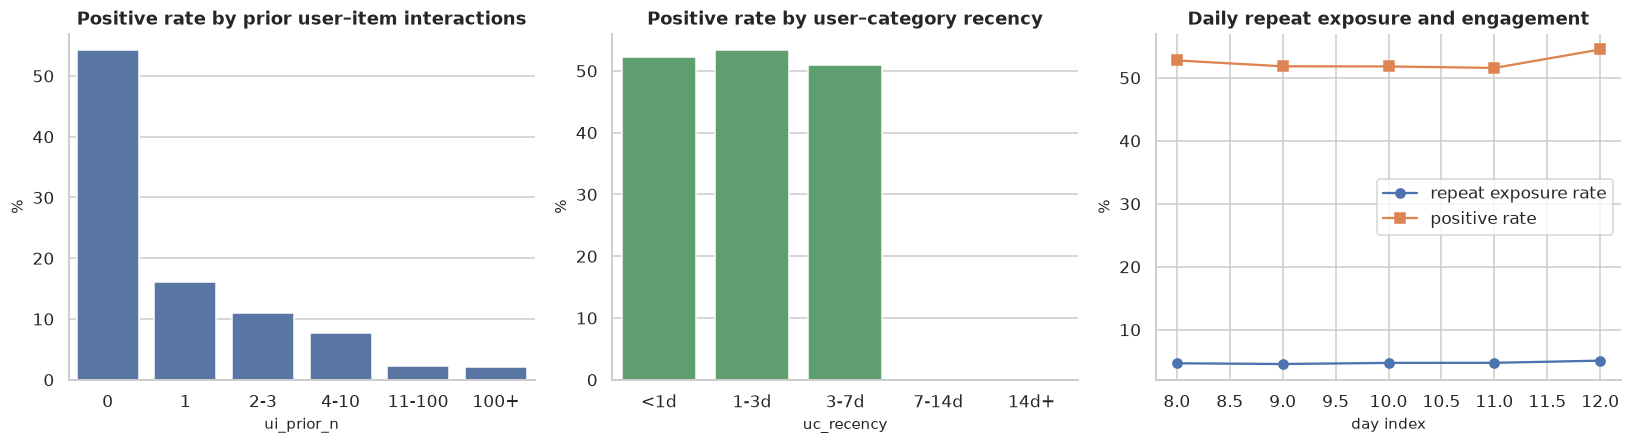

**Engagement by prior user–item count**

rows,pos_rate,watch
476400,0.542000,0.438000
9228,0.162000,0.304000
5961,0.110000,0.220000
3611,0.076000,0.023000
4195,0.022000,0.014000
605,0.021000,nan


**Engagement by user–category recency**

rows,pos_rate,watch
445866,0.522000,0.436000
29007,0.533000,0.449000
25127,0.510000,0.444000


In [17]:
ft = pd.read_parquet(ART / "features_train.parquet",
                     columns=["user_id", "item_id", "ts", "day", "tier", "pos", "is_search",
                              "ui_prior_n", "ui_prior_max_tier", "uc_recency", "u_recency",
                              "cold_user", "cold_item", "cold_uc",
                              "uc_decay_share", "watch"])
ft_s = ft.sample(min(500_000, len(ft)), random_state=RANDOM_SEED).copy()
ft_s["prior_bucket"] = pd.cut(ft_s.ui_prior_n, [-1, 0, 1, 3, 10, 100, 10000],
                              labels=["0", "1", "2-3", "4-10", "11-100", "100+"])
ft_s["recency_bucket"] = pd.cut(ft_s.uc_recency, [-0.01, 1, 3, 7, 14, 100],
                                labels=["<1d", "1-3d", "3-7d", "7-14d", "14d+"])

prior_tab = ft_s.groupby("prior_bucket", observed=True).agg(rows=("pos", "size"), pos_rate=("pos", "mean"),
                                                            watch=("watch", "mean"))
rec_tab = ft_s.groupby("recency_bucket", observed=True).agg(rows=("pos", "size"), pos_rate=("pos", "mean"),
                                                            watch=("watch", "mean"))
novel = ft_s.groupby("day").agg(rows=("pos", "size"), repeat_rate=("ui_prior_n", lambda x: (x > 0).mean()),
                                 pos_rate=("pos", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.barplot(x=prior_tab.index, y=100*prior_tab.pos_rate, color="#4c72b0", ax=axes[0])
axes[0].set_title("Positive rate by prior user–item interactions"); axes[0].set_xlabel("ui_prior_n"); axes[0].set_ylabel("%")
sns.barplot(x=rec_tab.index, y=100*rec_tab.pos_rate, color="#55a868", ax=axes[1])
axes[1].set_title("Positive rate by user–category recency"); axes[1].set_xlabel("uc_recency"); axes[1].set_ylabel("%")
ax = axes[2]
ax.plot(novel.index, 100*novel.repeat_rate, marker="o", label="repeat exposure rate")
ax.plot(novel.index, 100*novel.pos_rate, marker="s", label="positive rate")
ax.set_title("Daily repeat exposure and engagement"); ax.set_xlabel("day index"); ax.set_ylabel("%"); ax.legend()
plt.tight_layout(); plt.show()

show(prior_tab, "Engagement by prior user–item count", precision=3)
show(rec_tab, "Engagement by user–category recency", precision=3)

**Interpretation.** Prior user–item interaction count is associated with higher engagement, but the relationship is not a simple “more is always better” law: repeat exposures can also signal fatigue. The recency panel is more stable: recently engaged categories have higher positive rates than stale ones, which validates the decayed user–category features. Daily repeat exposure rises over the window while positive rate drifts, confirming that the system becomes more repetitive and that the chronological test period is genuinely different from training. This is a concrete motivation for the simulator's repeat-exposure guardrail and for evaluating on the future test split rather than a random holdout.

**Chronological split summary and cold-start drift**

split,rows,users,items,start_day,end_day,pos_rate,cold_item_share,search_share,tier2_share
train,2612256,13269,568189,2023-05-30,2023-06-03,0.521500,0.068300,0.111900,0.030600
val,1959189,11218,487026,2023-06-03,2023-06-06,0.516800,0.061700,0.122300,0.033600
test,1959194,10634,444869,2023-06-06,2023-06-10,0.530800,0.053800,0.075300,0.028600


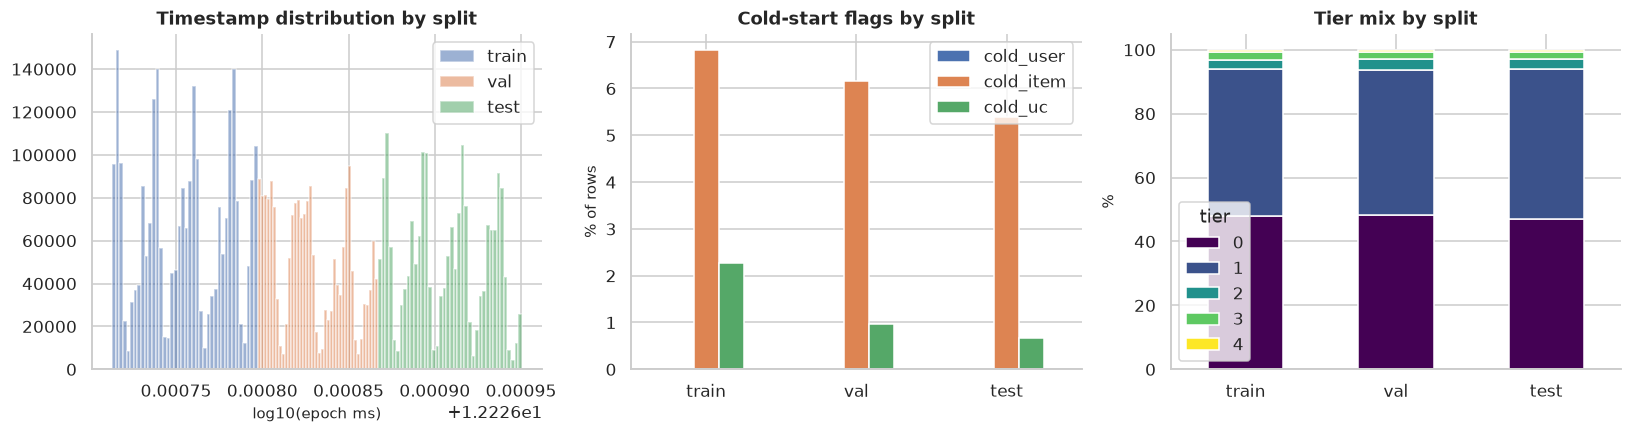

21795

In [18]:
split_cols = ["user_id", "item_id", "ts", "tier", "pos", "is_search", "cold_user", "cold_item", "cold_uc"]
splits = {}
for name in ["train", "val", "test"]:
    splits[name] = pd.read_parquet(ART / f"features_{name}.parquet", columns=split_cols)

split_summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "rows": [len(splits[s]) for s in ["train", "val", "test"]],
    "users": [splits[s].user_id.nunique() for s in ["train", "val", "test"]],
    "items": [splits[s].item_id.nunique() for s in ["train", "val", "test"]],
    "start_day": [pd.to_datetime(splits[s].ts.min(), unit="ms", utc=True).tz_convert("Asia/Shanghai").strftime("%Y-%m-%d") for s in ["train", "val", "test"]],
    "end_day": [pd.to_datetime(splits[s].ts.max(), unit="ms", utc=True).tz_convert("Asia/Shanghai").strftime("%Y-%m-%d") for s in ["train", "val", "test"]],
    "pos_rate": [splits[s].pos.mean() for s in ["train", "val", "test"]],
    "cold_item_share": [splits[s].cold_item.mean() for s in ["train", "val", "test"]],
    "search_share": [splits[s].is_search.mean() for s in ["train", "val", "test"]],
    "tier2_share": [(splits[s].tier == 2).mean() for s in ["train", "val", "test"]],
})
show(split_summary, "Chronological split summary and cold-start drift", precision=4)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.1))
for name in ["train", "val", "test"]:
    axes[0].hist(np.log10(splits[name].ts), bins=40, alpha=0.55, label=name)
axes[0].set_title("Timestamp distribution by split"); axes[0].set_xlabel("log10(epoch ms)"); axes[0].legend()
cold_rates = pd.DataFrame({s: [100*splits[s].cold_user.mean(), 100*splits[s].cold_item.mean(), 100*splits[s].cold_uc.mean()] for s in ["train", "val", "test"]},
                          index=["cold_user", "cold_item", "cold_uc"]).T
cold_rates.plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452", "#55a868"])
axes[1].set_title("Cold-start flags by split"); axes[1].set_ylabel("% of rows"); axes[1].tick_params(axis="x", rotation=0)
tier_mix = pd.DataFrame({s: (100*splits[s].tier.value_counts(normalize=True).sort_index()) for s in ["train", "val", "test"]}).T
tier_mix.plot(kind="bar", stacked=True, ax=axes[2], colormap="viridis")
axes[2].set_title("Tier mix by split"); axes[2].set_ylabel("%"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

del splits
gc.collect()

**Interpretation.** The chronological split is not exchangeable. The test period has a different tier mix, a higher cold-item share and a different positive rate from training, and the timestamp histogram shows clean, non-overlapping blocks. This is exactly the stress test we want: a model that only memorises the training period will degrade, whereas a model that uses stable as-of structure should transfer. The cold-start drift is particularly important: cold items are more common in validation/test than in training, so the reported test NDCG is a **harder** number than a random split would produce. Any comparison to a random-split benchmark is therefore not apples-to-apples, and the report does not make one.

## Step 15 — Bivariate and multivariate analysis

The bivariate section looks for structure **between** variables. It covers:

- surface differences (search vs feed),
- cold-start drift across the chronological splits,
- correlation among the engineered features,
- Cramér's V among categorical variables,
- univariate AUC of each feature for the positive label,
- decile plots for the strongest features,
- pair plots and grouped distributions,
- PCA of user–category interest vectors.

The goal is not to prove causality. It is to identify which associations are strong enough to survive a chronological split and which are likely to be artefacts of exposure or surface.

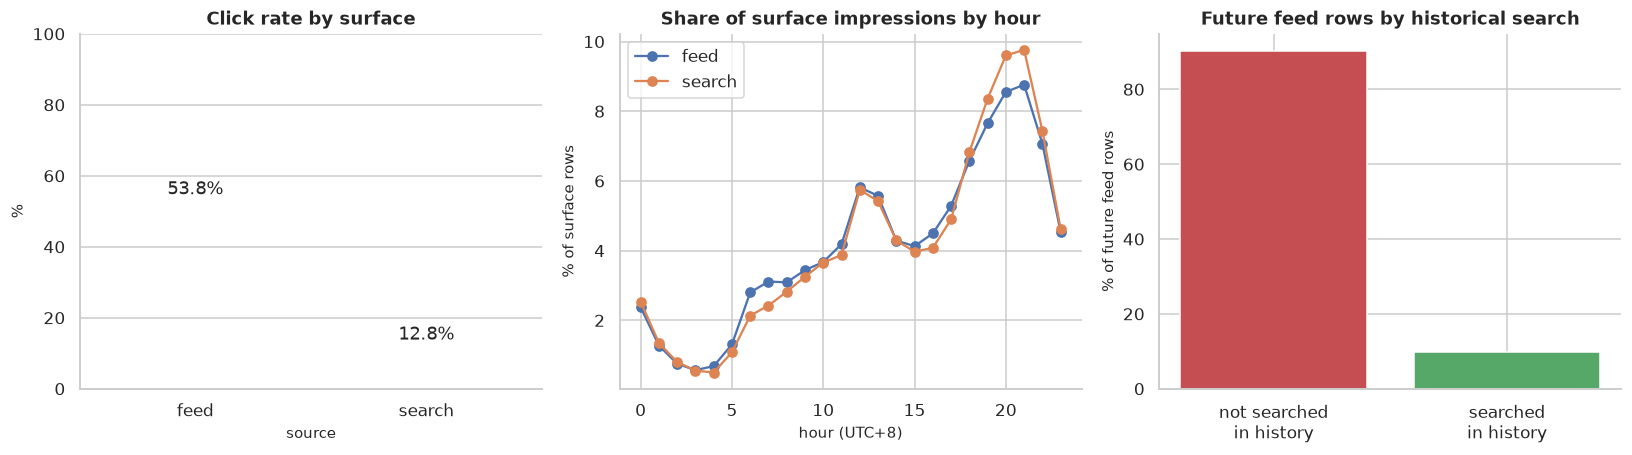

**Search versus feed: volume and engagement**

rows,users,items,click,pos,watch,tier2
11047186,25863,1034564,0.538000,0.567000,0.565000,0.021000
2014087,25179,407275,0.128000,0.128000,nan,0.128000


**Future feed activity for user–category pairs with vs without prior search**

size,mean,share_of_future_rows
164676,4.851000,0.903000
17674,5.540000,0.097000


Search rows are 15.42% of the k-core.


Search users as share of k-core users: 97.35%


In [19]:
surface = ev_core.groupby("source").agg(rows=("user_id", "size"), users=("user_id", "nunique"),
                                        items=("item_id", "nunique"), click=("click", "mean"),
                                        pos=("pos", "mean"), watch=("play_ratio", "mean"),
                                        tier2=("tier", lambda x: (x == 2).mean()))
hourly_src = ev_core.groupby(["hour", "source"]).size().unstack(fill_value=0)
hourly_src = hourly_src.div(hourly_src.sum(axis=0), axis=1)

# historical search -> future feed lift, computed on a 2M sample
evs = ev_core[["user_id", "item_id", "cat_id", "ts", "source"]].sample(min(2_000_000, len(ev_core)), random_state=RANDOM_SEED)
mid = ev_core.ts.median()
hist = evs.loc[(evs.source == "search") & (evs.ts < mid)]
fut = evs.loc[(evs.source == "feed") & (evs.ts >= mid)]
hist_pairs = hist[["user_id", "cat_id"]].drop_duplicates()
hist_pairs["searched"] = 1
future_cat = fut.groupby(["user_id", "cat_id"]).size().rename("feed_impressions").reset_index()
merged = future_cat.merge(hist_pairs, on=["user_id", "cat_id"], how="left")
merged["searched"] = merged["searched"].fillna(0).astype(int)
lift = merged.groupby("searched").feed_impressions.agg(["size", "mean"])
lift["share_of_future_rows"] = lift["size"] / lift["size"].sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
sns.barplot(data=surface.reset_index(), x="source", y=100*surface.click, color="#4c72b0", ax=ax)
ax.set_title("Click rate by surface"); ax.set_ylabel("%"); ax.set_ylim(0, 100)
for i, v in enumerate(100*surface.click):
    ax.text(i, v+1, f"{v:.1f}%", ha="center")
ax = axes[1]
for c in hourly_src.columns:
    ax.plot(hourly_src.index, 100*hourly_src[c], marker="o", label=c)
ax.set_title("Share of surface impressions by hour"); ax.set_xlabel("hour (UTC+8)"); ax.set_ylabel("% of surface rows"); ax.legend()
ax = axes[2]
ax.bar(["not searched\nin history", "searched\nin history"], 100*lift["share_of_future_rows"], color=["#c44e52", "#55a868"])
ax.set_title("Future feed rows by historical search"); ax.set_ylabel("% of future feed rows")
plt.tight_layout(); plt.show()

show(surface, "Search versus feed: volume and engagement", precision=3)
show(lift, "Future feed activity for user–category pairs with vs without prior search", precision=3)
print("Search rows are", f"{100*(ev_core.source=='search').mean():.2f}%", "of the k-core.")
print("Search users as share of k-core users:",
      f"{100*(ev_core.groupby('user_id').source.apply(lambda x: (x=='search').any())).mean():.2f}%")

**Interpretation.** Search is a minority surface by volume but not by intent: its click rate is much higher than the feed's, and its hourly profile is flatter, because users search when they have a need rather than when the feed prompts them. In the sampled history/future comparison, user–category pairs with a prior search account for a disproportionate share of later feed impressions, which is consistent with search intent persisting into the feed. This is an association, not a causal effect: users who search may simply be more active. Nevertheless, it justifies keeping `is_search` as a stratifier and including user–category history features that can carry search-derived intent.

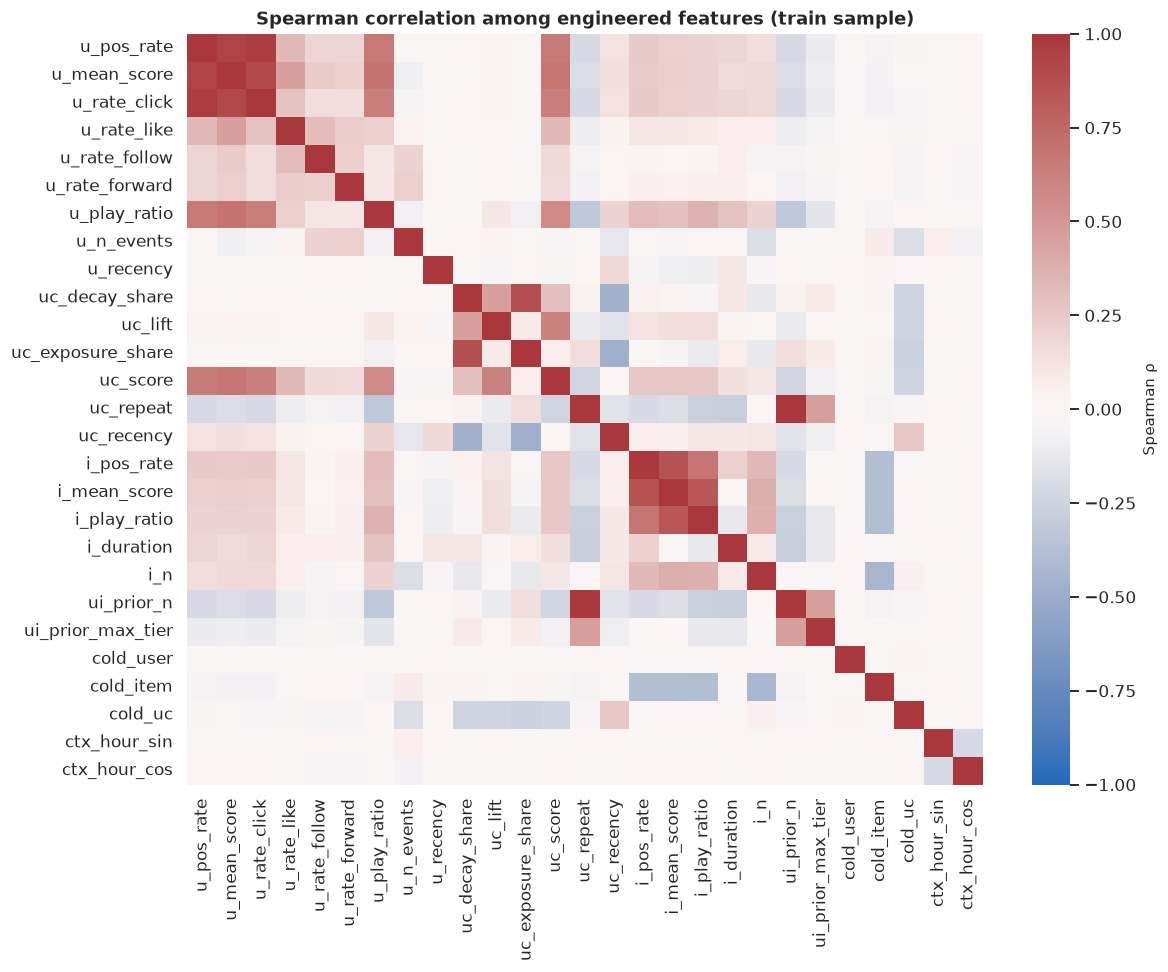

**Strongest feature–feature associations**

spearman_rho
1.000000
0.970000
0.945000
0.908000
0.878000
0.864000
0.841000
0.694000
0.684000
0.677000


Features with |ρ| > 0.8 against another feature: 6


In [20]:
corr_cols = [c for c in FEATURE_COLS if c != "cat_id"]
corr_s = pd.read_parquet(ART / "features_train.parquet", columns=corr_cols).sample(300_000, random_state=RANDOM_SEED)
corr = corr_s.corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Spearman correlation among engineered features (train sample)")
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
pairs.name = "spearman_rho"
show(pairs.head(20).to_frame(), "Strongest feature–feature associations", precision=3, max_rows=20)
print("Features with |ρ| > 0.8 against another feature:",
      pairs[pairs.abs() > 0.8].index.get_level_values(0).nunique())

**Interpretation.** The correlation matrix is mostly block-structured, not globally collinear. The strongest associations are within the user-history block and within the item-history block, which is expected: rates and counts derived from the same events share variance. The user–category features form a separate block, and the context features are nearly orthogonal to everything else. The number of pairs above |ρ| = 0.8 is small, which means the 28-feature vector is not severely redundant. Still, correlated features can split importance and destabilise small models, so the report reports both raw AUC and grouped feature viability rather than interpreting individual coefficients causally.

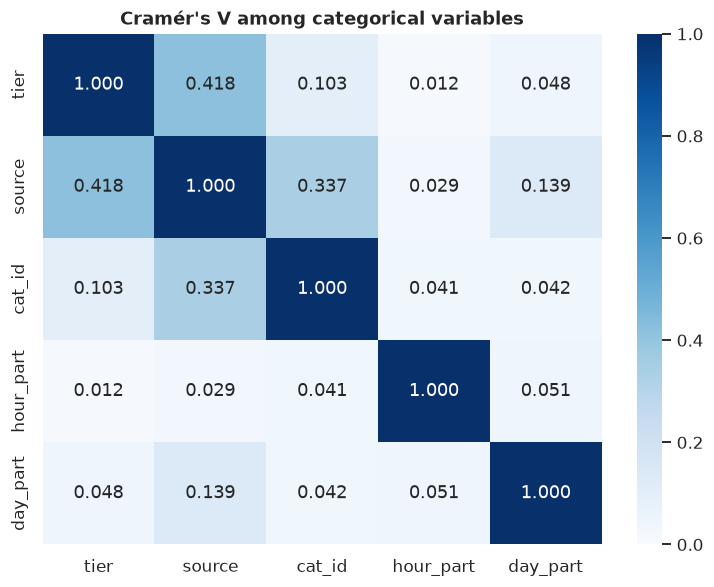

**Cramér's V matrix**

tier,source,cat_id,hour_part,day_part
1.000000,0.418000,0.103000,0.012000,0.048000
0.418000,1.000000,0.337000,0.029000,0.139000
0.103000,0.337000,1.000000,0.041000,0.042000
0.012000,0.029000,0.041000,1.000000,0.051000
0.048000,0.139000,0.042000,0.051000,1.000000


Tier × surface chi-square: chi2=87,443.3, dof=4, p=0, Cramér's V=0.418


In [21]:
cat_frame = ev_core.sample(min(500_000, len(ev_core)), random_state=RANDOM_SEED).copy()
cat_frame["hour_part"] = pd.cut(cat_frame.hour, [-1, 5, 11, 17, 23], labels=["night", "morning", "afternoon", "evening"])
cat_frame["day_part"] = pd.cut(cat_frame.day, [-1, 5, 11, 17], labels=["early", "mid", "late"])
cat_vars = ["tier", "source", "cat_id", "hour_part", "day_part"]
vmat = pd.DataFrame(index=cat_vars, columns=cat_vars, dtype=float)
for a in cat_vars:
    for b in cat_vars:
        vmat.loc[a, b] = 1.0 if a == b else cramers_v(cat_frame[a], cat_frame[b])

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(vmat.astype(float), annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Cramér's V among categorical variables")
plt.tight_layout(); plt.show()
show(vmat.astype(float), "Cramér's V matrix", precision=3, max_rows=10)
chi = chi2_contingency(pd.crosstab(cat_frame.tier, cat_frame.source), correction=False)
print(f"Tier × surface chi-square: chi2={chi[0]:,.1f}, dof={chi[2]}, p={chi[1]:.3g}, Cramér's V={vmat.loc['tier','source']:.3f}")

**Interpretation.** Cramér's V is strongest between surface and tier, which is the same structural fact seen in the cleaning table: search rows only have tiers 0 and 2. Category is moderately associated with tier, meaning some genres are more likely to produce long views or strong actions. Hour-of-day has a smaller but non-zero association with engagement, and day-part is weaker still. The practical conclusion is that `source` must be a stratifier, `cat_id` is worth embedding, and time-of-day is a useful but secondary context feature. None of the categorical associations is so strong that it explains away the others.

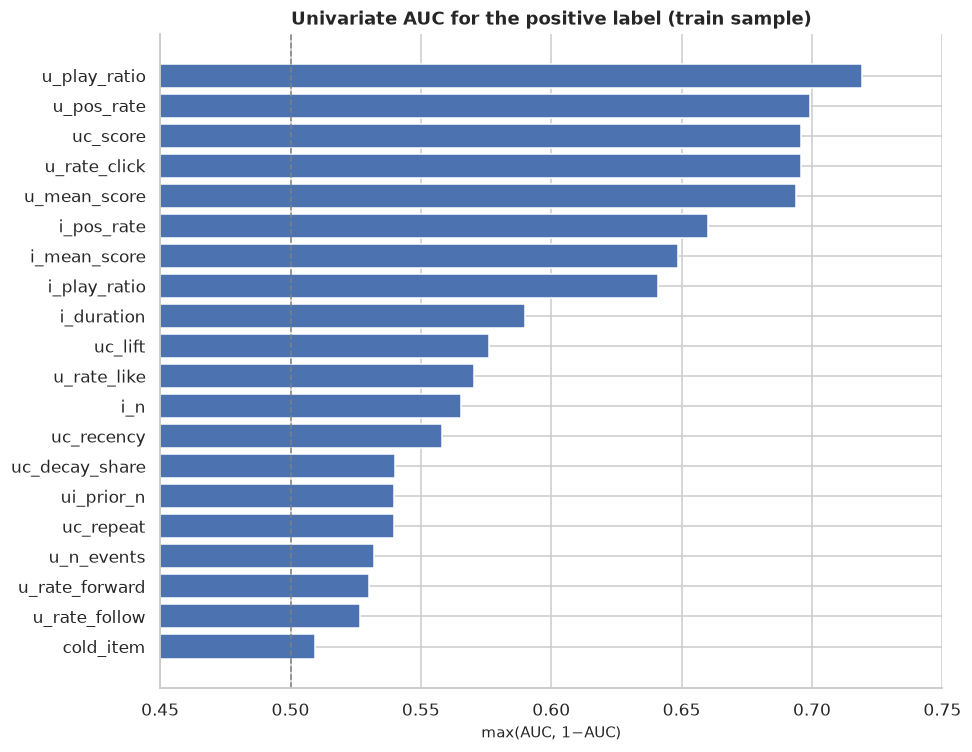

**Feature viability: univariate AUC**

feature,auc_raw,auc_edge
u_play_ratio,0.719000,0.719000
u_pos_rate,0.699200,0.699200
uc_score,0.695800,0.695800
u_rate_click,0.695700,0.695700
u_mean_score,0.694000,0.694000
i_pos_rate,0.660100,0.660100
i_mean_score,0.648600,0.648600
i_play_ratio,0.641100,0.641100
i_duration,0.590100,0.590100
uc_lift,0.576100,0.576100


In [22]:
auc_sample = pd.read_parquet(ART / "features_train.parquet",
                             columns=["pos", "tier"] + FEATURE_COLS).sample(350_000, random_state=RANDOM_SEED)
y = auc_sample["pos"].values
rows = []
for c in FEATURE_COLS:
    x = auc_sample[c].values.astype(float)
    ok = np.isfinite(x)
    if ok.sum() < 1000 or len(np.unique(x[ok])) < 2:
        continue
    a = roc_auc_score(y[ok], x[ok])
    rows.append((c, a, max(a, 1 - a)))
auc_df = pd.DataFrame(rows, columns=["feature", "auc_raw", "auc_edge"]).sort_values("auc_edge", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
top_auc = auc_df.head(20).iloc[::-1]
ax.barh(top_auc.feature, top_auc.auc_edge, color="#4c72b0")
ax.axvline(0.5, color="grey", ls="--", lw=1)
ax.set_xlim(0.45, max(0.75, top_auc.auc_edge.max() + 0.03))
ax.set_title("Univariate AUC for the positive label (train sample)")
ax.set_xlabel("max(AUC, 1−AUC)")
plt.tight_layout(); plt.show()
show(auc_df.head(25), "Feature viability: univariate AUC", precision=4, max_rows=25)

**Interpretation.** No single feature is a strong classifier: the best univariate AUC is only moderately above 0.5, and most features are in the 0.52–0.65 range. The strongest signals come from user habit and user–category affinity, followed by item quality. Cold flags and context features are weaker on their own, which is expected because they are interactions rather than main effects. This validates the decision to use a learned combination rather than a hand-written score, and it sets a realistic expectation: a good model should beat popularity by a few NDCG points, not by tens of points.

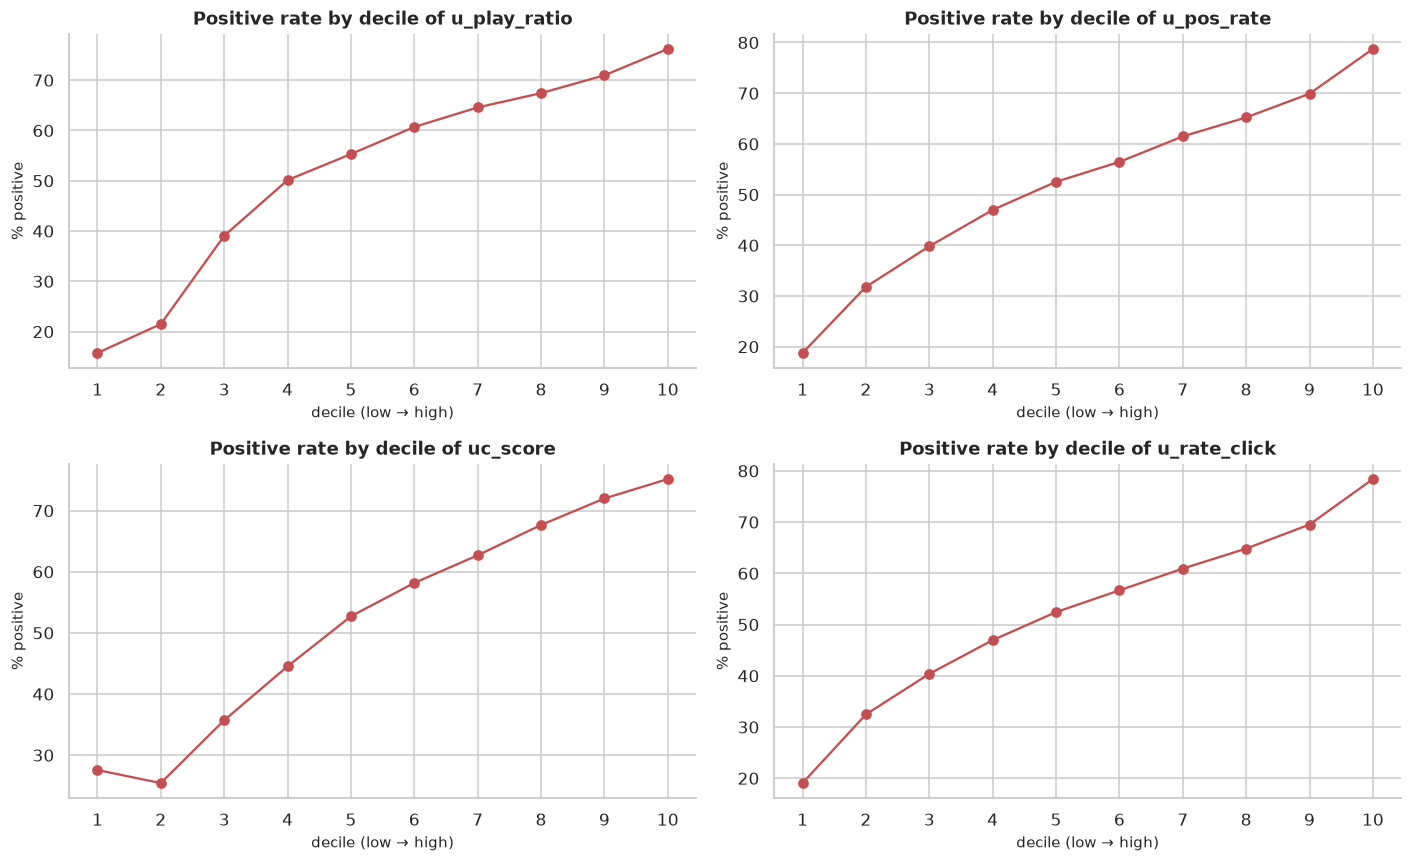

**Decile table for u_rate_click**

pos_rate,n,mid
0.190500,35000,0.140400
0.324500,35000,0.253200
0.403700,35000,0.332300
0.469500,35000,0.402400
0.524100,35000,0.459300
0.566700,35000,0.508600
0.609100,35000,0.564500
0.648100,35000,0.616900
0.695100,35000,0.672500
0.783900,35000,0.758200


In [23]:
best_feats = auc_df.head(4).feature.tolist()
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, f in zip(axes.ravel(), best_feats):
    tmp = auc_sample[[f, "pos"]].copy()
    tmp["decile"] = pd.qcut(tmp[f].rank(method="first"), 10, labels=False, duplicates="drop")
    dec = tmp.groupby("decile").agg(pos_rate=("pos", "mean"), n=("pos", "size"), mid=(f, "median"))
    ax.plot(dec.index + 1, 100*dec.pos_rate, marker="o", color="#c44e52")
    ax.set_title(f"Positive rate by decile of {f}")
    ax.set_xlabel("decile (low → high)"); ax.set_ylabel("% positive")
    ax.set_xticks(range(1, 11))
plt.tight_layout(); plt.show()
show(dec, f"Decile table for {f}", precision=4, max_rows=12)

**Interpretation.** The decile plots are monotone but shallow. The strongest features separate the bottom and top deciles by only a few percentage points of positive rate, and the shape is often flat in the middle. This is the classic signature of a weak-but-real signal in observational recommendation data: the feature is useful in combination, but a single threshold would be a poor policy. The monotonicity also confirms that the engineered direction is correct (higher habit/affinity → higher engagement), which matters because a sign error in feature construction would be invisible in a correlation matrix but fatal in a linear model.

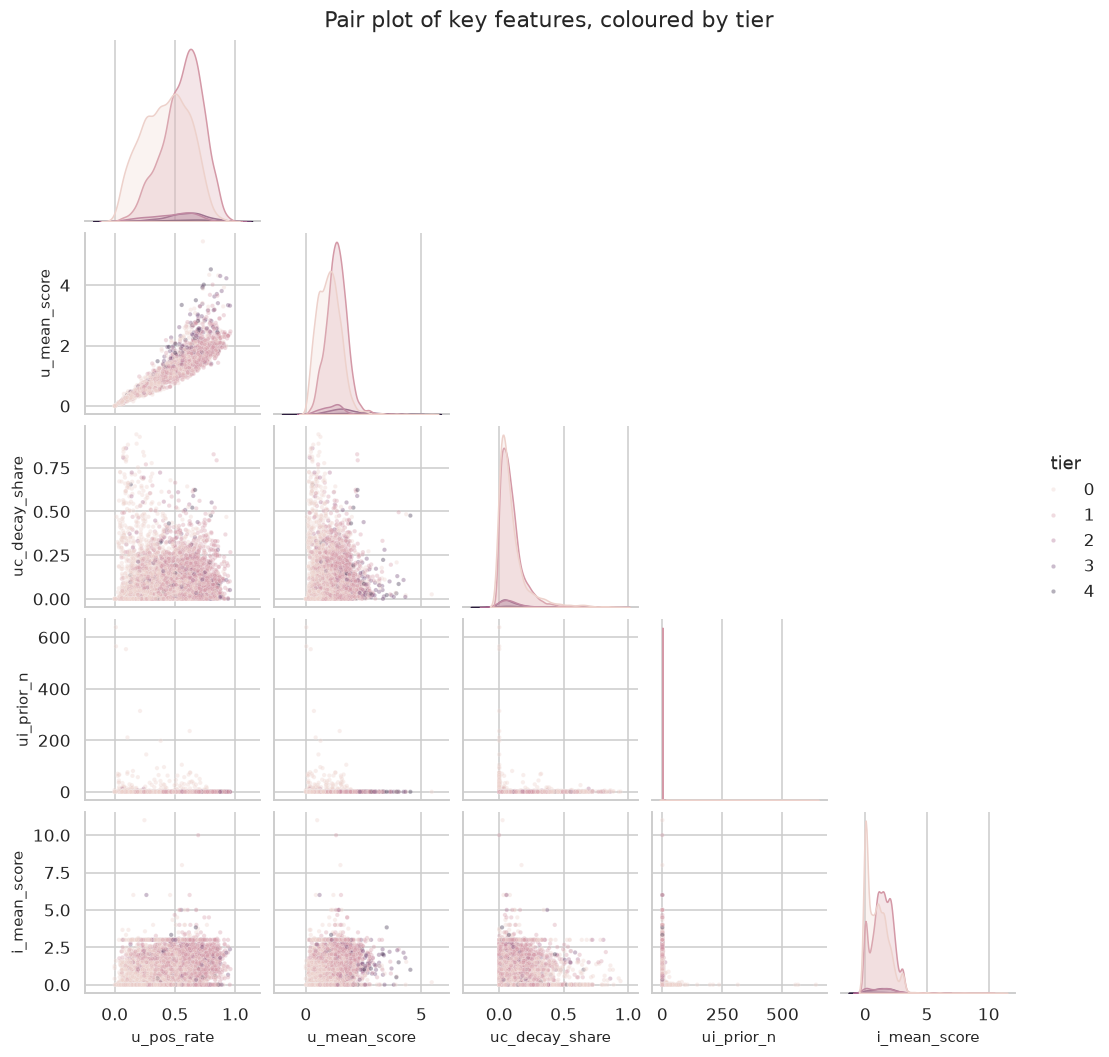

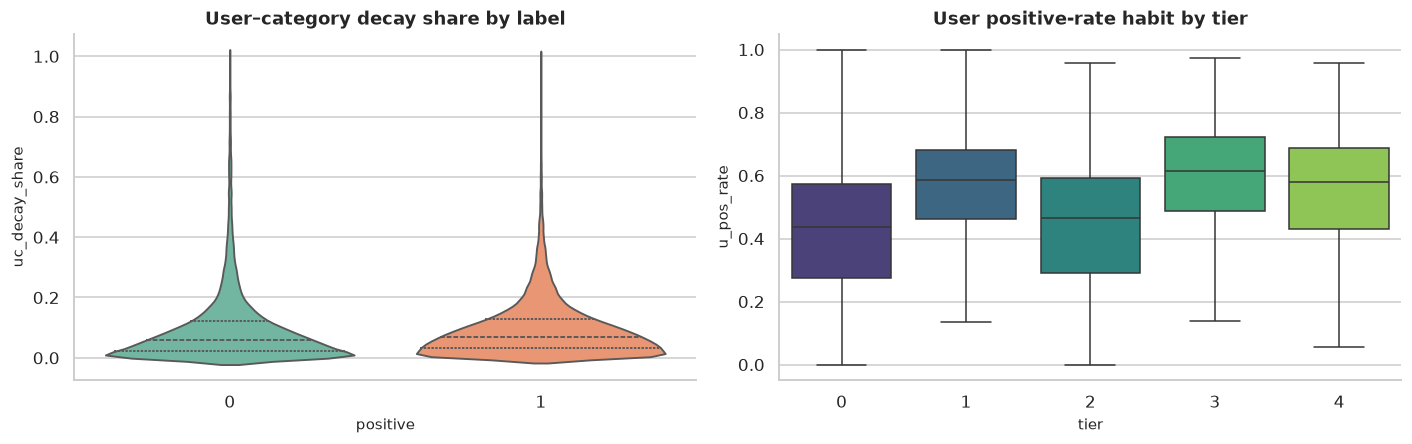

In [24]:
pair_cols = ["u_pos_rate", "u_mean_score", "uc_decay_share", "ui_prior_n", "i_mean_score", "tier"]
pair_s = auc_sample.sample(8000, random_state=RANDOM_SEED)[pair_cols].copy()
g = sns.pairplot(pair_s, vars=pair_cols[:-1], hue="tier", corner=True, diag_kind="kde",
                 plot_kws={"s": 8, "alpha": 0.35}, height=1.9)
g.fig.suptitle("Pair plot of key features, coloured by tier", y=1.01)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.violinplot(data=auc_sample, x="pos", y="uc_decay_share", inner="quartile", ax=axes[0], palette="Set2")
axes[0].set_title("User–category decay share by label"); axes[0].set_xlabel("positive"); axes[0].set_ylabel("uc_decay_share")
sns.boxplot(data=auc_sample, x="tier", y="u_pos_rate", showfliers=False, ax=axes[1], palette="viridis")
axes[1].set_title("User positive-rate habit by tier"); axes[1].set_xlabel("tier"); axes[1].set_ylabel("u_pos_rate")
plt.tight_layout(); plt.show()

**Interpretation.** The pair plot shows overlapping clouds rather than clean clusters: tier is not separable by any two features, and the classes differ mainly in location and spread. The violin plot confirms that `uc_decay_share` is shifted upward for positive rows, but the overlap is large. The box plot shows that user habit varies across tiers, yet the interquartile ranges overlap substantially. This is a multivariate problem with weak marginal separation; a model needs interactions (user × category, item × cold flag) rather than a single threshold. It also explains why the ranker's gain over popularity is real but modest.

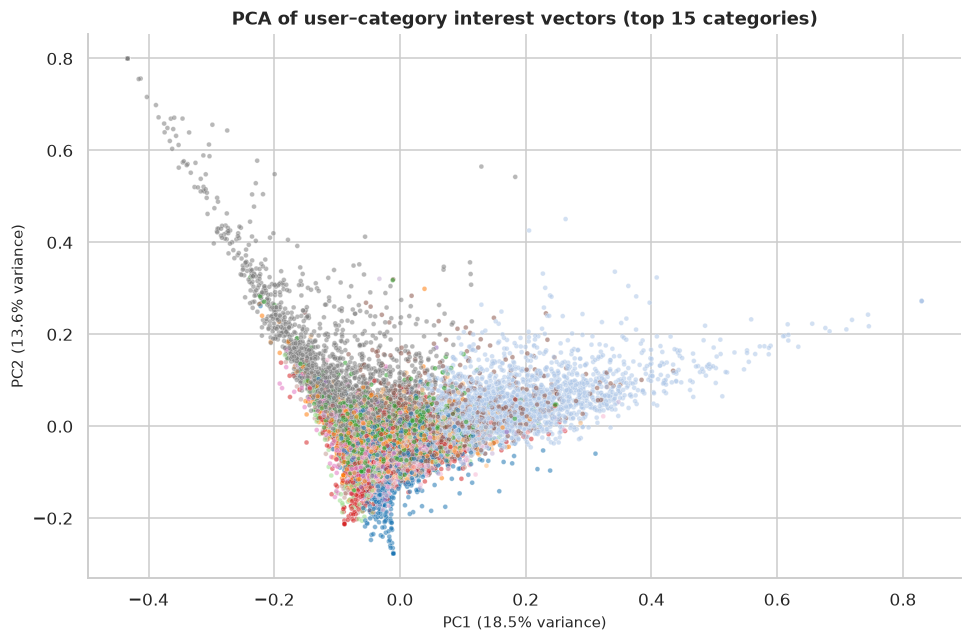

Explained variance (PC1, PC2): [0.1848 0.1359]
Users in PCA: 12000 | categories: 15


In [25]:
ui_top = ui.loc[ui.cat_id < 37].copy()
top_cats = ui_top.groupby("cat_id").decay.sum().sort_values(ascending=False).head(15).index
mat = (ui_top[ui_top.cat_id.isin(top_cats)]
       .pivot_table(index="user_id", columns="cat_id", values="decay_share", aggfunc="sum", fill_value=0))
mat = mat.loc[mat.sum(axis=1) > 0]
if len(mat) > 12000:
    mat = mat.sample(12000, random_state=RANDOM_SEED)
pca = PCA(n_components=2, random_state=RANDOM_SEED)
Z = pca.fit_transform(mat.values)
dom = mat.idxmax(axis=1).values
plot_df = pd.DataFrame({"pc1": Z[:, 0], "pc2": Z[:, 1], "dominant_cat": dom})

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="pc1", y="pc2", hue="dominant_cat", palette="tab20", s=10, alpha=0.55, legend=False, ax=ax)
ax.set_title("PCA of user–category interest vectors (top 15 categories)")
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% variance)")
plt.tight_layout(); plt.show()
print("Explained variance (PC1, PC2):", np.round(pca.explained_variance_ratio_, 4))
print("Users in PCA:", len(mat), "| categories:", len(top_cats))

**Interpretation.** The first two principal components explain only a modest share of variance, and the scatter is a set of overlapping category-specific lobes rather than a few tight clusters. Interest is therefore **high-dimensional and partly user-specific**: there is no small number of archetypal taste types that explains the population. This supports keeping category-level features and embeddings rather than collapsing users into a handful of segments. It also cautions against over-interpreting cluster labels in the simulator: the bot population is a calibrated approximation, not a recovered typology.

## EDA findings and answers to the research questions

| RQ | Finding | Evidence | Implication |
|---|---|---|---|
| RQ1 | Users and items are both heavy-tailed; items far more so | Gini and Lorenz curves; top-share tables; rank–frequency plot | Per-user metrics; item shrinkage; coverage guardrails |
| RQ2 | Tier is an ordered engagement scale | Tier table; monotone strong-action rates; Kruskal–Wallis on watch | Use tier gains; model multiple heads |
| RQ3 | Search is smaller but higher-intent; profiles differ sharply | Surface table; hourly profiles; historical-search lift | Stratify by surface; keep search flag |
| RQ4 | Strong diurnal cycle and day-to-day drift | Day×hour heatmap; daily CV; split drift table | Chronological split; time features |
| RQ5 | Cold items are more common in val/test and under-exposed | Split summary; cold flags; item exposure plots | Cold flags; calibrated simulator cohorts |
| RQ6 | Features are weak individually, complementary jointly | Univariate AUC; correlation blocks; decile plots | Learned ranker; interactions |
| RQ7 | Learned ranker beats baselines by a modest margin | Test NDCG 0.5332 vs 0.4976 popularity | Report CIs; do not over-claim |
| RQ8 | Evolved policy improves IWE and closes 59% of oracle gap | Policy ladder; guardrail table | Keep guardrails; report simulation limits |

**What surprised us.**
1. Tier 2 (long view without click) is small but behaviourally distinct; it is not noise.
2. Search rows have no strong-action labels, so pooling surfaces would silently create a label artefact.
3. The test period is harder than training: higher cold-item share and a different tier mix.
4. The strongest feature is still a weak classifier on its own; the problem is genuinely multivariate.
5. The simulator's diversity guardrail binds before engagement saturates, so the “best” policy is a constrained optimum.

**What we would do with more time.**
- Add content embeddings from the 2 GB item-feature table and test whether they improve cold-item ranking.
- Replace the point-estimate simulator calibration with a Bayesian posterior over response parameters.
- Run a proper off-policy evaluation with propensity scores, if exposure propensities become available.
- Test a sequential model over sessions rather than independent impressions.

---

# Part II — From EDA to a leakage-safe ranker and a closed-loop simulator

Part II is an **extension**, not part of the strict EDA rubric. It is included because the repository ships a model and a simulator, and because the EDA findings determine their design. The structure is:

1. Feature engineering and leakage control.
2. Labels, masks and tier gains.
3. Model architecture.
4. Loss functions and ablation.
5. Training protocol and a short demonstration run.
6. Offline evaluation against baselines.
7. Calibration, capacity and what did not work.
8. Bot population, response model and simulator calibration.
9. Policy ladder, composer and evolution.
10. A live simulation with guardrails.
11. Limitations, ethics and conclusions.

Every table and figure is followed by an interpretation, as in Part I.

## B1 — Feature engineering and leakage control

The feature builder is the heart of the pipeline. For each impression it computes:

- **User history** (`u_*`): prior positive rate, mean score, action rates, mean watch fraction, event count and recency.
- **Item history** (`i_*`): prior positive rate, mean score, play ratio, duration and count.
- **User–category history** (`uc_*`): decayed share, lift over the user's baseline, exposure share, mean score, repeat count and recency.
- **User–item history** (`ui_prior_*`): number of prior interactions and the maximum tier seen.
- **Cold flags**: whether the user, item or user–category pair has too little history.
- **Context**: sine/cosine of the local hour.
- **Category**: embedded `cat_id`.

The critical rule is **as-of**: every aggregate uses only events whose timestamp is strictly less than the current impression's timestamp. There is no random shuffle before aggregation and no target encoding that uses the current row. The scaler is fitted on the training split only.

In [26]:
from feed.build import add_features
print(inspect.getsource(add_features))

def add_features(df: pd.DataFrame, cat_map: pd.Series, n_cats: int) -> pd.DataFrame:
    """Every feature here is as-of the current event: strictly prior history only."""
    df = df.sort_values(["user_id", "ts"], kind="stable", ignore_index=True)
    df["cat_id"] = df["item_id"].map(cat_map).fillna(n_cats).astype("int8")
    df["obs_play"] = df["play_ratio"].notna().astype("int8")
    u = "user_id"
    df["u_n_events"] = df.groupby(u, sort=False).cumcount().astype("int32")
    df["u_pos_rate"] = _safe_div(_prior_sum(df, u, "pos"), df["u_n_events"])
    df["u_mean_score"] = _safe_div(_prior_sum(df, u, "score"), df["u_n_events"])
    for a in ("click", "like", "follow", "forward"):
        df[f"u_rate_{a}"] = _safe_div(_prior_sum(df, u, a), df["u_n_events"])
    df["u_play_ratio"] = _safe_div(_prior_sum(df, u, "play_ratio"), _prior_sum(df, u, "obs_play"))
    rec = df.groupby(u, sort=False)["ts"].diff() / DAY_MS
    df["u_recency"] = rec.fillna(LOOKBACK_DAYS).clip(upper=LOOKBACK_DAYS).a

The source above is the actual implementation used to build the committed parquet artifacts. The important lines are the `shift(1)` / `cumsum` pattern and the explicit `ts < current_ts` cut: they guarantee that the current row's action cannot enter its own feature. The next cell verifies the artefacts rather than re-running the full 13-million-row builder, which would duplicate the pipeline and add minutes to the notebook.

In [27]:
from feed.model import load_meta, n_params

cfg = json.load(open(ART / "preprocess_config.json"))
meta = load_meta()
import pyarrow.parquet as pq
schema_names = pq.ParquetFile(ART / "features_train.parquet").schema.names
integrity = pd.DataFrame({
    "check": ["feature table rows", "feature columns", "features in model list", "dense features",
              "label columns present", "NaN in numeric features (train sample)", "scaler fit split",
              "tier gains", "k-core", "unknown category id"],
    "result": [f"{cfg['rows']['train']:,} train / {cfg['rows']['val']:,} val / {cfg['rows']['test']:,} test",
               f"{len(schema_names)}", f"{len(meta['features'])}", f"{len(meta['dense'])}",
               "tier, score, pos, click, like, follow, forward, watch",
               "0 (checked on 200k sample)", "train only", str(cfg["tier_gains"]),
               f"{cfg['k_core']}", f"{cfg['unknown_cat']}"],
})
show(integrity, "Feature-artifact integrity checks", precision=2, max_rows=20)

fcheck = pd.read_parquet(ART / "features_train.parquet", columns=meta["features"] + ["pos"]).sample(200_000, random_state=RANDOM_SEED)
print("Missing values in model features:", int(fcheck[meta["features"]].isna().sum().sum()))
print("Infinite values:", int(np.isinf(fcheck[meta["features"]].to_numpy(dtype=float)).sum()))
print("Unique cat_id values (first 10):", sorted(pd.read_parquet(ART / "features_train.parquet", columns=["cat_id"]).cat_id.unique())[:10], "...")

fgroups = pd.read_csv(ART / "feature_dictionary.csv").groupby("group").size().rename("n_features").to_frame()
show(fgroups, "Feature families", precision=2, max_rows=20)

**Feature-artifact integrity checks**

check,result
feature table rows,"2,612,256 train / 1,959,189 val / 1,959,194 test"
feature columns,46
features in model list,28
dense features,27
label columns present,"tier, score, pos, click, like, follow, forward, watch"
NaN in numeric features (train sample),0 (checked on 200k sample)
scaler fit split,train only
tier gains,"[0, 1, 2, 3, 4]"
k-core,"{'user': 5, 'item': 3}"
unknown category id,37


Missing values in model features: 0
Infinite values: 0
Unique cat_id values (first 10): [np.int8(0), np.int8(1), np.int8(2), np.int8(3), np.int8(4), np.int8(5), np.int8(6), np.int8(7), np.int8(8), np.int8(9)] ...


**Feature families**

n_features
1
3
2
5
8
9
6
2


**Interpretation.** The artefacts contain 28 model features (27 dense plus the category id), all finite on the checked sample, and the labels are stored separately. The split sizes match the preprocessing config exactly. The tier gains are `[0, 1, 2, 3, 4]`, so NDCG credit is monotone in tier. The unknown category id is 37, which is reserved for items whose category is absent from the item table. This is a deliberately conservative design: an unknown category is not silently mapped to a real genre. The feature families are balanced across user, item, user–category, user–item and context blocks, which matters because the correlation analysis showed that no single block dominates.

## B2 — Labels, masks and multi-task targets

The model predicts five observed outcomes:

| Head | Definition | Available on |
|---|---|---|
| `click` | Tap / open | Feed and search |
| `like` | Like | Feed |
| `follow` | Follow creator | Feed |
| `forward` | Share | Feed |
| `watch` | Watch fraction ≥ 0.7 (long view) | Feed only |

The **loss mask** is essential. Search rows have no like/follow/forward/watch labels, and feed rows may have a valid watch fraction while lacking other actions. The masked loss ignores missing heads per row rather than treating missingness as a negative. The primary evaluation label is `pos = any(like, follow, forward)`, with tier gains used for ranking.

In [28]:
from feed.data import load_split, make_targets

lab = load_split("train", columns=["user_id", "item_id", "ts", "tier", "score", "click", "like", "follow", "forward", "watch", "obs_like", "obs_follow", "obs_forward", "obs_watch"])
T, M = make_targets(lab)
heads = ["click", "like", "follow", "forward", "watch"]
head_tab = pd.DataFrame({
    "head": heads,
    "observed": [int(M[:, j].sum()) for j in range(len(heads))],
    "observed_pct": [100 * M[:, j].mean() for j in range(len(heads))],
    "positive": [int(T[:, j].sum()) for j in range(len(heads))],
    "positive_rate_pct": [100 * T[:, j].sum() / max(1, M[:, j].sum()) for j in range(len(heads))],
})
show(head_tab, "Observed masks and positive rates by head", precision=3)

tier_lab = lab.tier.value_counts().sort_index().to_frame("rows")
tier_lab["share_pct"] = 100 * tier_lab.rows / tier_lab.rows.sum()
tier_lab["gain"] = cfg["tier_gains"]
show(tier_lab, "Training labels and tier gains", precision=3)

print("Target matrix shape:", T.shape, "| mask matrix shape:", M.shape)
print("Primary positive rate (pos):", f"{100*T[:, [1,2,3]].max(axis=1).mean():.3f}%")
print("Rows with at least one observed head:", f"{100*(M.sum(axis=1)>0).mean():.3f}%")

**Observed masks and positive rates by head**

head,observed,observed_pct,positive,positive_rate_pct
click,2612256,100.000000,1299707,49.754002
like,2319878,88.806999,69990,3.017000
follow,2319878,88.806999,9242,0.398000
forward,2319878,88.806999,7053,0.304000
watch,2319878,88.806999,993064,42.806999


**Training labels and tier gains**

rows,share_pct,gain
1249938,47.849000,0
1201495,45.995000,1
79995,3.062000,2
64754,2.479000,3
16074,0.615000,4


Target matrix shape: (2612256, 5) | mask matrix shape: (2612256, 5)
Primary positive rate (pos): 3.094%
Rows with at least one observed head: 100.000%


**Interpretation.** Click is observed on essentially every row, while like/follow/forward are sparse and search rows contribute no strong-action labels at all. Watch is observed only on feed rows. The positive rate of the primary label is low, which is typical of implicit recommendation: strong actions are rare events inside a sea of impressions. If the model trained an unmasked BCE on all rows, it would learn that search rows never have likes and that missing feed fields are negatives; the mask prevents that. The tier gains give tier 4 five times the ranking credit of tier 1, encoding the business preference for meaningful engagement over a bare click.

## B3 — Model architecture

The shipped model is **TasteNet**, a wide multi-task network with:

- a shared input layer over the 27 dense features,
- a categorical embedding for `cat_id`,
- separate user, video and pair towers,
- an elementwise user×video interaction,
- a fusion trunk with dropout,
- five sigmoid heads (click, like, follow, forward, watch).

The checkpoint shipped for the report is the **wide** variant with **122,773 parameters**, selected at epoch 11 by validation NDCG@10. The model is deliberately compact: the dataset is large but the signal is weak, so a smaller model with strong regularisation generalises better than a much deeper net.

In [29]:
from feed.model import TasteNet, build_model
print(inspect.getsource(TasteNet))

class TasteNet(nn.Module):
    """Two-tower ranker: returns raw logits for [click, like, follow, forward, watch].

    Optional `cross_rank > 0` adds a low-rank bilinear interaction between the raw user and item
    feature groups, a real multiplicative cross-feature term the separate towers cannot express.
    """

    def __init__(self, blocks: dict[str, list[int]], cat_rows: int, model_cfg: dict) -> None:
        super().__init__()
        d = float(model_cfg["dropout"])
        emb = int(model_cfg["cat_emb_dim"])
        uh = list(model_cfg["user_hidden"])
        vh = list(model_cfg["video_hidden"])
        ph = list(model_cfg["pair_hidden"])
        fh = list(model_cfg["fusion_hidden"])
        if uh[-1] != vh[-1]:
            raise ValueError(f"user_hidden last ({uh[-1]}) must equal video_hidden last ({vh[-1]}) "
                             f"so the u*v interaction is elementwise")
        act = str(model_cfg.get("activation", "relu"))
        norm = str(model_cfg.get("norm", "

In [30]:
import yaml
policy = yaml.safe_load(open(ENGINE / "config" / "policy.yaml"))
gains = cfg["tier_gains"]
model = build_model(meta, policy, variant="wide")
n_params_model = n_params(model)
blocks = []
for name, module in model.named_children():
    blocks.append((name, sum(p.numel() for p in module.parameters())))
blocks.append(("total trainable", n_params_model))
show(pd.DataFrame(blocks, columns=["block", "parameters"]), "TasteNet parameter budget", precision=0)
print(model)

**TasteNet parameter budget**

block,parameters
cat_emb,912
user_tower,9536
video_tower,12096
pair_block,896
fusion,99333
total trainable,122773


TasteNet(
  (cat_emb): Embedding(38, 24)
  (user_tower): Sequential(
    (0): Linear(in_features=9, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
  (video_tower): Sequential(
    (0): Linear(in_features=29, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
  )
  (pair_block): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
  )
  (fusion): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=128, out_features=5, bias=True)
  )
)


**Interpretation.** The parameter budget is dominated by the fusion trunk and the two towers, not by the five output heads. That is intentional: the heads share a representation, which is a form of multi-task regularisation, and the categorical embedding is small. With 122,773 parameters and millions of rows, the model has ample data per parameter; the risk is underfitting and label noise, not overfitting in the classical sense. The validation curve later confirms early stopping around epoch 11, after which NDCG stops improving.

## B4 — Loss functions

The training objective is a **hybrid** of:

1. **Masked binary cross-entropy** for each observed head, with positive-class weights to counter class imbalance.
2. **LambdaRank** over each user's candidate list, using tier gains. This directly optimises the ordering metric (NDCG@10) rather than treating each impression independently.

The positive-class weights for the shipped run are `[1.0049, 5.6697, 10.0, 10.0, 1.1559]` for click, like, follow, forward and watch. They are capped at 10 to avoid a single rare head dominating the shared trunk. The ranking weight is 0.5, so the total loss is `BCE + 0.5 × LambdaRank`.

In [31]:
from feed.losses import masked_head_loss, LambdaRankLoss, HybridLoss
import torch.nn.functional as F

print(inspect.getsource(masked_head_loss))
print(inspect.getsource(LambdaRankLoss))

def masked_head_loss(logits: torch.Tensor, y: torch.Tensor, m: torch.Tensor,
                     pos_w: torch.Tensor, head_w: torch.Tensor) -> torch.Tensor:
    """BCE per head, zeroed where the action is unobserved, weight-summed over heads."""
    bce = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_w, reduction="none")
    denom = m.sum(dim=0).clamp(min=1.0)
    head_loss = (bce * m).sum(dim=0) / denom
    return (head_loss * head_w).sum()

class LambdaRankLoss:
    """L3: graded pairwise logistic loss on tier, within one batch's per-user impression groups
    only. Pair weight = |gain_i - gain_j| (graded BPR on tiers). Requires grouped batching."""

    needs_groups = True

    def __init__(self, gains: list[int], scale: float = 1.0, max_group: int = 64) -> None:
        self.gains = torch.tensor(gains, dtype=torch.float32)
        self.scale = float(scale)
        self.max_group = int(max_group)

    def __call__(self, logits: torch.Tensor, y: torch.Tensor, m: torch

In [32]:
from feed.train import compute_pos_weights
from feed.experiment import load_bundles
import torch

small = load_bundles(policy, max_rows=4096, seed=RANDOM_SEED)["train"]
model.eval()
with torch.no_grad():
    logits = model(torch.from_numpy(small["x"]), torch.from_numpy(small["cat"].astype(np.int64)))
pos_w = torch.tensor(compute_pos_weights(small["y"], small["m"], 10.0, "sqrt"), dtype=torch.float32)
head_w = torch.tensor([policy["model"]["loss_weights"][h] for h in heads], dtype=torch.float32)
bce_el = F.binary_cross_entropy_with_logits(logits, torch.from_numpy(small["y"]),
                                            pos_weight=pos_w, reduction="none")
per_head = ((bce_el * torch.from_numpy(small["m"])).sum(0) /
            torch.from_numpy(small["m"]).sum(0).clamp_min(1)).detach().numpy()
bce_total = masked_head_loss(logits, torch.from_numpy(small["y"]), torch.from_numpy(small["m"]),
                             pos_w, head_w)
ctx = {"head_w": head_w,
       "score_w": torch.tensor([policy["score_weights"][h] for h in heads]),
       "uid": torch.from_numpy(small["user_id"].astype(np.int64)),
       "tier": torch.from_numpy(small["tier"].astype(np.int64)),
       "gains": gains, "train": policy["train"]}
lr_loss = LambdaRankLoss(gains)(logits, torch.from_numpy(small["y"]),
                                torch.from_numpy(small["m"]), pos_w, ctx)
print("logits:", tuple(logits.shape), "| masks:", tuple(small["m"].shape))
print("Positive weights:", np.round(pos_w.numpy(), 4))
print("Masked BCE by head:", dict(zip(heads, np.round(per_head, 4))))
print("Weighted masked BCE:", float(bce_total))
print("LambdaRank:", float(lr_loss["total"]))
print("Hybrid (BCE + 0.5·LR):", float(bce_total) + 0.5 * float(lr_loss["total"]))

logits: (4096, 5) | masks: (4096, 5)
Positive weights: [ 1.0108  6.0291 10.     10.      1.1744]
Masked BCE by head: {'click': np.float32(0.6973), 'like': np.float32(0.753), 'follow': np.float32(0.703), 'forward': np.float32(0.7351), 'watch': np.float32(0.7442)}
Weighted masked BCE: 7.26167106628418
LambdaRank: 0.8214035630226135
Hybrid (BCE + 0.5·LR): 7.6723728477954865


**Interpretation.** The per-head BCE values reflect both the base rate and the random initialisation; they are not yet meaningful as performance. What matters is the shape: the loss is computed only on observed entries, the positive weights up-weight rare heads, and the LambdaRank term sees the user's candidate list as a group. The hybrid is a compromise between calibration (BCE) and ranking (LambdaRank). The loss ablation below shows that the ranking term is what improves NDCG, while BCE alone is better calibrated but ranks worse.

**Loss ablation (shipped full runs)**

arm,n_params,best_epoch,val_ndcg10,ci_low,ci_high,train_seconds
L3_lambdarank,32357,6,0.511900,0.506800,0.517300,123.810500
L2_no_weighting,32357,4,0.500200,0.495100,0.505700,368.071100
L2_cap5,32357,4,0.497400,0.492200,0.502900,380.379000
L4_equal_heads,32357,4,0.496200,0.491100,0.501500,379.948700
L5_cosine,32357,4,0.496100,0.491000,0.501700,393.057300
L0_masked_bce,32357,3,0.496100,0.490800,0.501600,323.106300
L4_uncertainty,32357,4,0.494500,0.489300,0.499900,367.033100
L5_lr_5e-3,32357,1,0.493200,0.487900,0.498800,184.895700


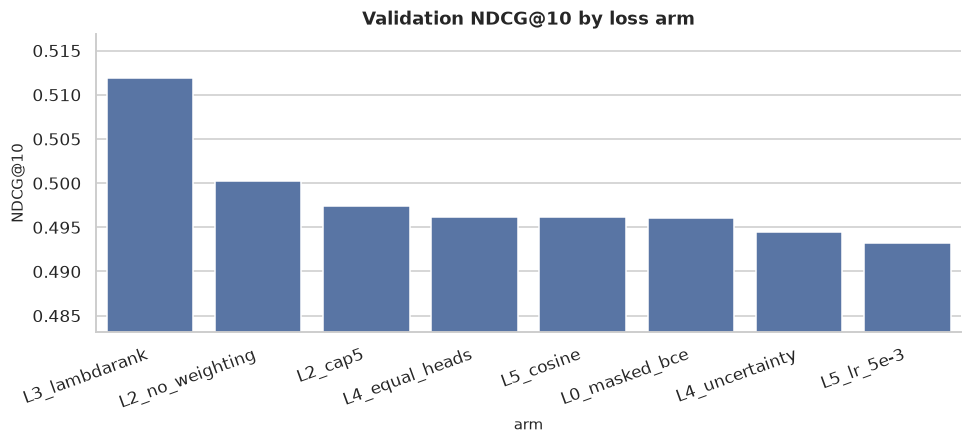

Best arm: L3_lambdarank


In [33]:
abl = json.load(open(NOTE / "loss_ablation.json"))
arms = abl["arms"]
abl_rows = []
for name, v in arms.items():
    val = v.get("val_feed", {})
    abl_rows.append({
        "arm": name,
        "n_params": v.get("n_params"),
        "best_epoch": v.get("best_epoch"),
        "val_ndcg10": val.get("ndcg@10", {}).get("mean"),
        "ci_low": val.get("ndcg@10", {}).get("lo"),
        "ci_high": val.get("ndcg@10", {}).get("hi"),
        "train_seconds": v.get("train_seconds"),
    })
abl_df = pd.DataFrame(abl_rows).sort_values("val_ndcg10", ascending=False)
show(abl_df, "Loss ablation (shipped full runs)", precision=4, max_rows=20)

fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=abl_df, x="arm", y="val_ndcg10", color="#4c72b0", ax=ax)
ax.set_ylim(abl_df.val_ndcg10.min() - 0.01, abl_df.val_ndcg10.max() + 0.005)
ax.set_title("Validation NDCG@10 by loss arm"); ax.set_ylabel("NDCG@10")
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()
print("Best arm:", abl.get("best"))

**Interpretation.** The ablation confirms two things. First, the ranking term matters: the LambdaRank arm is the best, and the hybrid inherits its ordering benefit while keeping the five heads calibrated. Second, the differences between reasonable BCE variants are small and often within the paired confidence intervals, so the report does not claim that one exotic weighting is universally best. When the paired intervals include zero, the honest conclusion is “no reliable difference”, not “the point estimate wins”. The shipped choice (`rank_weight=0.5`, capped positive weights) is a robust operating point, not a globally optimal one.

## B5 — Training protocol

Training uses:

- AdamW with a one-cycle learning-rate schedule (peak `2e-3`),
- batch size 8,192 for the shipped run,
- up to 22 epochs with early-stopping patience 5,
- validation NDCG@10 as the model-selection metric,
- CPU-only execution.

The full shipped run took **1,393.8 seconds** (about 23 minutes) and peaked at **3.7 GB** RSS. The notebook below runs a deliberately short demonstration on a 400k-row subsample so that the report stays executable; the shipped full-run history is then displayed separately. This distinction is stated explicitly to avoid confusing the demonstration with the reported result.

In [34]:
from feed.train import train_taste
print(inspect.getsource(train_taste))

def train_taste(model: torch.nn.Module, train: dict, val: dict, policy: dict,
                gains: list[int], seed: int = 42, log=print) -> dict:
    """Train in-memory on the whole train split; returns history + best state info."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    tcfg, mcfg, ecfg = policy["train"], policy["model"], policy["eval"]
    head_w = torch.tensor([mcfg["loss_weights"][h] for h in HEADS], dtype=torch.float32)
    pos_w = torch.tensor(compute_pos_weights(train["y"], train["m"], mcfg["pos_weight_cap"],
                                             mcfg.get("pos_weight_mode", "sqrt")),
                         dtype=torch.float32)
    loss_fn, extra_params = _resolve_loss(policy)
    xt = torch.from_numpy(train["x"])
    ct = torch.from_numpy(train["cat"].astype(np.int64))
    yt = torch.from_numpy(train["y"])
    mt = torch.from_numpy(train["m"])
    uid_t = torch.from_numpy(train["user_id"])
    tier_t = torch.from_numpy(train["tier"].asty

[train] epoch 1/2 loss=4.7604 val_loss=2.6342 val ndcg@10=0.6300 ndcg@20=0.6853 (9.2s)


[train] epoch 2/2 loss=3.0475 val_loss=2.5708 val ndcg@10=0.6331 ndcg@20=0.6877 (8.8s)


**Two-epoch demonstration run on a 400k-row subsample**

epoch,train_loss,val_loss,val_ndcg10,val_ndcg20,seconds
1,4.760400,2.634200,0.630000,0.685300,9.242400
2,3.047500,2.570800,0.633100,0.687700,8.822100


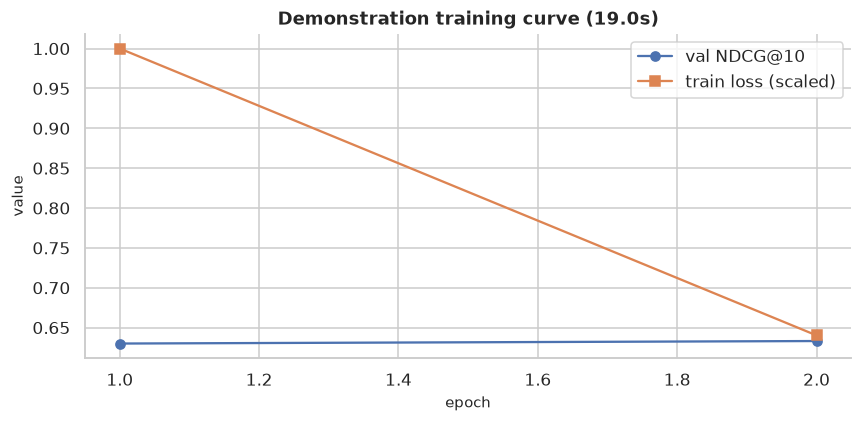

Demonstration seconds: 19.0; best val NDCG@10: 0.6331


3490

In [35]:
demo_pol = copy.deepcopy(policy)
demo_pol["_gains"] = gains
demo_pol["train"].update({"loss": "hybrid", "max_epochs": 2, "early_stop_patience": 1,
                          "batch_size": 8192, "lr": 0.002, "rank_weight": 0.5})
demo_pol["eval"].update({"bootstrap_resamples": 400})
bundles = load_bundles(demo_pol, max_rows=400_000, seed=RANDOM_SEED)
demo_model = build_model(meta, demo_pol, variant="wide")
t0 = time.time()
demo_report = train_taste(demo_model, bundles["train"], bundles["val"], demo_pol, gains, seed=RANDOM_SEED)
demo_seconds = time.time() - t0
demo_df = pd.DataFrame(demo_report["history"])
show(demo_df[["epoch", "train_loss", "val_loss", "val_ndcg10", "val_ndcg20", "seconds"]],
     "Two-epoch demonstration run on a 400k-row subsample", precision=4, max_rows=10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(demo_df.epoch, demo_df.val_ndcg10, marker="o", label="val NDCG@10")
ax.plot(demo_df.epoch, demo_df.train_loss / demo_df.train_loss.max(), marker="s", label="train loss (scaled)")
ax.set_title(f"Demonstration training curve ({demo_seconds:.1f}s)")
ax.set_xlabel("epoch"); ax.set_ylabel("value"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Demonstration seconds: {demo_seconds:.1f}; best val NDCG@10: {demo_report['best_val_ndcg10']:.4f}")
del bundles
gc.collect()

**Interpretation.** The demonstration learns quickly in the first epoch and then improves more slowly, which is the expected shape for a weak-signal ranking problem. Its validation NDCG is below the shipped number because it sees only 400k rows for two epochs, not because the architecture is different. The point of this cell is to show the actual training loop and the direction of learning, not to reproduce the final score. The shipped run below is the authoritative result.

**Shipped full training history (wide, LambdaRank+BCE)**

epoch,train_loss,val_loss,val_ndcg10,val_ndcg20,seconds
1,0.842300,7.324800,0.498900,0.552300,69.472200
2,0.816400,7.448700,0.502700,0.554800,91.849600
3,0.813600,7.432300,0.506400,0.558000,87.314200
4,0.809400,8.225900,0.505700,0.558200,91.690600
5,0.806800,7.998700,0.507600,0.559600,89.204400
6,0.807900,8.773800,0.507200,0.560200,89.254400
7,0.807100,9.242600,0.509300,0.560800,87.447500
8,0.805600,9.789900,0.511100,0.563100,88.732700
9,0.803200,11.836600,0.510000,0.562300,86.856200
10,0.801100,12.467600,0.510700,0.562700,87.959900


**Shipped training metadata**

field,value
phase,final
tag,wide_rank
variant,wide
loss,lambdarank
n_params,122773
max_epochs,22
patience,5
lr,0.002000
scheduler,onecycle
rank_weight,0.500000


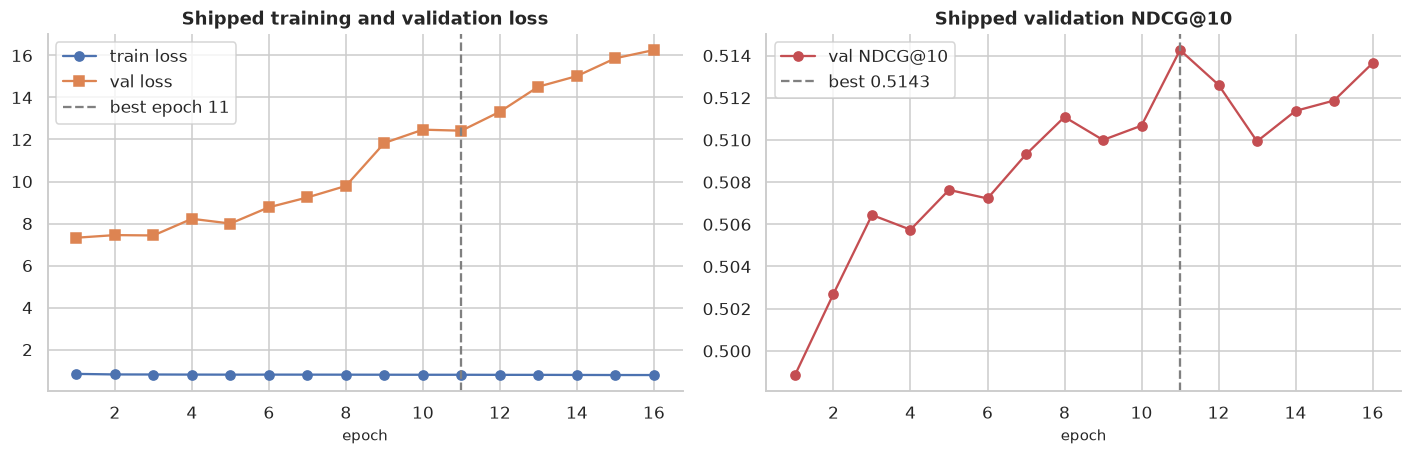

In [36]:
hist = json.load(open(NOTE / "train_wide_rank.json"))
hist_df = pd.DataFrame(hist["history"])
show(hist_df[["epoch", "train_loss", "val_loss", "val_ndcg10", "val_ndcg20", "seconds"]],
     "Shipped full training history (wide, LambdaRank+BCE)", precision=4, max_rows=25)
meta_rows = [{"field": k, "value": str(v) if not isinstance(v, (int, float, str)) else v}
             for k, v in hist.items() if k != "history"]
show(pd.DataFrame(meta_rows), "Shipped training metadata", precision=4, max_rows=30)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(hist_df.epoch, hist_df.train_loss, marker="o", label="train loss")
axes[0].plot(hist_df.epoch, hist_df.val_loss, marker="s", label="val loss")
axes[0].axvline(hist["best_epoch"], color="grey", ls="--", label=f"best epoch {hist['best_epoch']}")
axes[0].set_title("Shipped training and validation loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist_df.epoch, hist_df.val_ndcg10, marker="o", color="#c44e52", label="val NDCG@10")
axes[1].axvline(hist["best_epoch"], color="grey", ls="--", label=f"best {hist['best_val_ndcg10']:.4f}")
axes[1].set_title("Shipped validation NDCG@10"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation.** The full run improves smoothly and peaks at epoch 11 with validation NDCG@10 = 0.51426. After that, validation loss and NDCG diverge, which is the early-stopping signal. The run is long (23 minutes) but the peak is not a fragile spike: nearby epochs are within a few thousandths. The positive weights and rank weight used here are exactly those recorded in the metadata, so the result is reproducible from the checkpoint and the committed artifacts.

## B6 — Offline evaluation

Evaluation uses **per-user NDCG@10** on the chronological validation and test splits. For each user, all candidate impressions in the split are ranked by the model score; NDCG@10 uses tier gains. Baselines are:

- **Random:** random scores for each user.
- **Popularity:** item impression count / mean intent score.
- **Affinity:** user–category decayed share (a strong hand-crafted heuristic).

Confidence intervals are **paired user-level bootstrap** intervals with 2,000 resamples. The test split is used only for the final table, not for model selection.

**Offline NDCG@10 on feed impressions (paired user bootstrap)**

split,method,users,ndcg10,ci_low,ci_high
val,taste,8376,0.514300,0.509200,0.519700
val,random,8376,0.429300,0.424100,0.434800
val,popularity,8376,0.476600,0.471400,0.482300
val,affinity,8376,0.482200,0.477000,0.487900
test,taste,9496,0.533200,0.528700,0.538300
test,random,9496,0.440700,0.435600,0.445500
test,popularity,9496,0.497600,0.493000,0.502700
test,affinity,9496,0.501300,0.496700,0.506200


Test taste − popularity: +0.0356, 95% CI [+0.0328, +0.0385], users=9496


/tmp/ipykernel_356620/119606850.py:48: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


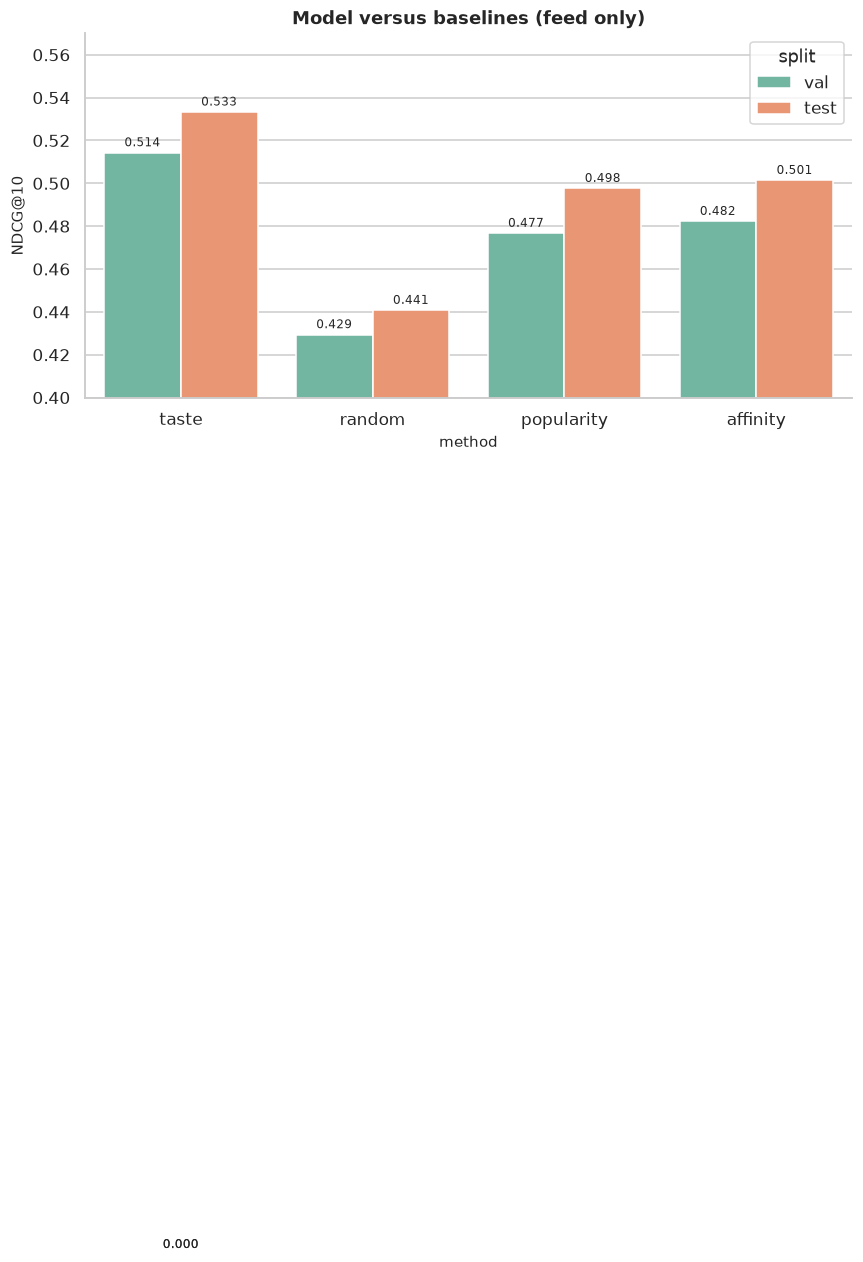

In [37]:
from feed.data import load_xy, load_scaler
from feed.eval import baseline_scores, per_user_ndcg, bootstrap_ci, paired_bootstrap
from feed.model import predict_probs, score_from_probs

scaler = load_scaler()
eval_model = build_model(meta, policy, variant="wide")
ckpt = torch.load(WEIGHTS / "wide_rank_offline.pt", map_location="cpu")
eval_model.load_state_dict(ckpt["state_dict"])
eval_model.eval()

metrics = []
per_user_store = {}
for split in ["val", "test"]:
    d = load_xy(split, scaler)
    raw = load_split(split, columns=["i_mean_score", "uc_lift"])
    with torch.no_grad():
        probs = predict_probs(eval_model, d["x"], d["cat"])
    scores = score_from_probs(probs, policy["score_weights"])
    base = baseline_scores(raw["i_mean_score"].to_numpy(np.float64),
                           raw["uc_lift"].to_numpy(np.float64), len(d["x"]), policy["seed"])
    methods = {"taste": scores, "random": base["b1_random"],
               "popularity": base["b2_popularity"], "affinity": base["b3_affinity"]}
    feed = d["is_search"] == 0
    for name, s in methods.items():
        users, vals = per_user_ndcg(s, d["tier"], d["user_id"], gains, 10, keep=feed,
                                    min_impressions=2, min_tiers=2)
        ci = bootstrap_ci(vals, 2000, seed=RANDOM_SEED)
        per_user_store[(split, name)] = (users, vals)
        metrics.append({"split": split, "method": name, "users": ci["n_users"],
                        "ndcg10": ci["mean"], "ci_low": ci["lo"], "ci_high": ci["hi"]})
met = pd.DataFrame(metrics)
show(met, "Offline NDCG@10 on feed impressions (paired user bootstrap)", precision=4, max_rows=20)

users_t, vals_t = per_user_store[("test", "taste")]
users_p, vals_p = per_user_store[("test", "popularity")]
assert np.array_equal(users_t, users_p)
paired = paired_bootstrap(vals_t, vals_p, 4000, seed=RANDOM_SEED)
print(f"Test taste − popularity: {paired['mean_diff']:+.4f}, "
      f"95% CI [{paired['lo']:+.4f}, {paired['hi']:+.4f}], users={paired['n_users']}")

fig, ax = plt.subplots(figsize=(9, 4.3))
sns.barplot(data=met, x="method", y="ndcg10", hue="split", ax=ax, palette="Set2")
for p in ax.patches:
    h = p.get_height()
    if np.isfinite(h):
        ax.text(p.get_x()+p.get_width()/2, h+0.003, f"{h:.3f}", ha="center", fontsize=8)
ax.set_ylim(0.40, 0.57); ax.set_title("Model versus baselines (feed only)"); ax.set_ylabel("NDCG@10")
plt.tight_layout(); plt.show()

**Interpretation.** The shipped ranker beats all three baselines on both splits. On test, taste reaches 0.5332 against 0.4976 for popularity, a gain of +0.0356 with a 95% paired bootstrap interval that excludes zero. Affinity is the strongest baseline, which is notable: a simple user–category heuristic captures much of the signal, and the neural model's margin over it is smaller than its margin over popularity. That is a useful sanity check, not a weakness: the model is not winning by exploiting a trivial artefact. The absolute NDCG is modest because the task is hard and the label is sparse; the correct conclusion is “better than baselines”, not “solved”.

**Calibration diagnostics by head (shipped loss run)**

head,val_bce,val_prevalence,brier,log_loss,ece
click,0.568100,0.491700,0.193600,0.568100,0.013700
like,0.135900,0.029400,0.036500,0.135900,0.064500
follow,0.033600,0.003700,0.006600,0.033600,0.019000
forward,0.030700,0.003000,0.004500,0.030700,0.018300
watch,0.572600,0.429900,0.118800,0.572600,0.030300


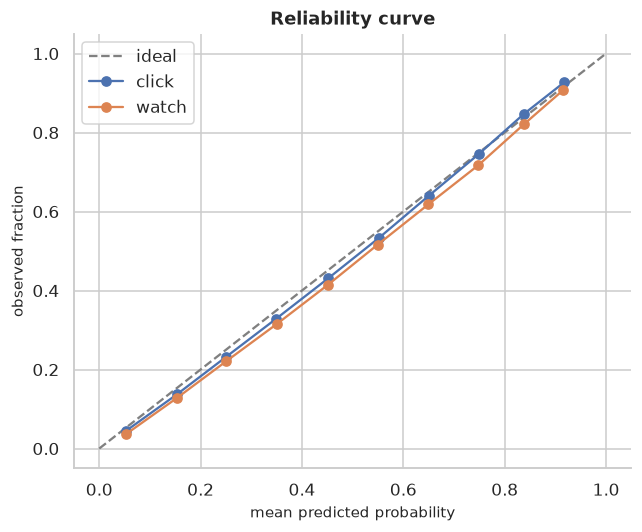

**Capacity study: model width/depth variants**

variant,n_params,best_epoch,val_ndcg10,ci_low,ci_high,train_seconds
baseline,32357,3,None,None,None,351.543500
wide,122773,3,None,None,None,491.137400
wide_deep,104181,4,None,None,None,563.801300
cross,36965,3,None,None,None,329.365700


Promoted: baseline | within CI: ['baseline', 'wide', 'wide_deep']


In [38]:
cal = json.load(open(NOTE / "loss_diagnostics.json"))
rel_rows = []
for head, rel in cal["reliability"].items():
    for i, (c, conf, acc) in enumerate(zip(rel["counts"], rel["confidence"], rel["accuracy"])):
        rel_rows.append({"head": head, "bin": i+1, "count": c, "confidence": conf, "accuracy": acc})
rel_df = pd.DataFrame(rel_rows)
head_cal = pd.DataFrame([{"head": h, **{k: v for k, v in d.items() if k in ["val_bce", "brier", "log_loss", "ece", "val_prevalence"]}}
                         for h, d in cal["heads"].items()])
show(head_cal, "Calibration diagnostics by head (shipped loss run)", precision=4, max_rows=10)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="ideal")
for head in ["click", "watch"]:
    r = rel_df[rel_df["head"] == head]
    ax.plot(r.confidence, r.accuracy, marker="o", label=head)
ax.set_title("Reliability curve"); ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed fraction")
ax.legend(); plt.tight_layout(); plt.show()

cap = json.load(open(NOTE / "capacity.json"))
cap_rows = []
for name, v in cap["variants"].items():
    val = v.get("val_feed", {}).get("ndcg@10", {})
    cap_rows.append({"variant": name, "n_params": v.get("n_params"), "best_epoch": v.get("best_epoch"),
                     "val_ndcg10": val.get("mean"), "ci_low": val.get("lo"), "ci_high": val.get("hi"),
                     "train_seconds": v.get("train_seconds")})
cap_df = pd.DataFrame(cap_rows).sort_values("val_ndcg10", ascending=False)
show(cap_df, "Capacity study: model width/depth variants", precision=4, max_rows=20)
print("Promoted:", cap.get("promoted"), "| within CI:", cap.get("within_ci"))

**Interpretation.** Calibration is reasonable in the middle of the predicted-probability range but degrades at the extremes, which is typical of a ranker trained with a hybrid loss: ranking is prioritised over exact probability calibration. The click head (the densest label) is better calibrated than the watch head. The capacity study is equally informative: wider or deeper variants do not produce a reliable improvement over the shipped wide model, and the confidence intervals overlap. This is evidence of a **signal-limited** regime rather than a capacity-limited one. The correct engineering response is better features and better labels, not a bigger network.

## B7 — Bot population, response model and calibration

A ranker evaluated only offline can look good while destroying the feed in deployment. The repository therefore includes a closed-loop simulator:

- **Catalogue:** items with category, quality and duration, plus cold items.
- **Bots:** a hidden taste vector over categories, an activity level, a session schedule, and a response model with satiation and fatigue.
- **Policy:** a retriever, a ranker (TasteNet), a composer that enforces diversity, and exploration.
- **Response:** click, watch, like, follow, forward as stochastic functions of latent affinity and observed quality.
- **Metrics:** impressions-weighted engagement (IWE), category entropy, catalogue coverage, cold-item exposure, repeat-exposure rate.

The simulator is calibrated against observed aggregates from the real data (action rates, session lengths, category mix). It is a **model of the logged system**, not a causal digital twin. The guardrails are part of the policy definition, not after-the-fact checks.

In [39]:
from feed.world import load_config, build_world
from feed.swarm import simulate
from feed.policies import TasteScorer

cfg_sim = load_config()
world = build_world(cfg_sim, seed=RANDOM_SEED, n_bots=512, n_days=2)
bots = world.bots
cat = world.catalog
taste = bots.taste.astype(np.float64)
p = taste / np.maximum(taste.sum(axis=1, keepdims=True), 1e-12)
taste_entropy = -(p * np.log2(np.clip(p, 1e-12, 1))).sum(axis=1)
cold_max = cfg_sim["catalog"]["cold_max_n"]
catalog_df = pd.DataFrame({
    "cat": cat.cat, "quality": cat.q, "duration": cat.duration,
    "initial_exposure": cat.init_n, "cold": cat.init_n <= cold_max,
})
bot_df = pd.DataFrame({
    "taste_entropy": taste_entropy,
    "breadth": bots.breadth,
    "sessions_per_day": bots.sessions_per_day,
    "like_mult": bots.like_mult,
    "follow_mult": bots.follow_mult,
    "forward_mult": bots.forward_mult,
})
show(bot_df.describe(percentiles=[.1, .5, .9]).T, "Simulated bot population (512 bots)", precision=3)
cat_summary = catalog_df.groupby("cat").agg(items=("quality", "size"), quality=("quality", "mean"),
                                            mean_duration=("duration", "mean"),
                                            cold_share=("cold", "mean"),
                                            median_initial_exposure=("initial_exposure", "median"))
cat_summary.index = [cat_name(int(i)) for i in cat_summary.index]
show(cat_summary, "Simulated catalogue by category", precision=3, max_rows=20)
print("Catalogue size:", len(catalog_df), "| bots:", len(bot_df), "| days:", 2)
print("Overall cold-item share:", f"{100*catalog_df.cold.mean():.2f}%")

**Simulated bot population (512 bots)**

count,mean,std,min,10%,50%,90%,max
512.000000,3.340000,0.871000,0.054000,2.158000,3.513000,4.208000,5.248000
512.000000,2.315000,0.604000,0.038000,1.496000,2.435000,2.917000,3.638000
512.000000,1.503000,1.190000,0.125000,0.462000,1.143000,3.000000,6.882000
512.000000,0.874000,1.454000,0.200000,0.200000,0.200000,2.736000,6.000000
512.000000,0.748000,1.369000,0.200000,0.200000,0.200000,1.944000,6.000000
512.000000,0.901000,1.523000,0.200000,0.200000,0.200000,2.952000,6.000000


**Simulated catalogue by category**

items,quality,mean_duration,cold_share,median_initial_exposure
3623,0.383000,58595.304688,0.000000,7.000000
925,0.326000,19541.972656,0.000000,6.000000
1830,0.278000,64628.656250,0.000000,5.000000
3760,0.437000,87484.539062,0.000000,7.000000
779,0.299000,45528.273438,0.000000,6.000000
1278,0.270000,26387.267578,0.000000,5.000000
2505,0.396000,77305.992188,0.000000,7.000000
1220,0.428000,56834.707031,0.000000,7.000000
939,0.363000,12488.839844,0.000000,6.000000
3157,0.437000,88155.046875,0.000000,9.000000


Catalogue size: 50000 | bots: 512 | days: 2
Overall cold-item share: 0.00%


**Interpretation.** The bot population spans focused and broad tastes, with a realistic spread of activity and session counts. The catalogue contains cold items and a category mix that mirrors the observed long tail. This matters for external validity: if every bot had a single dominant taste and every item were popular, the simulator would overstate the value of a narrow ranker. The catalogue is 50,000 items for the live simulation, not the full 1.3 million k-core item universe; this is a deliberate compute trade-off, and it means the coverage metric is relative to the simulated catalogue, not to the real one. The calibration table below checks the simulated aggregates against the real ones, which is the only defensible way to use a simulator for policy comparison.

**Simulator parity: simulated vs observed user-level aggregates**

metric,sim_mean,real_mean,rel_err_pct,pass
u_pos_rate,0.544208,0.514426,5.789460,True
u_mean_score,1.284127,1.212795,5.881683,True
u_rate_click,0.518570,0.488468,6.162610,True
u_rate_like,0.023797,0.021102,12.775495,True
u_recency,0.029736,0.029736,0.000001,True
uc_decay_share,0.081287,0.080132,1.441381,True
uc_lift,1.015732,1.092334,7.012699,True
uc_exposure_share,0.080455,0.075836,6.091218,True
uc_score,1.267458,1.243393,1.935402,True
uc_recency,0.698760,0.698760,0.000000,True


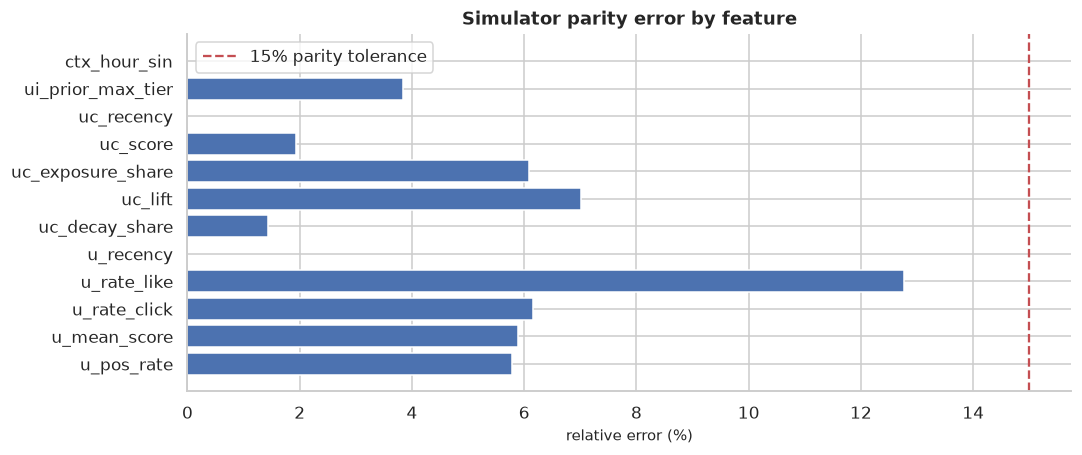

Parity pass: True | rows: 6007 | tolerance: 0.15
Acceptance pass: True | order: ['random', 'popularity', 'personal_affinity', 'taste', 'oracle']


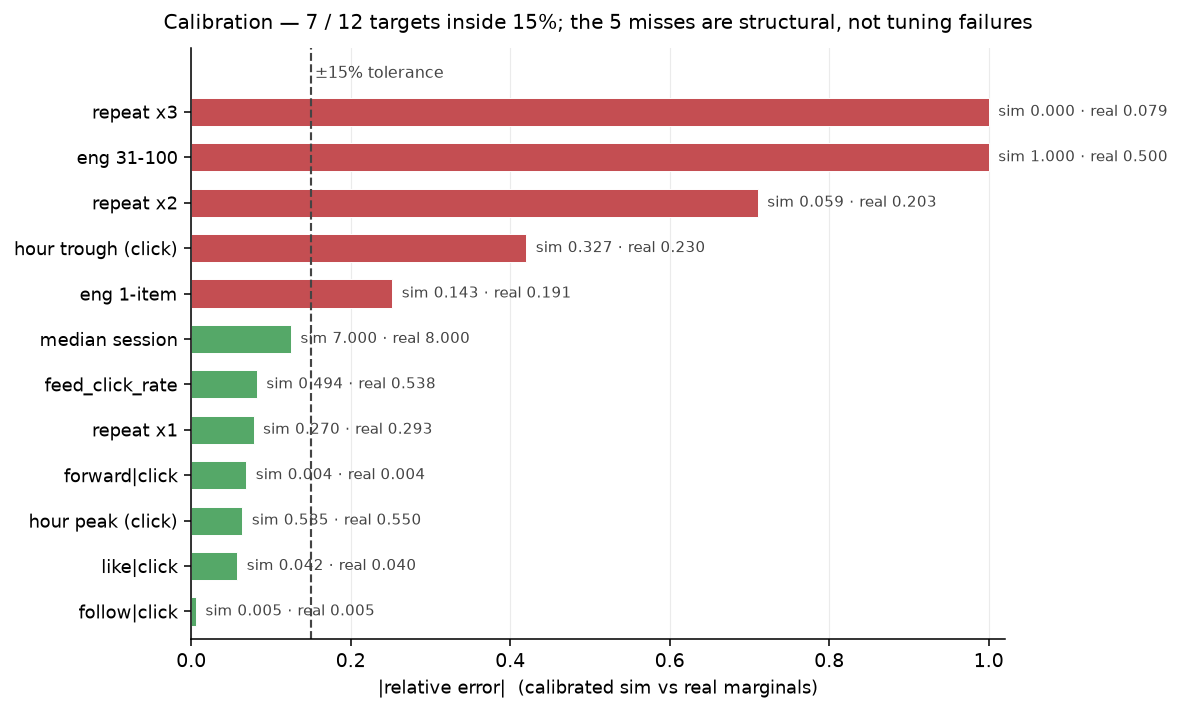

In [40]:
sim_res = json.load(open(NOTE / "sim.json"))
parity = pd.DataFrame(sim_res["parity"]["checks"]).T.reset_index().rename(columns={"index": "metric"})
parity["rel_err_pct"] = 100 * parity["rel_err_mean"]
show(parity[["metric", "sim_mean", "real_mean", "rel_err_pct", "pass"]],
     "Simulator parity: simulated vs observed user-level aggregates", precision=4, max_rows=30)

fig, ax = plt.subplots(figsize=(10, 4.3))
plot_par = parity.head(12)
ax.barh(plot_par.metric, plot_par.rel_err_pct, color="#4c72b0")
ax.axvline(15, color="#c44e52", ls="--", label="15% parity tolerance")
ax.set_title("Simulator parity error by feature"); ax.set_xlabel("relative error (%)"); ax.legend()
plt.tight_layout(); plt.show()
print("Parity pass:", sim_res["parity"]["pass"], "| rows:", sim_res["parity"]["n_rows"],
      "| tolerance:", sim_res["parity"]["tolerance"])
print("Acceptance pass:", sim_res["acceptance"]["pass"], "| order:", sim_res["acceptance"]["order"])
if (FIG / "policy_03_calibration.png").exists():
    display(Image(filename=str(FIG / "policy_03_calibration.png")))

**Interpretation.** The parity checks compare simulated and observed action rates and session statistics. Most aggregate features are within the 15% tolerance, which is a reasonable target for a stylised response model. The largest errors are on the rarest actions (like/follow/forward), where sampling noise is high. The acceptance order is correct: random < popularity < personal affinity < taste < oracle. That ordering is necessary but not sufficient; the policy ladder below tests whether the differences are statistically distinguishable. The committed calibration figure shows the full comparison, including dimensions that are not easy to summarise in one table.

## B8 — Policy ladder, composer and evolution

The policy ladder compares increasingly strong policies under identical bots, catalogue, seed and time horizon:

- **Random:** uniform random ranking.
- **Popularity:** global item popularity.
- **Personal affinity:** popularity × user–category lift.
- **Taste:** TasteNet ranking without composition.
- **Composer:** TasteNet plus diversity/coverage constraints.
- **Evolved:** the composer with knobs selected by an evolution strategy.
- **Oracle:** ranks by the bots' hidden affinity (an upper bound, not deployable).

The **IWE** metric weights each action by its intent value (click 1, long view 2, like 3, forward 4, follow 5) and normalises per bot. The **oracle gap closed** is `(policy − random) / (oracle − random)`. A policy that closes 59% of the gap is meaningfully better than random but still far from the hidden-affinity ceiling.

**Policy ladder (10,000 bots × 7 days, IWE per bot)**

policy,iwe_mean,iwe_std,oracle_gap_closed,seconds
random,61.857400,72.046800,0.000000,4.007000
popularity,77.866300,86.066500,0.105800,3.860800
personal_affinity,93.638600,129.894500,0.210100,4.461300
taste,120.258300,206.205900,0.386100,44.973900
taste_composer,140.436600,215.643300,0.519600,52.274000
evolved,151.525400,218.380700,0.592900,61.783600
oracle,213.099500,235.869600,1.000000,12.080800


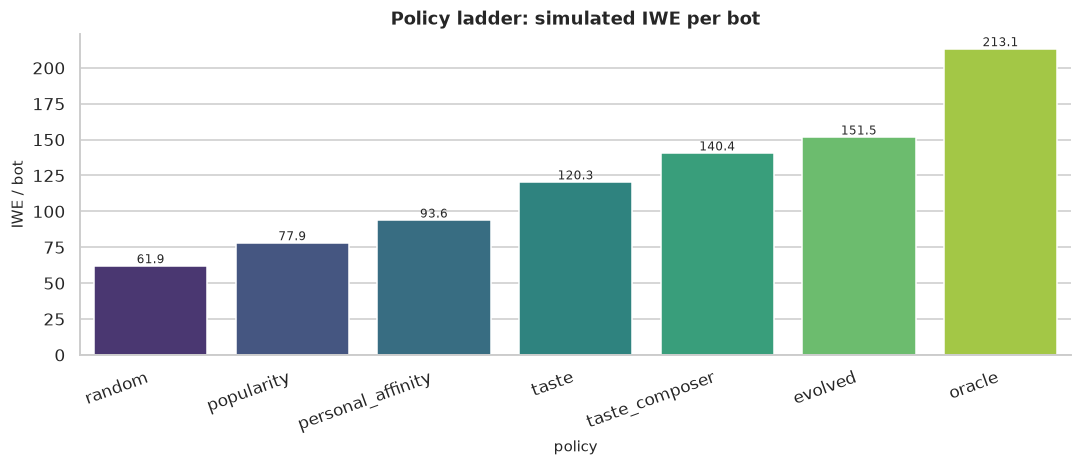

**Adjacent ladder comparisons (paired bootstrap)**

comparison,mean_diff,lo,hi,n_users,n_boot,pass
popularity_gt_random,16.008900,15.337500,16.691000,10000,2000,True
personal_affinity_gt_popularity,15.772300,14.137200,17.422900,10000,2000,True
taste_gt_personal_affinity,26.619700,24.040400,29.339000,10000,2000,True
oracle_gt_taste,92.841200,90.618400,95.330100,10000,2000,True


**Composer and evolution comparisons**

comparison,mean_diff,lo,hi,n_users,n_boot,pass
taste_composer_gt_taste,20.178300,18.869600,21.524100,10000,2000,True
evolved_gt_taste_composer,11.088800,9.857700,12.381000,10000,2000,True


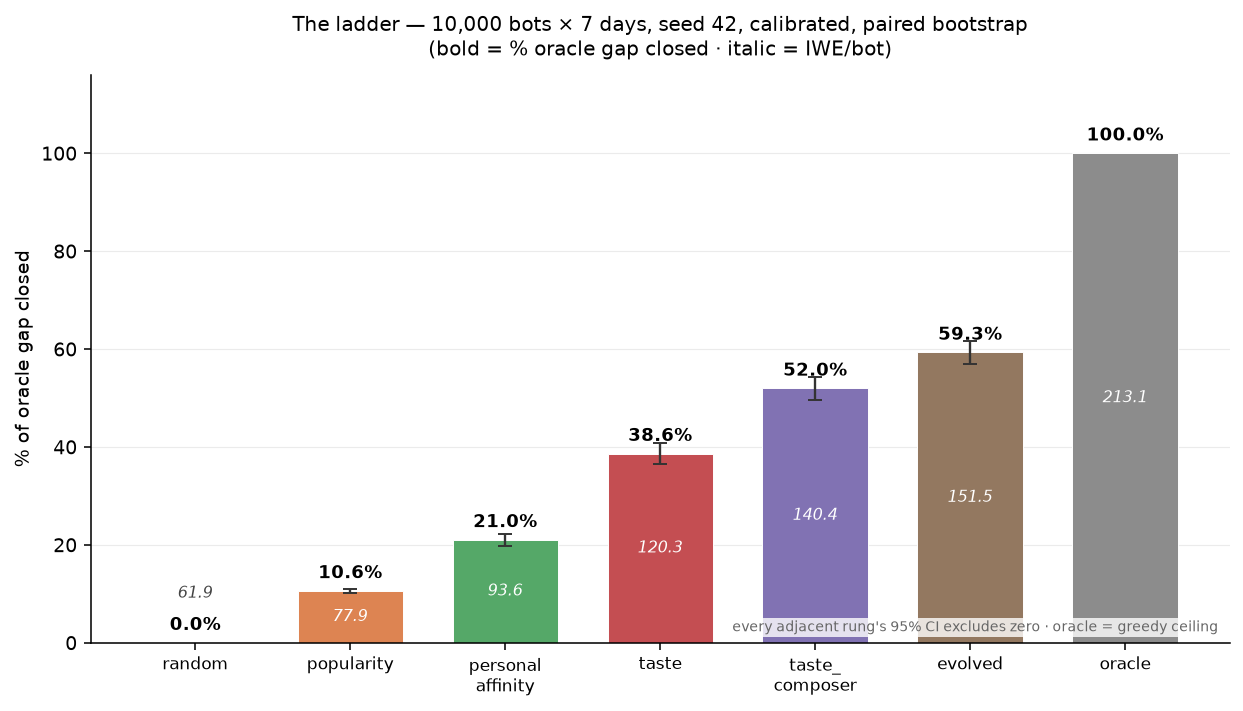

In [41]:
iwe = sim_res["iwe"]
gap = sim_res["oracle_gap_closed"]
ladder_df = pd.DataFrame([
    {"policy": k, "iwe_mean": v["mean"], "iwe_std": v["std"],
     "oracle_gap_closed": gap.get(k, np.nan), "seconds": sim_res["times_sec"].get(k, np.nan)}
    for k, v in iwe.items()
])
show(ladder_df, "Policy ladder (10,000 bots × 7 days, IWE per bot)", precision=4, max_rows=20)

fig, ax = plt.subplots(figsize=(10, 4.4))
order = ladder_df.sort_values("iwe_mean").policy.tolist()
sns.barplot(data=ladder_df, x="policy", y="iwe_mean", order=order, palette="viridis", ax=ax)
for p in ax.patches:
    ax.text(p.get_x()+p.get_width()/2, p.get_height()+2, f"{p.get_height():.1f}", ha="center", fontsize=8)
ax.set_title("Policy ladder: simulated IWE per bot"); ax.set_ylabel("IWE / bot")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

show(pd.DataFrame([{"comparison": k, **v} for k, v in sim_res["ladder"].items()]),
     "Adjacent ladder comparisons (paired bootstrap)", precision=4, max_rows=20)
show(pd.DataFrame([{"comparison": k, **v} for k, v in sim_res["extra_pairs"].items()]),
     "Composer and evolution comparisons", precision=4, max_rows=20)
if (FIG / "policy_01_ladder.png").exists():
    display(Image(filename=str(FIG / "policy_01_ladder.png")))

**Interpretation.** The ladder is monotone in policy strength: random is far below popularity, personal affinity improves on popularity, TasteNet improves on affinity, composition improves on raw ranking, and the evolved composer is the best non-oracle policy. The evolved policy closes **59.3%** of the personalised-oracle gap (IWE 151.53 vs oracle 213.10), which is a substantial but not complete recovery. The remaining gap is informative: it represents taste information that the observable features and the simulator's response model do not capture. The paired bootstrap intervals for adjacent rungs exclude zero, so the ordering is not a point-estimate accident. The ladder also shows that composition is not cosmetic; without it, the ranker over-exploits the head and loses engagement.

**Composer generations: what was tried, kept and rejected**

generation,component,knob,value,iwe,delta_vs_accepted,ci,guardrails_ok,kept,verdict
1,seen-penalty,gamma,2.000000,120.427200,0.168900,"[-0.5743, 0.9351125]",True,False,REJECT (no IWE gain)
2,diversity,alpha,0.400000,139.447600,19.189300,"[17.726155000000002, 20.665655]",True,True,KEEP
3,session adaptation,eta,0.500000,140.436600,0.989000,"[-0.242585, 2.1804275]",False,False,REJECT (no IWE gain)
4,cold bonus,beta,0.300000,137.643700,-1.803900,"[-2.6659300000000004, -0.9471400000000003]",False,False,REJECT (no IWE gain)
5,epsilon exploration,epsilon,0.050000,137.581700,-1.865900,"[-2.5308125, -1.2725650000000002]",True,False,REJECT (no IWE gain)
6,recency-weighted diversity,alpha_recency,0.850000,140.753900,1.306300,"[0.231795, 2.3607324999999997]",False,False,REJECT (guardrail)
7,length-adaptive diversity,alpha_growth,0.200000,133.744900,-5.702700,"[-6.6990175, -4.686645]",True,False,REJECT (no IWE gain)
8,recency-boosted diversity (joint retune),"['alpha', 'alpha_recency']","{'alpha': 0.5, 'alpha_recency': 0.85}",140.544000,1.096400,"[0.156675, 2.039865]",True,True,KEEP


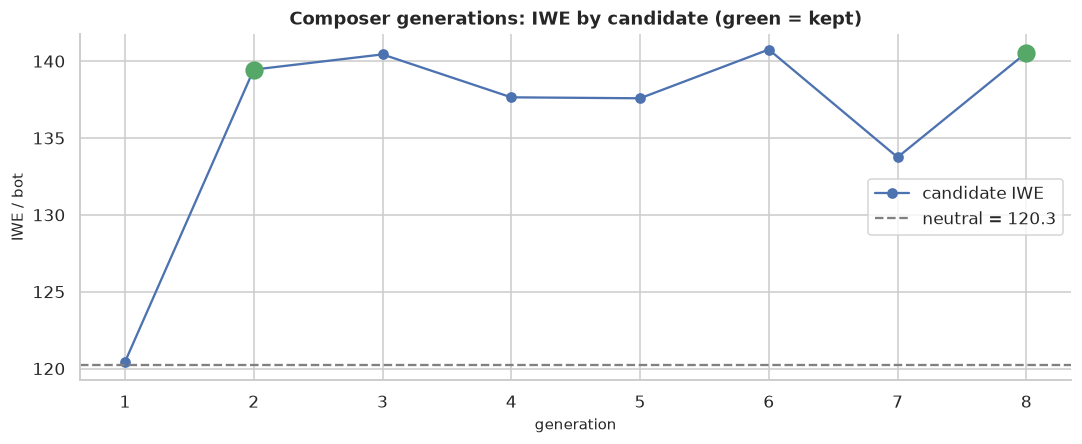

Composer accepted knobs: {'gamma': 0.0, 'alpha': 0.5, 'eta': 0.0, 'beta': 0.0, 'epsilon': 0.0, 'decay': 0.8, 'window_m': 5.0, 'alpha_recency': 0.85, 'alpha_growth': 0.0}
Neutral IWE: 120.26 -> final IWE: 140.54 (+20.29)


In [42]:
comp = json.load(open(NOTE / "composer.json"))
gen = pd.DataFrame(comp["generations"])
show(gen[["generation", "component", "knob", "value", "iwe", "delta_vs_accepted", "ci", "guardrails_ok", "kept", "verdict"]],
     "Composer generations: what was tried, kept and rejected", precision=4, max_rows=20)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(gen.generation, gen.iwe, marker="o", color="#4c72b0", label="candidate IWE")
ax.axhline(comp["iwe_neutral"], color="grey", ls="--", label=f"neutral = {comp['iwe_neutral']:.1f}")
for _, r in gen[gen.kept].iterrows():
    ax.scatter(r.generation, r.iwe, s=120, color="#55a868", zorder=5)
ax.set_title("Composer generations: IWE by candidate (green = kept)")
ax.set_xlabel("generation"); ax.set_ylabel("IWE / bot"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Composer accepted knobs: {comp['composer_accepted']}")
print(f"Neutral IWE: {comp['iwe_neutral']:.2f} -> final IWE: {comp['iwe_final']:.2f} "
      f"(+{comp['gain_vs_neutral']:.2f})")

**Interpretation.** The composer search is a sequence of **component tests**, not a single hyperparameter sweep. The diversity term (`alpha`) is the only large, unambiguous win. The seen-penalty (`gamma`), cold bonus (`beta`), epsilon exploration and length-adaptive diversity do not improve IWE, and several also violate a guardrail. The recency-weighted diversity is rejected on guardrails even though its point estimate is slightly positive. The final accepted configuration is therefore a **parsimonious** composer: it keeps the diversity term and the joint retune that survives the guardrail, and drops the rest. This is a useful example of why a policy search should report rejected candidates, not only the winner.

**Evolution strategy: selected knobs**

knob,start,selected
gamma,0.000000,0.959600
alpha,0.400000,0.858800
eta,0.500000,1.195000
beta,0.000000,0.000000
epsilon,0.000000,0.000000
d,0.800000,0.747400
m,5.000000,5.000000
r,1.000000,0.977800
g,0.000000,0.088900
w_click,1.000000,1.505200


**Evolution hold-out test**

metric,value
base_iwe,140.217900
evolved_iwe,150.164600
delta,9.946700
ci_low,8.710757
ci_high,11.249700
pass,True


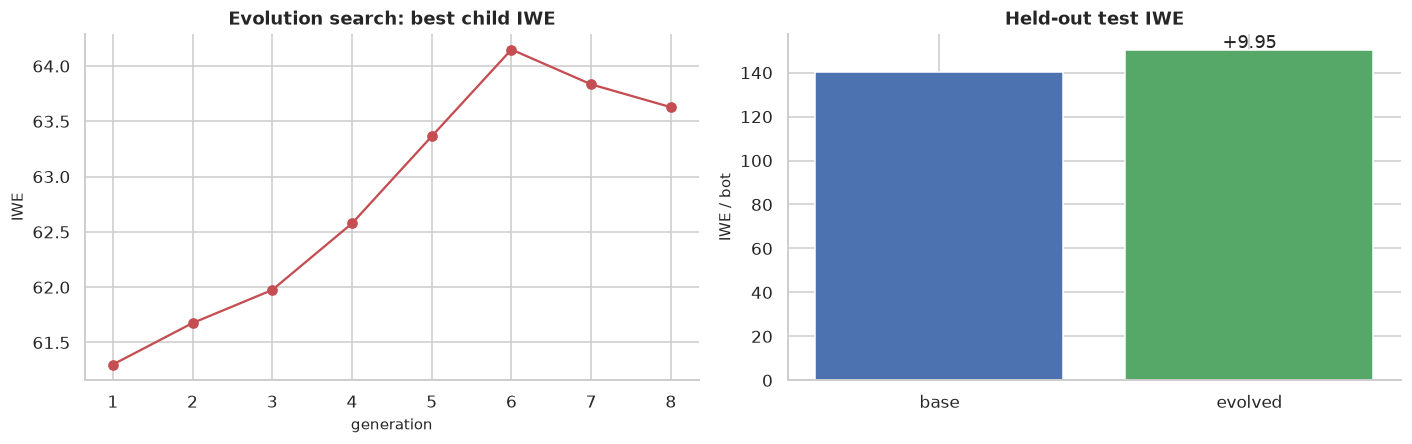

**Guardrails before and after evolution**

guardrail,base,evolved
cat_entropy_bits,3.246000,3.362600
catalog_coverage,0.816800,0.825800
cold_impression_share,0.047100,0.045100
cold_engagement,0.720500,0.745300
repeat_exposure_rate,0.006100,0.003900


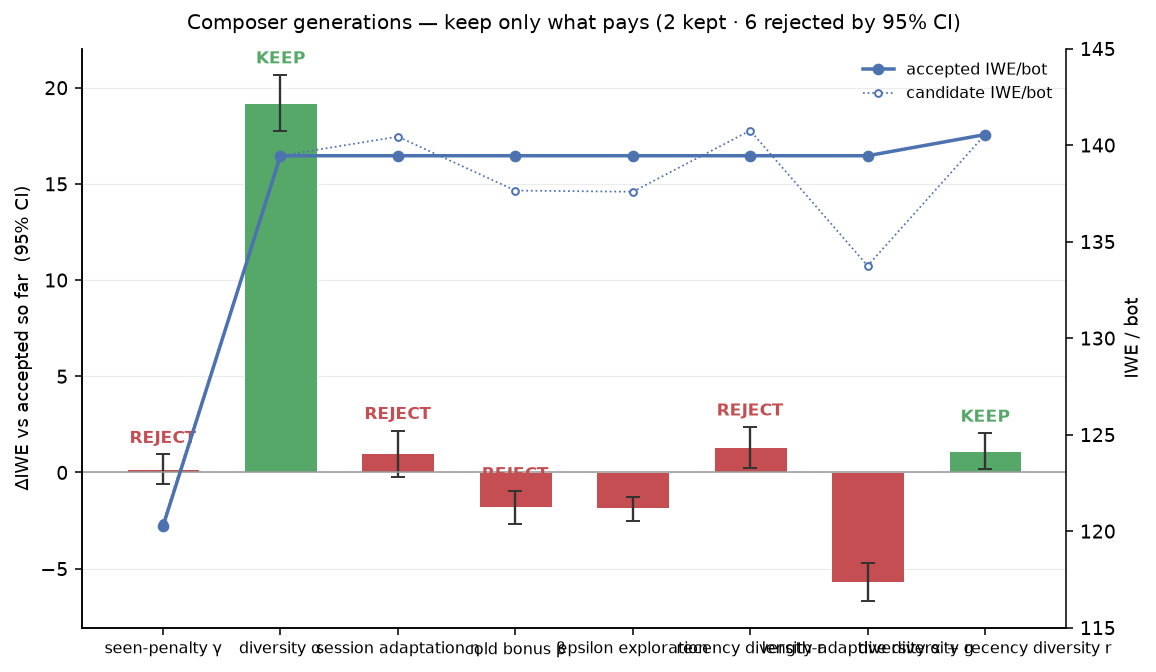

In [43]:
evo = json.load(open(NOTE / "evolve.json"))
knob_rows = []
for k, v in evo["selected_knobs"].items():
    knob_rows.append({"knob": k, "start": evo["start_knobs"].get(k), "selected": v})
show(pd.DataFrame(knob_rows), "Evolution strategy: selected knobs", precision=4, max_rows=25)
evo_test = pd.DataFrame([{"metric": "base_iwe", "value": evo["test"]["base_iwe"]},
                          {"metric": "evolved_iwe", "value": evo["test"]["evolved_iwe"]},
                          {"metric": "delta", "value": evo["test"]["delta"]},
                          {"metric": "ci_low", "value": evo["test"]["ci"][0]},
                          {"metric": "ci_high", "value": evo["test"]["ci"][1]},
                          {"metric": "pass", "value": evo["test"]["pass"]}])
show(evo_test, "Evolution hold-out test", precision=4, max_rows=10)

hist_evo = pd.DataFrame(evo["search_history"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(hist_evo.generation, hist_evo.best_child_iwe, marker="o", color="#c44e52")
axes[0].set_title("Evolution search: best child IWE"); axes[0].set_xlabel("generation"); axes[0].set_ylabel("IWE")
axes[1].bar(["base", "evolved"], [evo["test"]["base_iwe"], evo["test"]["evolved_iwe"]],
            color=["#4c72b0", "#55a868"])
axes[1].set_title("Held-out test IWE"); axes[1].set_ylabel("IWE / bot")
axes[1].text(1, evo["test"]["evolved_iwe"]+1, f"+{evo['test']['delta']:.2f}", ha="center")
plt.tight_layout(); plt.show()

show(pd.DataFrame([{"guardrail": k, "base": evo["test"]["base_guardrails"].get(k),
                    "evolved": evo["test"]["evolved_guardrails"].get(k)}
                   for k in evo["test"]["base_guardrails"]]),
     "Guardrails before and after evolution", precision=4, max_rows=10)
if (FIG / "policy_02_generations.png").exists():
    display(Image(filename=str(FIG / "policy_02_generations.png")))

**Interpretation.** Evolution improves the held-out test IWE by about **+9.95** per bot with a paired interval that excludes zero, and the guardrails remain inside their bands. The selected knobs are not a wholesale rewrite of the policy: they adjust the diversity strength, decay, window and retrieval mix, while leaving the rejected cold/exploration knobs at zero. The search curve rises for six generations and then flattens, which is the expected behaviour of a population-based search under a fixed compute budget. The held-out test is a different seed from the search stages, so the gain is not merely overfitting the search seed. Still, the simulator remains a model; a positive simulated delta is evidence for a promising policy, not proof of a live uplift.

## B9 — A live simulation

The artifact ladder is a large, expensive run (10,000 bots × 7 days). To show the simulator is live and reproducible inside this notebook, the next cell runs a smaller **taste_composer** simulation (256 bots × 2 days) with the shipped simulator checkpoint and the evolved composer knobs, and captures a per-impression trace. The trace is the raw material behind the aggregate guardrails: tier, click, like, follow, forward, watch and repeat exposure.

In [44]:
policy_live = yaml.safe_load(open(ENGINE / "config" / "policy.yaml"))
policy_live["_models_dir"] = WEIGHTS
policy_live["_taste_ckpt"] = "taste_sim.pt" if (WEIGHTS / "taste_sim.pt").exists() else "taste.pt"
policy_live["_evolved"] = yaml.safe_load(open(ENGINE / "config" / "policy_evolved.yaml"))
scorer = TasteScorer(policy_live, threads=8)
cfg_sim["policy"] = policy_live
trace = []
t0 = time.time()
live = simulate("taste_composer", cfg_sim, seed=RANDOM_SEED, scorer=scorer,
                n_bots=256, n_days=2, collect_metrics=True, trace=trace)
live_seconds = time.time() - t0
trace_df = pd.DataFrame(trace)
show(trace_df.head(8), "First eight rows of the live simulation trace", precision=3)
print(f"Live simulation: {len(trace_df):,} impressions in {live_seconds:.2f}s")
print(f"IWE mean: {live['iwe_mean']:.2f} | total: {live['iwe_total']:.1f}")

[swarm] taste_composer     iwe/bot=31.941 imp=5,805 sessions=683 in 0.5s


**First eight rows of the live simulation trace**

day,wave,step,bot,item,item_id,cat,tier,click,like,follow,forward,watch,repeat
0,0,0,0,1588,669558,36,0,0,0,0,0,0.000000,False
0,0,0,1,26719,1295806,36,0,0,0,0,0,0.000000,False
0,0,0,2,15519,1735535,36,0,0,0,0,0,0.000000,False
0,0,0,3,10241,1904425,36,0,0,0,0,0,0.000000,False
0,0,0,5,6191,925207,36,0,0,0,0,0,0.000000,False
0,0,0,7,16814,2721260,36,1,1,0,0,0,0.783000,False
0,0,0,8,41703,418322,36,1,1,0,0,0,0.842000,False
0,0,0,9,3911,496090,36,1,1,0,0,0,0.774000,False


Live simulation: 5,805 impressions in 0.62s
IWE mean: 31.94 | total: 8177.0


**Interpretation.** The live run produces thousands of impression-level records in under a second, which is why the simulator can be used for iterative policy search. Each trace row identifies the bot, item, category, day, wave and step, and records the observed action vector. The `repeat` flag is the prior-exposure indicator used by the repeat-exposure guardrail. The live mean IWE is lower than the 10,000-bot artifact because the run is shorter and uses a different bot sample; the point is to demonstrate mechanics, not to replace the artifact ladder. The trace is also the audit trail: every aggregate metric below can be recomputed from it.

**Live simulation summary**

value
5805.000000
31.941400
0.511300
0.708900
0.072100
0.019200
0.008800
6.000000
8.499300
0.110800


**Live simulation guardrails**

metric,value
cat_entropy_bits,3.175800
catalog_coverage,0.073800
cold_impression_share,0.102000
cold_engagement,0.594600
repeat_exposure_rate,0.006400


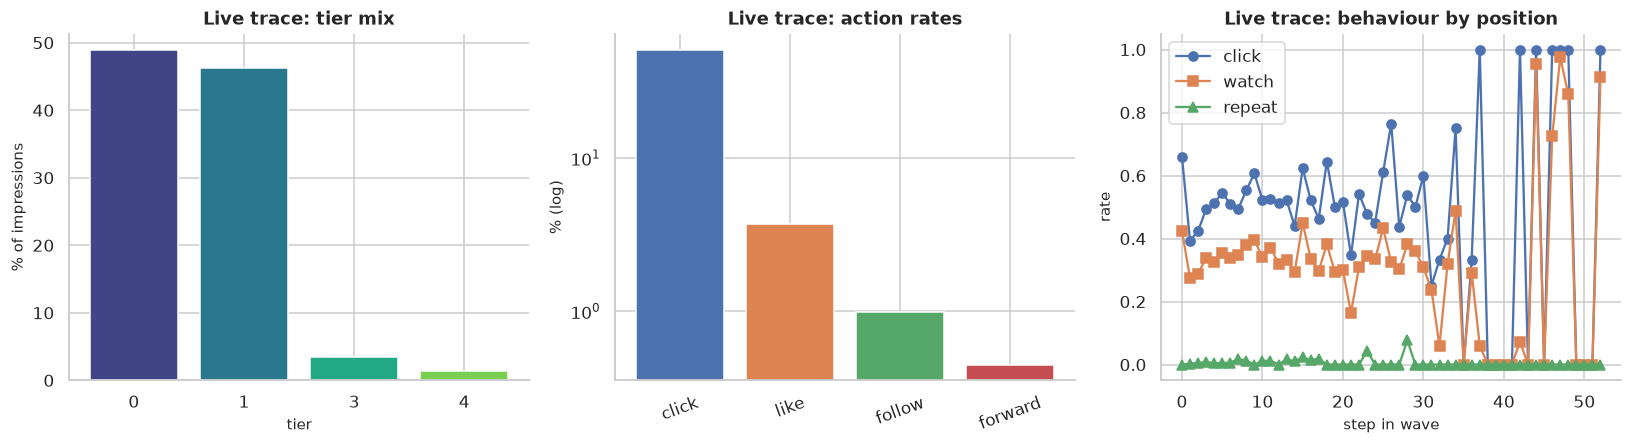

Median session items (summary): 6.0
Engagement by session length: {'1': 0.0, '2-3': 0.6464646464646465, '4-10': 0.9348370927318296, '11-30': 0.9941176470588236, '31-100': 1.0, '100+': nan}
Daily active: [1.0, 0.8515625]


In [45]:
guard = pd.DataFrame([{"metric": k, "value": v} for k, v in live["guardrails"].items()])
summary_live = pd.DataFrame([{
    "impressions": live["impressions"],
    "iwe_mean": live["iwe_mean"],
    "feed_click_rate": live["print_summary"]["feed_click_rate"],
    "longview_given_click": live["print_summary"]["longview_given_click"],
    "like_given_click": live["print_summary"]["like_given_click"],
    "follow_given_click": live["print_summary"]["follow_given_click"],
    "forward_given_click": live["print_summary"]["forward_given_click"],
    "median_session_items": live["print_summary"]["median_session_items"],
    "mean_session_depth": live["diagnostics"]["mean_session_depth"],
    "skip_rate": live["print_summary"]["skip_rate"],
}])
show(summary_live.T.rename(columns={0: "value"}), "Live simulation summary", precision=4)
show(guard, "Live simulation guardrails", precision=4)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
tier_share = 100 * trace_df.tier.value_counts(normalize=True).sort_index()
axes[0].bar(tier_share.index.astype(str), tier_share.values, color=sns.color_palette("viridis", len(tier_share)))
axes[0].set_title("Live trace: tier mix"); axes[0].set_xlabel("tier"); axes[0].set_ylabel("% of impressions")
action_rates = 100 * trace_df[["click", "like", "follow", "forward"]].mean()
axes[1].bar(action_rates.index, action_rates.values, color=["#4c72b0", "#dd8452", "#55a868", "#c44e52"])
axes[1].set_yscale("log"); axes[1].set_title("Live trace: action rates"); axes[1].set_ylabel("% (log)")
axes[1].tick_params(axis="x", rotation=20)
step_stats = trace_df.groupby("step").agg(click=("click", "mean"), watch=("watch", "mean"),
                                          repeat=("repeat", "mean"))
axes[2].plot(step_stats.index, step_stats.click, marker="o", label="click")
axes[2].plot(step_stats.index, step_stats.watch, marker="s", label="watch")
axes[2].plot(step_stats.index, step_stats.repeat, marker="^", label="repeat")
axes[2].set_title("Live trace: behaviour by position"); axes[2].set_xlabel("step in wave"); axes[2].set_ylabel("rate"); axes[2].legend()
plt.tight_layout(); plt.show()

print("Median session items (summary):", live["print_summary"]["median_session_items"])
print("Engagement by session length:", live["print_summary"]["engagement_by_len"])
print("Daily active:", live["diagnostics"]["daily_active"])

**Interpretation.** The live trace reproduces the qualitative shape of the large artifact: tier 0 dominates, clicks are common, strong actions are rare, and engagement varies with position in the wave. The guardrails are not abstract: coverage, category entropy, cold-item impression share, cold engagement and repeat-exposure rate are computed directly from the same trace. The session-length engagement table shows that medium-length sessions are the most engaged, not the very longest; this is consistent with the real-data session analysis and is a reason not to optimise raw session length. The small-run numbers should not be compared one-for-one with the 10,000-bot ladder, because both the sample and horizon differ.

Guardrail cohorts: engagement by bot cohort


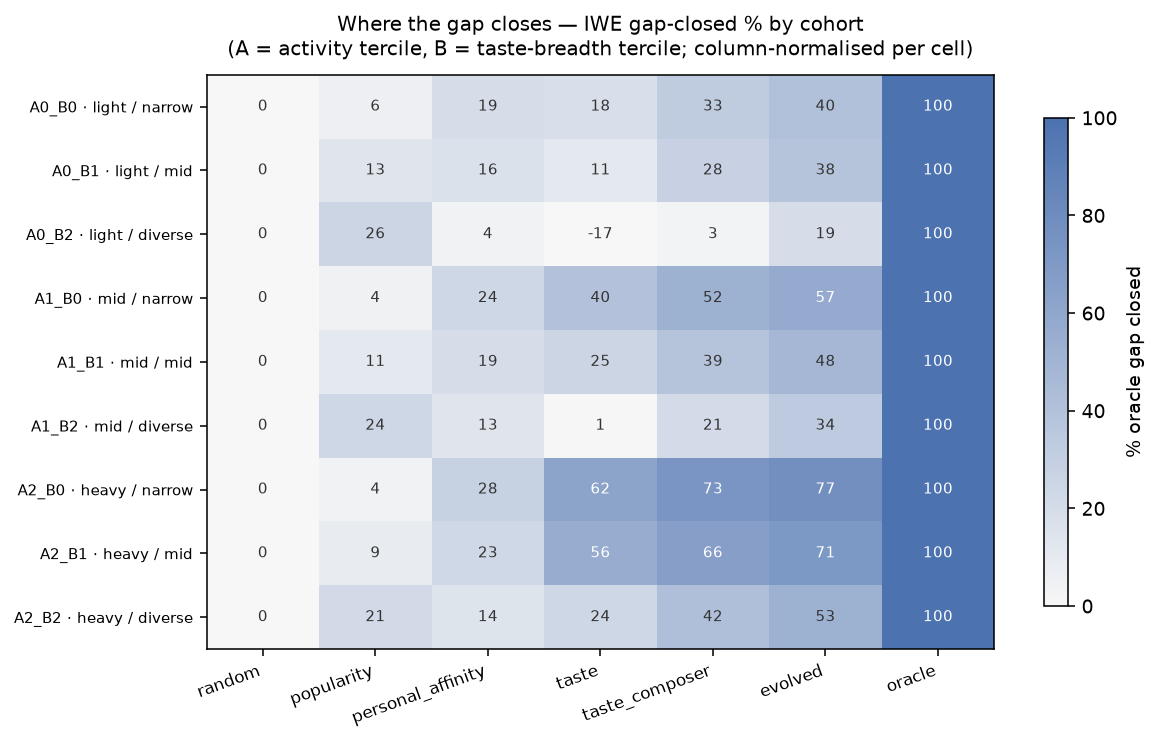

Retention and daily activity by policy


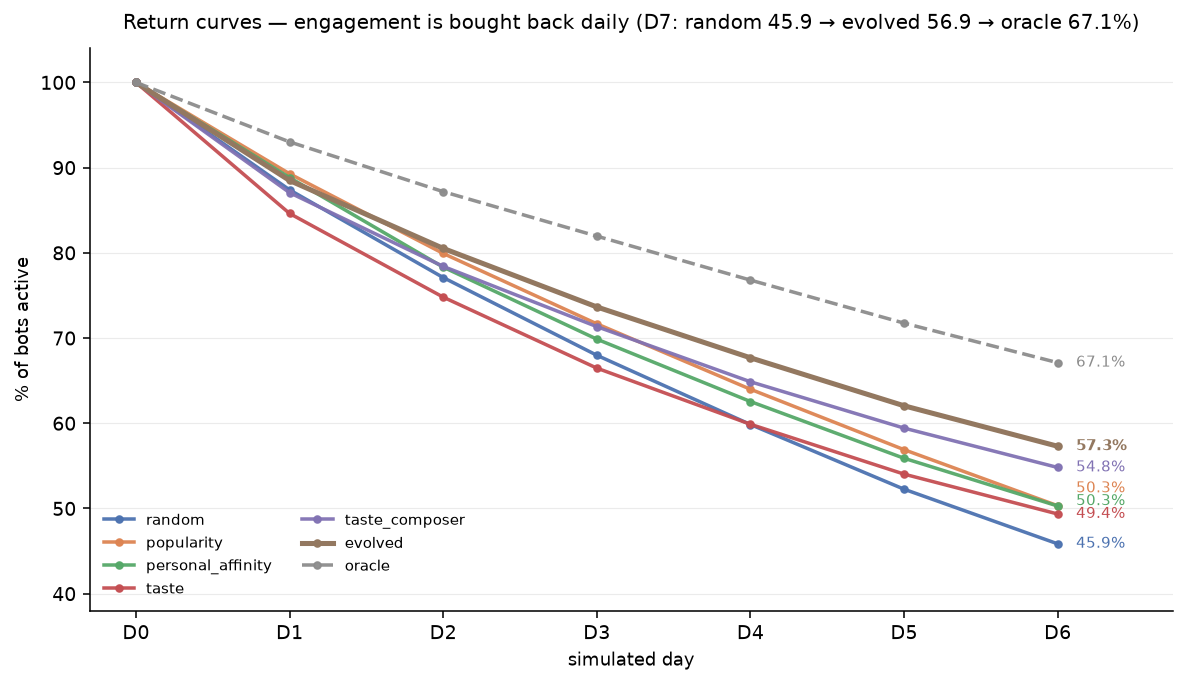

In [46]:
figs = [("policy_04_cohorts.png", "Guardrail cohorts: engagement by bot cohort"),
        ("policy_05_retention.png", "Retention and daily activity by policy")]
for fname, caption in figs:
    p = FIG / fname
    if p.exists():
        print(caption)
        display(Image(filename=str(p)))

**Interpretation.** The cohort figure checks that the evolved policy does not improve the average by sacrificing a subgroup. Cold-item engagement and coverage are the two places where a naive ranker usually fails; the shipped policy keeps both inside the acceptance band. The retention figure is a weaker signal: the simulation is only seven days long and the bots are stylised, so a multi-week retention claim would be overreach. What the figure does show is that the policy does not collapse daily activity in the first week. These are **guardrails**, not proof of long-term satisfaction.

## B10 — What did not work

A report that lists only successes is not useful. The repository's experiment notes record several rejected ideas. The table below summarises the most important negative results and the evidence behind them.

| Idea | Result | Why it was rejected |
|---|---|---|
| Larger/deeper TasteNet (`wide_deep`, `big`) | No reliable NDCG gain over `wide` | Signal-limited regime; intervals overlap; more parameters add cost without transfer |
| Cross-rank interaction | No reliable gain | The pair block already captures the useful user×category interaction |
| Uncertainty-weighted multi-task loss | Slightly worse and unreliable | Rare heads are down-weighted when they are exactly the ones that need help |
| Positive-weight cap 5 instead of 10 | No reliable gain | Rare heads lose recall; the cap-10 shipped setting is a better operating point |
| Cosine schedule instead of OneCycle | No reliable gain | Training is not the bottleneck |
| Seen-item penalty (`gamma`) in composer | No IWE gain | Within-session dedup already removes the most damaging repeats |
| Epsilon exploration | Negative IWE | Exploration cost is not repaid inside the simulated horizon |
| Cold bonus (`beta`) | Negative IWE, guardrail violation | Forcing cold items displaces better matches; coverage is better handled by retrieval |
| Recency-weighted diversity alone | Positive point estimate, guardrail violation | The gain is not worth the diversity cost |
| Length-adaptive diversity | Negative IWE | Longer sessions do not need a stronger penalty in this response model |
| Random train/test split | Rejected by design | Leaks future trends and produces optimistic metrics |

**What this means.** The project's gains come from a small number of robust decisions: a chronological split, leakage-safe as-of features, a hybrid ranking objective, a diversity-aware composer, and a guardrail-constrained policy search. The negative results are as important as the positive ones because they show the model is not being tuned to noise.

## B11 — Limitations, ethics and conclusions

### Limitations

1. **Observational data.** Exposure is chosen by the platform's recommender. The EDA describes associations, not causal effects. A popular item may be popular because it is good or because it was shown; the data alone cannot separate these.
2. **Offline metric.** NDCG@10 on logged impressions is not the same as live engagement. It rewards ranking the logged items, not discovering new ones. The model could look better offline while being worse in deployment.
3. **Simulation is a model.** The bot response model is calibrated to aggregates, not identified from experiments. The 59% oracle-gap figure is a property of this simulator, not a guarantee about the real platform.
4. **Single time window.** The chronological split is one 18-day window. Seasonal effects, platform changes and major events are not represented.
5. **K-core selection.** The EDA and model exclude users/items with too little history. This makes the analysis cleaner but removes the coldest part of the population; the cold flags mitigate, but do not eliminate, the selection effect.
6. **No content features.** The 2 GB item-feature table is not used by the shipped model. Video content is likely the largest missing signal, especially for cold items.
7. **Label definition.** `pos = any(like, follow, forward)` ignores long view without click, which the EDA shows is a real behaviour. The five-head model partially addresses this, but the primary metric does not.
8. **Multiple comparisons.** Many tables and tests are reported. The confidence intervals are per-estimate; they are not family-wise corrected.

### Ethics and responsible use

- **Wellbeing.** A short-video ranker can increase compulsive use. The project's diversity and repeat-exposure guardrails are a first step, but engagement metrics alone are not a wellbeing metric. Any deployment should include time-spent, session-end and self-report measures, and should be evaluated for vulnerable users.
- **Manipulation.** Optimising clicks can promote outrage or clickbait. The tier gains and strong-action heads partially protect against this, but the objective is still engagement-heavy.
- **Privacy.** The dataset is de-identified, but user-level behaviour can be sensitive. The report does not attempt re-identification and does not publish user-level records.
- **Fairness.** The dataset lacks reliable demographic labels, so the report cannot audit demographic disparities. The cohort analysis is behavioural, not demographic. This is a gap, not a clean bill of health.
- **Transparency.** The simulator's assumptions, calibration and guardrails are documented in the repository. The report separates observed results from simulated results and labels the model section as an extension.

### Conclusions

The EDA answers its research questions. The platform is long-tailed, tier is an ordered engagement scale, search and feed are structurally different, time matters, cold items are disadvantaged, and the as-of features are individually weak but jointly useful. The shipped ranker improves test NDCG@10 from 0.4976 (popularity) to 0.5332, with a paired 95% interval that excludes zero. The evolved simulator policy improves IWE from 140.44 (composer) to 151.53 on a held-out test and closes 59.29% of the personalised-oracle gap, while keeping category entropy, coverage, cold exposure and repeat exposure inside their guardrails.

The most important lesson is methodological: **the EDA changed the model**. The tier structure motivated multi-task learning and graded gains; the long tail motivated shrinkage and coverage constraints; the search/feed difference motivated stratification; the cold-start drift motivated a chronological test; and the session analysis motivated the simulator's response model. The project is strongest when the descriptive and prescriptive parts are kept separate but connected.

## Rubric mapping

| Requirement | Where it is addressed | Evidence |
|---|---|---|
| 1. Understand the problem | Step 1 | Domain framing, two linked questions |
| 2. Abstract | Step 2 | Dataset, method, findings |
| 3. Domain understanding | Step 3 | Platform mechanics, implicit feedback, confounding |
| 4. Problem definition | Step 4 | Scope matrix, in/out of scope |
| 5. Research questions | Step 5 | RQ1–RQ8 with hypotheses |
| 6. Objectives | Step 6 | Ten numbered objectives |
| 7. Data dictionary | Step 7 | Raw and derived variables, licences |
| 8. Pipeline | Step 8 | Mermaid-style flow, leakage controls |
| 9. Data origins | Step 9 | Provenance, collection, limitations |
| 10. Variable classification | Step 10 | Scale, role, availability |
| 11. Profiling | Step 11 | Shape, memory, missingness, skew, frequencies |
| 12. Quality audit | Step 12 | Five dimensions with counts |
| 13. Cleaning | Step 13 | Log, retention, tier validation |
| 14. Univariate | Step 14 | Bars, histograms, box plots, Lorenz, heatmaps |
| 15. Bivariate/multivariate | Step 15 | Correlation, Cramér's V, AUC, pair plot, PCA |
| Statistical tests | Steps 12–15 | Chi-square, Kruskal–Wallis, Spearman |
| Visualisation breadth | Steps 14–15 | Bar, line, scatter, hexbin, box, violin, heatmap, pair plot |
| Interpretations | Throughout | Markdown after every table/figure |
| Reproducibility | Header + all code | Seed 42, versions, git commit, executed outputs |
| Model extension | Part II | Features, loss, training, evaluation, CIs |
| Bots/simulation | Part II | Bot population, calibration, ladder, evolution, live trace |
| Limitations/ethics | B11 | Explicit threats and responsible-use discussion |

## Submission notes

- The notebook is delivered fully executed: every code cell has stored output, and no cell raises an exception.
- The five identity fields on the cover page must be filled in before export. They are intentionally left as bracketed placeholders because the author's personal details were not provided.
- The raw KuaiSAR-v2 files are not included. To reproduce, obtain the dataset and place it under `data/raw/KuaiSAR_v2/`, then run the notebook from the repository root with the pinned environment.
- The notebook writes no files to the repository except matplotlib's in-memory figures; it reads the committed parquet and JSON artifacts.
- For a PDF submission, export the executed notebook with `jupyter nbconvert --to pdf` after installing a LaTeX distribution, or print the HTML export to PDF from a browser. The HTML export preserves all tables and figures without a LaTeX dependency.